# Churn en Conecta+ — ¿a quién contactar en los próximos 90 días y por qué se van?

**Prueba técnica de Ciencia de Datos (nivel Senior)** · Fecha de los datos: **31-12-2025**

Este notebook cuenta la solución de principio a fin y se ejecuta completo en Google Colab.

## Índice

| Sección | Qué responde |
|---|---|
| [1. Contexto y supuestos](#s1) · *incluye la celda de parámetros* | El problema, los supuestos económicos y lo único que hace falta tocar para cambiarlos |
| [2. Calidad de datos](#s2) | Qué significa "cancelar", problemas de cada fuente y qué decidí con cada uno |
| [3. Exploración enfocada](#s3) | Dónde se concentra la cancelación y evidencia de la fuga del CRM |
| [4. Features al corte](#s4) | Variables con solo lo que se sabía cada día de corte, y la prueba anti-fuga |
| [5. Modelos](#s5) | Economía de la decisión, validación, comparación de modelos y elección |
| [6. Decisión de negocio](#s6) | A quién contactar el 31-12-2025, valor esperado, sensibilidad y `predicciones.csv` |
| [7. Datos no estructurados](#s7) | Cuánto aportan los tickets y el uso de la app (ablación) |
| [8. Hallazgo abierto](#s8) | La versión 5.2.0 de la app en iOS: evidencia, impacto, cautelas y acción |
| [9. Producción](#s9) · *y estado final* | Reentrenamiento, monitoreo y qué me haría desconfiar |

## Ruta de lectura rápida (10–15 minutos)

- **Núcleo, léelo en este orden:** sección 1 (supuestos y parámetros) → 2.6 (resumen de calidad de datos) → 4.7 (prueba anti-fuga) → 5.1 y 5.8 (economía de la decisión y elección del modelo) → **6** (a quién contactar, valor y sensibilidad) → **8** (hallazgo de la 5.2.0) → 9 (producción).
- **Detalle, para consultar si quieres comprobar algo:** 2.1–2.5 (limpieza fuente por fuente), 3 (exploración), 4.1–4.5 (definición de cada variable), 5.4–5.7 (validaciones, calibración y subgrupos) y 7 (tickets y uso de la app).
- **La decisión más discutible** es dejar fuera del modelo final las variables de la 5.2.0: está contada con sus dos pasos en 5.3, 5.3 bis y 5.3 ter, con la tabla «con / sin» en 6.1.

**Glosario mínimo.** *Corte*: día en que se «toma la foto» de un cliente (solo se usa lo que se sabía ese día). *PR-AUC*: qué tan arriba quedan en la lista los que sí cancelan (con 12,8 % de cancelaciones, un azar puro daría ≈ 0,13). *Calibración*: que «20 %» signifique que 2 de cada 10 cancelan; *ECE*: el error medio de esa calibración (menor es mejor). *HGB* (HistGradientBoosting): un modelo de árboles que se corrigen unos a otros. *Bootstrap*: repetir el cálculo con clientes remuestreados para obtener un intervalo de confianza. *Leakage* (fuga): usar un dato que no se conocía al corte.

**Cómo ejecutarlo:** sube `datos_conecta.zip` al panel de archivos de Colab (o monta Drive y cambia `RUTA_ZIP` en la primera celda de código) y ejecuta todo con *Entorno de ejecución → Ejecutar todo*. Solo usa librerías que ya trae Colab.


<a id="s1"></a>

## 1. Contexto y supuestos

**Problema.** Conecta+ vende suscripciones (Básico, Estándar, Premium, Familiar) a clientes Personales y Pymes. La cancelación ha crecido. Hay que responder dos preguntas:
1. *¿A quién contactar?* Estimar la probabilidad de que cada cliente activo cancele en los próximos 90 días y decidir a quién se le ofrece retención.
2. *¿Por qué se van?* Un hallazgo que la gerencia debería conocer.

**Economía de la decisión (dada en el enunciado).**

| Supuesto | Valor |
|---|---|
| Costo de contactar a un cliente | 25.000 COP |
| Probabilidad de que la oferta retenga a quien iba a cancelar | 40 % |
| Valor de retener | 12 meses de la mensualidad actual (precio vigente) |
| Contactar a quien no iba a cancelar | se pierde el costo del contacto |
| Precios vigentes | Básico 23.900 · Estándar 34.900 · Premium 49.900 · Familiar 59.900 COP |

**Definiciones que adopto** (cada una se verifica contra los datos en la sección 2):
- **Cancelar** = una suscripción que termina **sin** ser un cambio de plan (`motivo_cancelacion != 'cambio_plan'`).
- **Foto al corte:** para un corte `c`, solo se puede usar lo que se *conocía* al cierre del día `c`. Es la regla central contra las fugas de información.
- **Hora:** todo se lleva a hora de Colombia (UTC−5) antes de compararlo con fechas de corte.

### Parámetros: lo único que hace falta tocar para cambiar un supuesto

Todo lo que se puede querer cambiar está en **una sola celda** (la siguiente). Qué volver a ejecutar después de cambiar cada cosa:

| Si cambias… | Vuelve a ejecutar |
|---|---|
| `COSTO_CONTACTO`, `EFECTIVIDAD`, `MESES_VALOR`, `PRECIO_VIGENTE` o `UMBRAL_FIJO` | La celda de **5.1 (economía)** y **toda la sección 6** (6.1 a 6.4). Con eso se rehace la decisión, la sensibilidad y `predicciones.csv`. |
| `MODELO_FINAL` o `EXCLUIR_EXTRA` | **Toda la sección 6** (el modelo se reentrena allí). |
| `INCLUIR_5_2_0` (`True` = el modelo final lleva las variables de la 5.2.0) | **Toda la sección 6** a partir de 6.1. Cambia `predicciones.csv`. |
| `MAX_CONTACTOS` (tope de contactos; `None` = sin tope) | La celda «Decisión con la versión usada» de 6.1 y **todo 6.4**. Se contactan los de mayor ganancia esperada; 6.3 (sensibilidad) sigue siendo sin tope. |
| Cualquier otra cosa (`FECHA_DATOS`, `SEED`, `RUTA_ZIP`) | Ejecutar todo desde el principio. |

In [1]:
# ═══════════════════════ PARÁMETROS ═══════════════════════
import pandas as pd

# ── Entorno ──
SEED = 42                                   # semilla fija: resultados reproducibles
# ▶ RUTA DEL ZIP. En Colab súbelo al panel de archivos y deja el valor por defecto.
#   Con Drive: monta Drive (descomenta la línea) y pon p. ej. RUTA_ZIP = '/content/drive/MyDrive/<carpeta>/datos_conecta.zip'
# from google.colab import drive; drive.mount('/content/drive')
RUTA_ZIP = 'datos_conecta.zip'
CARPETA_DATOS = 'datos'

# ── Datos ──
FECHA_DATOS      = pd.Timestamp('2025-12-31')   # fecha de corte de la cartera a puntuar
HORIZONTE_DIAS   = 90                           # ventana en la que se mide la cancelación

# ── Economía de la decisión (supuestos del enunciado) ──
COSTO_CONTACTO   = 25_000                       # COP por cliente contactado
EFECTIVIDAD      = 0.40                         # probabilidad de que la oferta retenga a quien iba a cancelar
MESES_VALOR      = 12                           # retener vale 12 mensualidades del plan vigente
PRECIO_VIGENTE   = {'Basico': 23_900, 'Estandar': 34_900, 'Premium': 49_900, 'Familiar': 59_900}
UMBRAL_FIJO      = None                         # None = umbral por plan según la economía (lo correcto); un número (p. ej. 0.15) lo reemplaza para todos los planes

# ── Modelo final ──
MODELO_FINAL     = None                         # None = el que elige la regla de 5.8; o p. ej. '(c) HGB calibrado' (HGB = HistGradientBoosting), '(d) Random Forest'
EXCLUIR_EXTRA    = []                           # variables a quitar del modelo final, p. ej. ['csat_medio_180d']
INCLUIR_5_2_0    = False                        # False = modelo final SIN las variables de la 5.2.0 (decisión de 5.3 ter); True = CON ellas (la alternativa razonable)

# ── Restricción operativa (opcional) ──
MAX_CONTACTOS    = None                         # None = sin tope; un número (p. ej. 300) = se contacta, a lo sumo, a los N de mayor ganancia esperada

In [2]:
# ── CARGA DE DATOS (única celda de carga) ─────────────────────────────────────
import os, re, json, gzip, sqlite3, zipfile, unicodedata, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

random.seed(SEED); np.random.seed(SEED)          # SEED y RUTA_ZIP están en la celda de parámetros
warnings.filterwarnings('ignore', category=FutureWarning)

if not os.path.exists(RUTA_ZIP):
    raise FileNotFoundError(f"No encuentro '{RUTA_ZIP}'. Súbelo al entorno de Colab o ajusta RUTA_ZIP.")
with zipfile.ZipFile(RUTA_ZIP) as z:
    z.extractall(CARPETA_DATOS)

# Base relacional (SQLite)
con = sqlite3.connect(os.path.join(CARPETA_DATOS, 'conecta.db'))
clientes_raw  = pd.read_sql('SELECT * FROM clientes', con)
subs_raw      = pd.read_sql('SELECT * FROM suscripciones', con)
facturas_raw  = pd.read_sql('SELECT * FROM facturas', con)
etiquetas_raw = pd.read_sql('SELECT * FROM etiquetas_entrenamiento', con)
puntuar_raw   = pd.read_sql('SELECT * FROM clientes_a_puntuar', con)
con.close()

# Documentos JSON (un documento por línea)
with open(os.path.join(CARPETA_DATOS, 'tickets.jsonl'), encoding='utf-8') as f:
    tickets_raw = [json.loads(linea) for linea in f]
with gzip.open(os.path.join(CARPETA_DATOS, 'eventos.jsonl.gz'), 'rt', encoding='utf-8') as f:
    eventos_raw = [json.loads(linea) for linea in f]

pd.DataFrame({'filas': {'clientes': len(clientes_raw), 'suscripciones': len(subs_raw), 'facturas': len(facturas_raw),
                        'etiquetas_entrenamiento': len(etiquetas_raw), 'clientes_a_puntuar': len(puntuar_raw),
                        'tickets (JSON)': len(tickets_raw), 'eventos (JSON)': len(eventos_raw)}})

,filas
clientes,3000
suscripciones,3316
facturas,34203
etiquetas_entrenamiento,4709
clientes_a_puntuar,1610
tickets (JSON),4259
eventos (JSON),103184


In [3]:
# ── Supuestos en código, estilo de gráficas y utilidades ──────────────────────
# (los supuestos económicos y de datos viven en la celda de parámetros)
UN_DIA           = pd.Timedelta(days=1)

# Estilo sobrio: marcas finas, rejilla tenue, sin bordes superior/derecho
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e5e4e0'
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300'
AZULES_CORTE = ['#b7d0f2', '#6aa3e6', AZUL]          # 3 cortes en orden temporal: claro → oscuro
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2,
                     'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True})

def n_es(x):            # 1234567 -> '1.234.567'
    return f'{x:,.0f}'.replace(',', '.')
def pct_es(x, d=1):     # 0.1234 -> '12,3 %'
    return f'{100*x:.{d}f} %'.replace('.', ',')

# Registro de problemas de calidad: se va llenando en la sección 2 y se muestra al final
registro = []
def registrar(fuente, problema, antes, accion, despues):
    registro.append({'Fuente': fuente, 'Problema': problema, 'Antes': antes, 'Qué hice': accion, 'Después': despues})

<a id="s2"></a>

## 2. Calidad de datos

Los datos vienen de sistemas distintos (CRM, facturación, plataforma de atención, logs de la app). Para cada problema: **qué encontré → qué hice → antes/después**. Al final hay una tabla resumen con los supuestos.

### 2.1 ¿Qué significa "cancelar"? Verificación de la etiqueta

`etiquetas_entrenamiento.churn_90d` no trae definición. Mi hipótesis: *cancelar* es una suscripción que termina **sin ser un cambio de plan**, en los 90 días siguientes al corte. Un cierre por `cambio_plan` va siempre seguido de otra suscripción del mismo cliente: no se pierde al cliente. Lo verifico contra la tabla `suscripciones`, comparando con la definición ingenua ("cualquier fin de suscripción").

In [4]:
# Fechas de suscripciones y etiquetas a datetime
subs = subs_raw.copy()
subs['fecha_inicio'] = pd.to_datetime(subs.fecha_inicio)
subs['fecha_fin']    = pd.to_datetime(subs.fecha_fin)
etiquetas = etiquetas_raw.copy()
etiquetas['fecha_corte'] = pd.to_datetime(etiquetas.fecha_corte)
CORTES = sorted(etiquetas.fecha_corte.unique())
CORTES = [pd.Timestamp(c) for c in CORTES]

cierres = subs[subs.fecha_fin.notna()]
# Cancelaciones reales: cierre que no es cambio de plan (un cliente cancela como máximo una vez)
cancelaciones = (cierres[cierres.motivo_cancelacion != 'cambio_plan']
                 .rename(columns={'fecha_fin': 'fecha_baja'})[['cliente_id', 'fecha_baja', 'motivo_cancelacion', 'plan']])
assert cancelaciones.cliente_id.is_unique

def churn_recalculado(cierres_validos, col='fecha_fin'):
    """1 si el cliente tiene algún cierre en (corte, corte+90d]."""
    m = etiquetas.merge(cierres_validos[['cliente_id', col]], on='cliente_id', how='left')
    d = (m[col] - m.fecha_corte).dt.days
    m['dentro'] = ((d > 0) & (d <= HORIZONTE_DIAS)).astype(int)
    return m.groupby(['cliente_id', 'fecha_corte']).dentro.max()

ingenuo  = churn_recalculado(cierres)                                                    # cualquier cierre
correcto = churn_recalculado(cancelaciones.rename(columns={'fecha_baja': 'fecha_fin'}))  # sin cambio_plan
et = etiquetas.set_index(['cliente_id', 'fecha_corte'])
et['ingenuo'], et['correcto'] = ingenuo, correcto

print('Definición ingenua (cualquier cierre) vs etiqueta provista:')
print(pd.crosstab(et.churn_90d, et.ingenuo, rownames=['churn_90d'], colnames=['recalculado']).to_string())
print('\nDefinición adoptada (cierre distinto de cambio_plan) vs etiqueta provista:')
print(pd.crosstab(et.churn_90d, et.correcto, rownames=['churn_90d'], colnames=['recalculado']).to_string())

# Coherencia del universo a puntuar
activos = set(clientes_raw.loc[clientes_raw.estado_actual == 'activo', 'cliente_id'])
con_sub_abierta = set(subs.loc[subs.fecha_fin.isna(), 'cliente_id'])
print('\n¿clientes_a_puntuar == clientes activos == clientes con suscripción abierta?',
      set(puntuar_raw.cliente_id) == activos == con_sub_abierta)

tasas = etiquetas.groupby('fecha_corte').churn_90d.agg(['size', 'mean']).rename(columns={'size': 'clientes', 'mean': 'tasa_churn'})
tasas['tasa_churn'] = tasas.tasa_churn.map(pct_es)
display(tasas)

registrar('etiquetas', 'La etiqueta no trae definición de "cancelar"',
          f"Si cuento cualquier fin de suscripción hay {int(((et.ingenuo==1)&(et.churn_90d==0)).sum())} filas que no coinciden",
          'Defino cancelar = cierre sin `cambio_plan` (los cambios de plan van seguidos de otra suscripción)',
          'Coincidencia 100 % con la etiqueta provista (0 discrepancias)')

Definición ingenua (cualquier cierre) vs etiqueta provista:
recalculado     0    1
churn_90d             
0            4006  111
1               0  592

Definición adoptada (cierre distinto de cambio_plan) vs etiqueta provista:
recalculado     0    1
churn_90d             
0            4117    0
1               0  592

¿clientes_a_puntuar == clientes activos == clientes con suscripción abierta? True


,clientes,tasa_churn
fecha_corte,,
2025-03-31,1394,"11,5 %"
2025-06-30,1588,"13,2 %"
2025-09-30,1727,"12,8 %"


**Decisión.** *Cancelar = cierre de suscripción distinto de `cambio_plan`.* Con la definición ingenua hay 111 filas que contradicen la etiqueta (marcadas como "no cancela" aunque tienen un cierre, que era un cambio de plan); con esta, **ninguna**. Así queda confirmado el significado de `churn_90d` y puedo reconstruir la fecha exacta de cada baja (`cancelaciones`), que necesito para detectar fugas de información. Además, la base a puntuar coincide exactamente con los clientes activos. La tasa de cancelación a 90 días es estable (11–13 %) entre los tres cortes.

### 2.2 Clientes (CRM): ciudades, edades inválidas y campos con fuga

Tres problemas: (a) la ciudad viene escrita de muchas formas; (b) la edad tiene valores centinela; (c) el CRM trae campos que **describen lo que pasó después** del corte (`estado_actual`, `contactado_por_retencion`, `fecha_contacto_retencion`). Los separo en una tabla aparte (`clientes_crm`) para que no puedan entrar al modelo por accidente; en la sección 3 muestro la evidencia de la fuga.

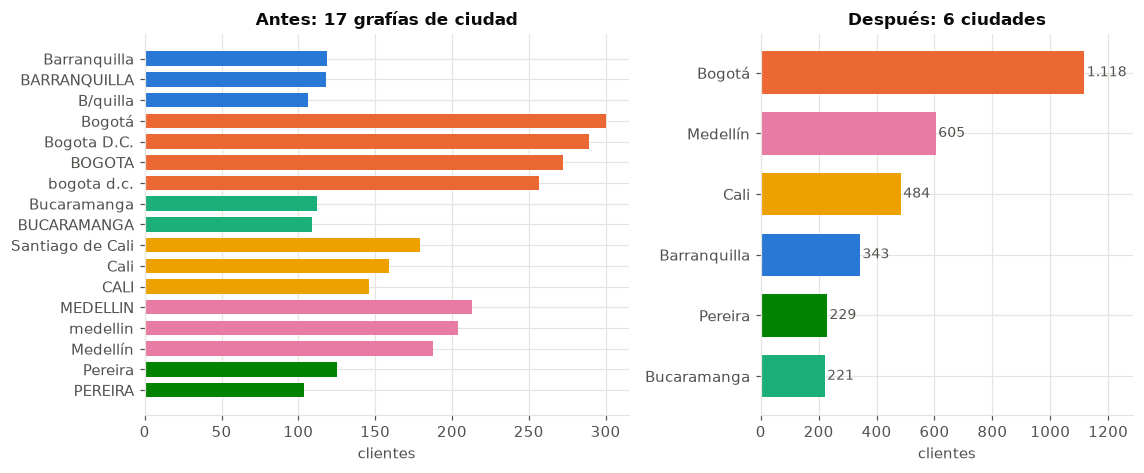

Edad — antes : min 0, media 44.8, máx 999
Edad — después: min 18, media 38.5, máx 99 (55 valores centinela → NaN + bandera `edad_invalida`)


In [5]:
def normalizar_texto(s):
    """Minúsculas y sin tildes, para comparar grafías."""
    return ''.join(c for c in unicodedata.normalize('NFKD', s) if not unicodedata.combining(c)).lower().strip()

CIUDADES = {'bogota': 'Bogotá', 'bogota d.c.': 'Bogotá', 'medellin': 'Medellín', 'cali': 'Cali',
            'santiago de cali': 'Cali', 'barranquilla': 'Barranquilla', 'b/quilla': 'Barranquilla',
            'bucaramanga': 'Bucaramanga', 'pereira': 'Pereira'}

clientes = clientes_raw.copy()
clientes['ciudad_original'] = clientes.ciudad
clientes['ciudad'] = clientes.ciudad.map(lambda s: CIUDADES[normalizar_texto(s)])   # KeyError si aparece una grafía nueva

# Edad: 0 y 999 son centinelas de "dato no capturado" → NaN + bandera (el modelo podrá usar la bandera)
SENTINELAS_EDAD = [0, 999]
edad_antes = clientes.edad.describe()
clientes['edad_invalida'] = clientes.edad.isin(SENTINELAS_EDAD).astype(int)
clientes['edad'] = clientes.edad.where(clientes.edad_invalida == 0)
edad_despues = clientes.edad.describe()

clientes['fecha_alta'] = pd.to_datetime(clientes.fecha_alta)
clientes['fecha_contacto_retencion'] = pd.to_datetime(clientes.fecha_contacto_retencion)

# Campos con fuga: se apartan del dataset de clientes
CAMPOS_CRM_FUGA = ['estado_actual', 'contactado_por_retencion', 'fecha_contacto_retencion']
clientes_crm = clientes[['cliente_id'] + CAMPOS_CRM_FUGA].copy()
clientes = clientes.drop(columns=CAMPOS_CRM_FUGA)

# ── Antes / después ──
orden = clientes_raw.assign(canonica=clientes.ciudad).groupby(['canonica', 'ciudad']).size().reset_index(name='n')
orden = orden.sort_values(['canonica', 'n'], ascending=[False, True])
colores_ciudad = dict(zip(sorted(orden.canonica.unique()), [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE]))
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.4), gridspec_kw={'width_ratios': [1.3, 1]})
ax[0].barh(orden.ciudad, orden.n, color=orden.canonica.map(colores_ciudad), height=0.7)
ax[0].set_title(f'Antes: {orden.ciudad.nunique()} grafías de ciudad'); ax[0].set_xlabel('clientes')
agr = clientes.ciudad.value_counts().sort_values()
ax[1].barh(agr.index, agr.values, color=[colores_ciudad[c] for c in agr.index], height=0.7)
for y, v in enumerate(agr.values): ax[1].text(v + 8, y, n_es(v), va='center', fontsize=9, color=INK2)
ax[1].set_title(f'Después: {agr.size} ciudades'); ax[1].set_xlabel('clientes'); ax[1].set_xlim(0, agr.max() * 1.15)
plt.tight_layout(); plt.show()

print('Edad — antes :', f"min {edad_antes['min']:.0f}, media {edad_antes['mean']:.1f}, máx {edad_antes['max']:.0f}")
print('Edad — después:', f"min {edad_despues['min']:.0f}, media {edad_despues['mean']:.1f}, máx {edad_despues['max']:.0f}",
      f"({int(clientes.edad_invalida.sum())} valores centinela → NaN + bandera `edad_invalida`)")

registrar('clientes', 'Ciudad escrita de varias formas (mayúsculas, tildes, abreviaturas, nombres largos)',
          f'{orden.ciudad.nunique()} grafías', 'Normalizo sin tildes/mayúsculas y mapeo a una ciudad canónica', f'{agr.size} ciudades')
registrar('clientes', 'Edad con centinelas 0 y 999', f"{int(clientes.edad_invalida.sum())} valores; media {edad_antes['mean']:.1f}, máx {edad_antes['max']:.0f}",
          'Los paso a NaN y creo `edad_invalida`; la imputación irá dentro del modelo', f"media {edad_despues['mean']:.1f}, máx {edad_despues['max']:.0f}")
registrar('clientes', 'Campos del CRM que revelan el futuro (`estado_actual`, `contactado_por_retencion`, `fecha_contacto_retencion`)',
          'Mezclados con los atributos del cliente', 'Los aparto en `clientes_crm` (solo para mostrar la fuga); no se usan como features',
          'Excluidos del modelo por construcción')

**Decisiones.**
- *Ciudad:* 17 grafías son en realidad 6 ciudades. Mapeo explícito (y con error si aparece una grafía nueva, para no ocultar datos sucios).
- *Edad:* 0 y 999 son claramente "sin dato". Los convierto en vacío y conservo una bandera, porque que falte la edad puede ser informativo.
- *CRM:* `estado_actual` es la etiqueta misma, y los campos de contacto de retención se registran **después** de que el cliente muestra señales de irse (se demuestra en la sección 3). Aprobado excluirlos.

### 2.3 Facturas: reprocesos, cobros dobles, precios históricos y pagos tardíos

La facturación es la fuente con más trampas. Reviso cuatro cosas: filas repetidas, el mismo cobro emitido dos veces, el precio que cambió en el tiempo y la fecha de pago, que solo se conoce *después* de emitir la factura.

In [6]:
facturas = facturas_raw.copy()
for c in ['fecha_vencimiento', 'fecha_pago', 'fecha_carga']:
    facturas[c] = pd.to_datetime(facturas[c])
facturas['periodo_inicio'] = pd.to_datetime(facturas.periodo + '-01')
facturas['plan'] = facturas.suscripcion_id.map(subs.set_index('suscripcion_id').plan)

# (a) Precio histórico vs vigente: ¿cuándo cambió cada plan?
precios = (facturas.groupby(['plan', 'monto']).periodo.agg(['min', 'max', 'size'])
           .rename(columns={'min': 'primer_periodo', 'max': 'último_periodo', 'size': 'facturas'}))
precios['precio_vigente'] = [PRECIO_VIGENTE[p] for p, _ in precios.index]
display(precios)

# (b) Reprocesos: mismo factura_id cargado dos veces (la segunda carga es de las 07:00 del día 5)
n0 = len(facturas)
repetidas = facturas[facturas.factura_id.duplicated(keep=False)]
identicas = repetidas.drop(columns='fecha_carga').duplicated(keep=False).all()
print(f'\nFilas con factura_id repetido: {n0 - facturas.factura_id.nunique()} (idénticas salvo fecha_carga: {identicas})')
# Me quedo con la PRIMERA carga: es la que existía en el sistema antes (importa para saber qué se conocía en cada corte)
facturas = facturas.sort_values(['fecha_carga', 'factura_id']).drop_duplicates('factura_id', keep='first')
n1 = len(facturas)

# (c) Cobros dobles: mismo cliente y periodo con factura_id distinto
doble = facturas.duplicated(['cliente_id', 'periodo'], keep='first')
cols_sin_id = [c for c in facturas.columns if c not in ('factura_id',)]
par_identico = facturas[facturas.duplicated(['cliente_id', 'periodo'], keep=False)].drop(columns='factura_id').duplicated(keep=False).all()
cobros_dobles = facturas[doble][['cliente_id', 'suscripcion_id', 'periodo', 'monto', 'fecha_carga']].copy()
cobros_dobles['periodo_inicio'] = pd.to_datetime(cobros_dobles.periodo + '-01')
facturas = facturas[~doble].copy()
print(f'Cobros dobles (cliente-periodo con 2 facturas casi idénticas, ids consecutivos): {len(cobros_dobles)} en '
      f'{cobros_dobles.cliente_id.nunique()} clientes; idénticos salvo factura_id: {par_identico}')
print('Cobros dobles por año:', cobros_dobles.periodo.str[:4].value_counts().sort_index().to_dict())
print(f'Facturas: {n_es(n0)} → {n_es(n1)} (sin reprocesos) → {n_es(len(facturas))} (sin cobros dobles). 1 fila por cliente-periodo: {not facturas.duplicated(["cliente_id","periodo"]).any()}')

registrar('facturas', 'Reprocesos: el mismo `factura_id` cargado dos veces', f'{n_es(n0 - n1)} filas repetidas',
          'Elimino duplicados conservando la primera carga', f'{n_es(n1)} facturas únicas')
registrar('facturas', 'Posible cobro doble: mismo cliente y periodo con 2 `factura_id` consecutivos',
          f'{len(cobros_dobles)} periodos con dos facturas idénticas', 'Dejo una factura por cliente-periodo y guardo el duplicado en `cobros_dobles` (con su `fecha_carga`) como señal',
          f'{n_es(len(facturas))} facturas; señal disponible para el modelo')
registrar('facturas', 'Precio histórico distinto al vigente', 'Básico facturado a 19.900 hasta 2025-03 y a 23.900 desde 2025-04',
          'Lo trato como cambio de régimen de precio: `precio_lista_al_corte(plan, corte)`; el valor de retener usa el precio vigente del plan actual', 'Los otros 3 planes no cambiaron')

primer_periodo último_periodo  facturas  precio_vigente
plan     monto                                                        
Basico   19900        2023-01        2025-03      6417           23900
         23900        2025-04        2025-12      5466           23900
Estandar 34900        2023-01        2025-12     10215           34900
Familiar 59900        2023-01        2025-12      5094           59900
Premium  49900        2023-01        2025-12      7011           49900


Filas con factura_id repetido: 989 (idénticas salvo fecha_carga: True)
Cobros dobles (cliente-periodo con 2 facturas casi idénticas, ids consecutivos): 646 en 556 clientes; idénticos salvo factura_id: True
Cobros dobles por año: {'2023': 33, '2024': 238, '2025': 375}
Facturas: 34.203 → 33.214 (sin reprocesos) → 32.568 (sin cobros dobles). 1 fila por cliente-periodo: True


**Decisiones.**
- *Reprocesos:* son la misma factura recargada; conservo la **primera** carga, porque es la que existía en el sistema antes y por tanto la que se "conocía" en cada corte.
- *Cobros dobles:* son dos facturas idénticas con IDs consecutivos. No sé si son error de sistema o cobro real al cliente; **no los borro sin más**: dejo una sola factura para los montos y guardo el duplicado como señal (es un **posible** problema real del cliente, que podría llevarlo a irse; es una hipótesis que se revisa en la sección 3 y con los tickets de "cobro doble", no una conclusión). Es un supuesto, y queda documentado.
- *Precios:* el Básico subió de 19.900 a 23.900 en abril de 2025 (+20 %). Es un **cambio de régimen de precio** (cambia la lista para todos los clientes del plan), no un cambio de monto de cada cliente; abajo lo modelo así. Para *valorar* retener uso el precio **vigente** (como pide el enunciado). El alza es además una pista para la parte 5.

Falta la última trampa: `fecha_pago`.

In [7]:
# (d) fecha_pago se registra DESPUÉS de emitir la factura → si no se filtra por corte, el modelo "ve" pagos futuros
pagadas = facturas[facturas.fecha_pago.notna()]
print(f"Facturas pagadas cuya fecha_pago es posterior a fecha_carga: {pct_es((pagadas.fecha_pago > pagadas.fecha_carga).mean())} "
      "(la columna se completa con el tiempo: contiene información del futuro respecto a la carga)")
print(f"Facturas sin fecha_pago: {pct_es(facturas.fecha_pago.isna().mean())} (nunca pagadas a la fecha de los datos)")

def facturas_al_corte(corte, fact=None, censurar_pagos=True):
    """Lo que se conocía al cierre del día `corte`: facturas ya cargadas y pagos ya ocurridos.
    `fact` permite pasar otra tabla (p. ej. una truncada, para la prueba anti-fuga); `censurar_pagos=False` solo existe para esa prueba."""
    fin = corte + UN_DIA
    f = (facturas if fact is None else fact)
    f = f[f.fecha_carga < fin].copy()
    if censurar_pagos:
        f['fecha_pago'] = f.fecha_pago.where(f.fecha_pago < fin)      # pago posterior al corte = aún no pagada
    return f

corte_ej = CORTES[-1]
f_corte = facturas_al_corte(corte_ej)
f_sin_regla = facturas[facturas.fecha_carga < corte_ej + UN_DIA]
reciente = lambda f: f[f.periodo_inicio >= corte_ej - pd.Timedelta(days=60)]      # facturas de los últimos ~2 meses
sp_con, sp_sin = reciente(f_corte).fecha_pago.isna().mean(), reciente(f_sin_regla).fecha_pago.isna().mean()
print(f'\nEjemplo, corte {corte_ej.date()}: {n_es(len(f_corte))} facturas conocidas (de {n_es(len(facturas))}).')
print(f'Facturas de los últimos 2 meses sin pago registrado al corte: {pct_es(sp_con)} con la regla '
      f'frente a {pct_es(sp_sin)} sin ella (sin la regla el modelo vería como "pagadas" facturas que se pagaron después del corte).')

registrar('facturas', '`fecha_pago` se rellena después de la carga; usarla tal cual filtra el futuro',
          f"Facturas recientes sin pago al corte {corte_ej.date()}: {pct_es(sp_sin)} sin la regla",
          'Función `facturas_al_corte(c)`: solo facturas con `fecha_carga` ≤ c y pagos con fecha ≤ c',
          f"{pct_es(sp_con)} con la regla (el estado real conocido ese día)")

Facturas pagadas cuya fecha_pago es posterior a fecha_carga: 100,0 % (la columna se completa con el tiempo: contiene información del futuro respecto a la carga)
Facturas sin fecha_pago: 4,2 % (nunca pagadas a la fecha de los datos)

Ejemplo, corte 2025-09-30: 27.276 facturas conocidas (de 32.568).
Facturas de los últimos 2 meses sin pago registrado al corte: 7,5 % con la regla frente a 3,4 % sin ella (sin la regla el modelo vería como "pagadas" facturas que se pagaron después del corte).


In [8]:
# Comprobación: las facturas con fecha_carga posterior al corte quedan fuera, igual que los pagos posteriores
filas = []
for c in CORTES + [FECHA_DATOS]:
    fin = c + UN_DIA
    f = facturas_al_corte(c)
    filas.append({'corte': c.date(),
                  'facturas excluidas (carga posterior al corte)': int((facturas.fecha_carga >= fin).sum()),
                  'incluidas con carga posterior al corte': int((f.fecha_carga >= fin).sum()),
                  'incluidas de un periodo posterior al corte': int((f.periodo_inicio > c).sum()),
                  'pagos posteriores al corte vistos como pagados': int((f.fecha_pago >= fin).sum()),
                  'pagos posteriores al corte censurados': int((facturas[facturas.fecha_carga < fin].fecha_pago >= fin).sum())})
chequeo_carga = pd.DataFrame(filas).set_index('corte')
display(chequeo_carga)
assert (chequeo_carga[['incluidas con carga posterior al corte', 'incluidas de un periodo posterior al corte',
                       'pagos posteriores al corte vistos como pagados']] == 0).all().all()
print('OK: ninguna factura cargada después del corte, ni de un periodo posterior, ni ningún pago posterior al corte entra a `facturas_al_corte`.')

,facturas excluidas (carga posterior al corte),incluidas con carga posterior al corte,incluidas de un periodo posterior al corte,pagos posteriores al corte vistos como pagados,pagos posteriores al corte censurados
corte,,,,,
2025-03-31,15342,0,0,0,131
2025-06-30,10601,0,0,0,152
2025-09-30,5292,0,0,0,146
2025-12-31,0,0,0,0,0


OK: ninguna factura cargada después del corte, ni de un periodo posterior, ni ningún pago posterior al corte entra a `facturas_al_corte`.


**Decisión.** Toda variable de facturación se calculará con `facturas_al_corte(c)`: una factura existe desde su `fecha_carga` y un pago cuenta solo si ocurrió hasta el corte. Es la regla que evita que el modelo "vea" pagos del futuro (aquí ayuda mucho que el enunciado dé `fecha_carga`).

### Precio como régimen, no como "cambio de monto"

El alza del Básico afecta a **todos** los clientes del plan a la vez. Si en las variables de facturación usara algo genérico como "variación del monto facturado", mezclaría tres cosas distintas: el alza de lista, un cambio individual de plan y un descuento. Por eso la modelo como **régimen de precio**: para cada plan, el precio de lista y desde cuándo rige, derivado de las propias facturas. Las variables usarán el precio de lista **vigente al corte** y cuánto hace que cambió.

In [9]:
# Régimen de precio por plan: precio de lista y desde cuándo rige (derivado de lo facturado)
def construir_regimenes(fact):
    """{plan: tabla (monto, vigente_desde) ordenada}. Recibe la tabla de facturas, para poder usarla con datos truncados."""
    r = (fact.groupby(['plan', 'monto']).periodo_inicio.min().rename('vigente_desde').reset_index()
         .sort_values(['plan', 'vigente_desde']))
    return {p: g.reset_index(drop=True) for p, g in r.groupby('plan')}

REGIMENES = construir_regimenes(facturas)

def precio_lista_al_corte(plan, corte, reg=None):
    """Precio de lista del plan vigente al cierre del día `corte`."""
    g = (REGIMENES if reg is None else reg)[plan]
    return int(g.loc[g.vigente_desde <= corte, 'monto'].iloc[-1])

def dias_desde_cambio_precio(plan, corte, reg=None):
    """Días desde que rige el precio actual del plan; NaN si el plan aún no ha tenido ningún cambio de precio."""
    g = (REGIMENES if reg is None else reg)[plan]; g = g[g.vigente_desde <= corte]
    return (corte - g.vigente_desde.iloc[-1]).days if len(g) > 1 else np.nan

# Comprobaciones: (1) toda factura coincide con el precio de lista de su periodo; (2) al 31-12-2025 coincide con el vigente
coincide = facturas.apply(lambda r: r.monto == precio_lista_al_corte(r.plan, r.periodo_inicio), axis=1).mean()
vigente_ok = all(precio_lista_al_corte(p, FECHA_DATOS) == v for p, v in PRECIO_VIGENTE.items())
print(f'Facturas cuyo monto es el precio de lista de su periodo: {pct_es(coincide)} | precio de lista al 31-12-2025 == precios vigentes: {vigente_ok}')

tabla_precio = pd.DataFrame([{'corte': c.date(), 'plan': p, 'precio_lista': precio_lista_al_corte(p, c),
                              'días_desde_cambio': dias_desde_cambio_precio(p, c)} for c in CORTES for p in ['Basico']])
display(tabla_precio.set_index('corte')[['precio_lista', 'días_desde_cambio']].rename_axis('corte (plan Básico)'))

Facturas cuyo monto es el precio de lista de su periodo: 100,0 % | precio de lista al 31-12-2025 == precios vigentes: True


,precio_lista,días_desde_cambio
corte (plan Básico),,
2025-03-31,19900,NaN
2025-06-30,23900,90.0
2025-09-30,23900,182.0


**Decisión.** Las variables de facturación usarán `precio_lista_al_corte` y `dias_desde_cambio_precio` (régimen), **no** "monto actual − monto anterior". Dos consecuencias que tengo presentes:
- En el corte del **31-mar** el Básico aún está en 19.900, y el alza ocurre **dentro de la ventana de 90 días** de ese corte: el modelo no puede "ver" el alza para esas filas, pero su etiqueta ya la incluye. En 30-jun y 30-sep el régimen ya está vigente (90 y 182 días), igual que el 31-dic, que es lo que se va a puntuar.
- Por eso para el Básico el comportamiento "post-alza" se aprende de los cortes de junio y septiembre. Lo revisaré en la validación (parte 2) mirando el Básico por separado.

### 2.4 Tickets: dos esquemas JSON, dos formatos de ID y dos zonas horarias

La plataforma de atención cambió de sistema a mediados de 2025 y los tickets quedaron en **dos esquemas distintos**. Los unifico en una sola tabla.

| Campo unificado | Esquema A (hasta 27-jun-2025) | Esquema B (desde 27-jun-2025) |
|---|---|---|
| `cliente_id` | `customer` = `"CL-0nnnnn"` | `cliente.id` = `"1nnnn"` (texto) |
| `fecha` | `created_at` en UTC (`Z`) | `fecha` con `-05:00` |
| `canal` | `channel` | `canal` |
| `categoria` / `subcategoria` | `category` (plano) | `tipo.principal` / `tipo.sub` |
| `texto` | `text` | mensajes con `autor == 'cliente'` |
| `estado` | `status`: closed / open | `estado.valor`: resuelto / abierto |
| `csat` | `csat` | `satisfaccion.csat` (ausente en 1/3 de los casos) |

In [10]:
def a_hora_colombia(serie):
    """Texto ISO con zona (Z o -05:00) → datetime sin zona en hora de Colombia (UTC−5, sin horario de verano)."""
    return pd.to_datetime(serie, utc=True).dt.tz_localize(None) - pd.Timedelta(hours=5)

filas = []
for t in tickets_raw:
    if 'customer' in t:                                       # esquema A
        filas.append(dict(ticket_id=t['ticket_id'], cliente_raw=t['customer'], fecha_raw=t['created_at'], canal=t['channel'],
                          categoria=t['category'], subcategoria=None, texto=t['text'], estado_raw=t['status'],
                          fecha_res_raw=t.get('resolved_at'), csat=t.get('csat'), n_mensajes=1, esquema='A'))
    else:                                                     # esquema B
        msgs = t.get('mensajes', [])
        filas.append(dict(ticket_id=t['id'], cliente_raw=t['cliente']['id'], fecha_raw=t['fecha'], canal=t['canal'],
                          categoria=t['tipo']['principal'], subcategoria=t['tipo'].get('sub'),
                          texto=' '.join(m['texto'] for m in msgs if m.get('autor') == 'cliente'),
                          estado_raw=t['estado']['valor'], fecha_res_raw=t['estado'].get('fecha'),
                          csat=(t.get('satisfaccion') or {}).get('csat'), n_mensajes=len(msgs), esquema='B'))
tickets = pd.DataFrame(filas)

formatos_id_antes = tickets.groupby('esquema').cliente_raw.agg(lambda s: re.sub(r'\d', 'n', str(s.iloc[0]))).to_dict()   # solo el patrón, no un ID real
tickets['cliente_id'] = tickets.cliente_raw.astype(str).str.extract(r'(\d+)')[0].astype(int)   # "CL-0nnnnn" y "1nnnn" → entero
tickets['fecha'] = a_hora_colombia(tickets.fecha_raw)
tickets['fecha_resolucion'] = a_hora_colombia(tickets.fecha_res_raw.where(tickets.fecha_res_raw.notna(), None))
tickets['estado'] = tickets.estado_raw.map({'closed': 'cerrado', 'resuelto': 'cerrado', 'open': 'abierto', 'abierto': 'abierto'})
tickets['csat'] = pd.to_numeric(tickets.csat)
assert tickets.estado.notna().all() and tickets.ticket_id.is_unique

# Anomalía: tickets fuera de la vida del cliente (antes de su alta o después de su baja)
baja_cliente = cancelaciones.set_index('cliente_id').fecha_baja
tickets['fecha_alta'] = tickets.cliente_id.map(clientes.set_index('cliente_id').fecha_alta)
tickets['fecha_baja'] = tickets.cliente_id.map(baja_cliente)
dia = tickets.fecha.dt.normalize()
tickets['antes_del_alta'] = dia < tickets.fecha_alta
tickets['despues_de_la_baja'] = dia > tickets.fecha_baja
tickets['fuera_de_vida'] = tickets.antes_del_alta | tickets.despues_de_la_baja
tickets = tickets.drop(columns=['cliente_raw', 'fecha_raw', 'fecha_res_raw', 'estado_raw', 'fecha_alta', 'fecha_baja'])

print('Formato de ID — esquema A:', formatos_id_antes['A'], '| esquema B:', formatos_id_antes['B'], '→ ambos a entero')
print('Tickets por esquema:', tickets.esquema.value_counts().to_dict(), '| por trimestre y esquema:')
display(tickets.groupby([tickets.fecha.dt.to_period('Q').astype(str), 'esquema']).size().unstack(fill_value=0).T)
print(f"Tickets antes del alta: {int(tickets.antes_del_alta.sum())}; después de la baja: {int(tickets.despues_de_la_baja.sum())} "
      f"(≈{pct_es(tickets.fuera_de_vida.mean())} del total; diferencia máx. de días: "
      f"{int(((tickets.loc[tickets.antes_del_alta, 'fecha'].dt.normalize().rsub(tickets.loc[tickets.antes_del_alta, 'cliente_id'].map(clientes.set_index('cliente_id').fecha_alta))).dt.days).max())} antes del alta)")
print('CSAT ausente por esquema:', tickets.groupby('esquema').csat.apply(lambda s: pct_es(s.isna().mean())).to_dict())
print(f"Textos distintos de clientes: {tickets.texto.nunique()} en {n_es(len(tickets))} tickets (texto muy repetitivo → plantillas)")

registrar('tickets', 'Dos esquemas JSON de sistemas distintos (A hasta 27-jun-2025, B después)', 'Campos y anidación distintos',
          'Unifico en una tabla con campos comunes', f'{n_es(len(tickets))} tickets, {tickets.shape[1]} columnas comunes')
registrar('tickets', 'ID de cliente con dos formatos ("CL-0nnnnn" vs "nnnnn")', 'Texto con prefijo vs texto numérico', 'Extraigo el número → entero',
          f"{pct_es(tickets.cliente_id.isin(clientes.cliente_id).mean())} cruza con `clientes`")
registrar('tickets', 'Fechas con zona distinta (UTC `Z` vs `-05:00`)', 'Dos zonas horarias', 'Todo a hora de Colombia (UTC−5), sin zona', 'Una sola referencia temporal')

Formato de ID — esquema A: CL-nnnnnn | esquema B: nnnnn → ambos a entero
Tickets por esquema: {'A': 2431, 'B': 1828} | por trimestre y esquema:


fecha,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4
esquema,,,,,,,,,,,,
A,10,43,78,127,181,277,311,384,444,576,0,0
B,0,0,0,0,0,0,0,0,0,28,838,962


Tickets antes del alta: 185; después de la baja: 118 (≈7,1 % del total; diferencia máx. de días: 26 antes del alta)
CSAT ausente por esquema: {'A': '6,8 %', 'B': '32,8 %'}
Textos distintos de clientes: 38 en 4.259 tickets (texto muy repetitivo → plantillas)


**¿Dónde se concentran los tickets "fuera de la vida del cliente"?** Antes de decidir qué hacer con ellos miro si se agrupan en un esquema o en un periodo. *Antes del alta* se mide sobre todos los tickets; *después de la baja* solo puede ocurrir en clientes que cancelaron, así que su denominador son los tickets de esos clientes.

In [11]:
t = tickets.assign(trimestre=tickets.fecha.dt.to_period('Q').astype(str))
t['cliente_cancelo'] = t.cliente_id.isin(cancelaciones.cliente_id)
pct = lambda a, b: (100 * a / b).round(1)

# (a) por esquema
por_esq = pd.DataFrame({'tickets': t.groupby('esquema').size(),
                        'antes del alta': t.groupby('esquema').antes_del_alta.sum()})
por_esq['% antes del alta'] = pct(por_esq['antes del alta'], por_esq.tickets)
por_esq['tickets de clientes que cancelaron'] = t[t.cliente_cancelo].groupby('esquema').size()
por_esq['después de la baja'] = t[t.cliente_cancelo].groupby('esquema').despues_de_la_baja.sum()
por_esq['% después de la baja'] = pct(por_esq['después de la baja'], por_esq['tickets de clientes que cancelaron'])
print('(a) Por esquema'); display(por_esq)

# (b) por trimestre del ticket
por_trim = pd.DataFrame({'tickets': t.groupby('trimestre').size(), 'antes del alta': t.groupby('trimestre').antes_del_alta.sum(),
                         'tickets de cancelados': t[t.cliente_cancelo].groupby('trimestre').size(),
                         'después de la baja': t[t.cliente_cancelo].groupby('trimestre').despues_de_la_baja.sum()}).fillna(0).astype(int)
por_trim['% antes del alta'] = pct(por_trim['antes del alta'], por_trim.tickets)
por_trim['% después de la baja'] = pct(por_trim['después de la baja'], por_trim['tickets de cancelados'].replace(0, np.nan))
por_trim['esquema'] = t.groupby('trimestre').esquema.agg(lambda s: '+'.join(sorted(s.unique())))
print('(b) Por trimestre del ticket'); display(por_trim)

# (c) ¿qué tan lejos del alta/baja? y ¿pueden estos tickets llegar a una feature?
f = t.merge(clientes[['cliente_id', 'fecha_alta']], on='cliente_id').merge(cancelaciones[['cliente_id', 'fecha_baja']], on='cliente_id', how='left')
d_antes = (f.loc[f.antes_del_alta, 'fecha_alta'] - f.loc[f.antes_del_alta, 'fecha'].dt.normalize()).dt.days
d_desp = (f.loc[f.despues_de_la_baja, 'fecha'].dt.normalize() - f.loc[f.despues_de_la_baja, 'fecha_baja']).dt.days
print(f'(c) Días antes del alta: mediana {d_antes.median():.0f} (rango {d_antes.min()}–{d_antes.max()}) | '
      f'días después de la baja: mediana {d_desp.median():.0f} (rango {d_desp.min()}–{d_desp.max()})')
vis = etiquetas.merge(t.loc[t.despues_de_la_baja, ['cliente_id', 'fecha']], on='cliente_id')
print('Tickets posteriores a la baja que serían visibles en algún corte de entrenamiento:', int((vis.fecha < vis.fecha_corte + UN_DIA).sum()))

registrar('tickets', 'Tickets fuera de la vida del cliente (antes del alta o después de la baja)', f'{int(tickets.fuera_de_vida.sum())} tickets ({pct_es(tickets.fuera_de_vida.mean())})',
          'Los marco con `fuera_de_vida`; las features excluyen los anteriores al alta; los posteriores a la baja nunca son visibles en un corte',
          'Causa no determinada: desfase de registro o consultas reales (preventa / reclamos tras la baja)')

(a) Por esquema


,tickets,antes del alta,% antes del alta,tickets de clientes que cancelaron,después de la baja,% después de la baja
esquema,,,,,,
A,2431,139,5.7,1433,58,4.0
B,1828,46,2.5,573,60,10.5


(b) Por trimestre del ticket


,tickets,antes del alta,tickets de cancelados,después de la baja,% antes del alta,% después de la baja,esquema
trimestre,,,,,,,
2023Q1,10,3,9,0,30.0,0.0,A
2023Q2,43,0,32,0,0.0,0.0,A
2023Q3,78,11,55,3,14.1,5.5,A
2023Q4,127,12,97,3,9.4,3.1,A
2024Q1,181,11,126,4,6.1,3.2,A
2024Q2,277,14,180,3,5.1,1.7,A
2024Q3,311,16,208,8,5.1,3.8,A
2024Q4,384,21,221,12,5.5,5.4,A
2025Q1,444,16,249,12,3.6,4.8,A


(c) Días antes del alta: mediana 8 (rango 1–26) | días después de la baja: mediana 10 (rango 1–27)
Tickets posteriores a la baja que serían visibles en algún corte de entrenamiento: 0


**Lectura.** No hay un único foco; son dos patrones distintos:
- **Antes del alta (185):** el 75 % está en el esquema **A** (5,7 % de sus tickets) frente a 2,5 % en B. No hay un pico en un periodo: en A ronda 5–6 % en 2024 y en el segundo trimestre de 2025 y en B baja de 3,9 % (3T) a 1,4 % (4T).
- **Después de la baja (118):** se reparte casi por igual entre esquemas, pero **pesa más en el B**: 10,5 % de los tickets de clientes que cancelaron, frente a 4,0 % en A, y **crece con el tiempo** (≈5 % en 2025-T1/T2, 9 % en T3 y 13 % en T4).
- En ambos casos la distancia es **menor a 4 semanas** (1–26 y 1–27 días): un ID mal asignado no tendría por qué respetar ese margen. Es más compatible con consultas reales (antes de contratar, o reclamos de cobro tras la baja) o con un desfase de registro de unas semanas. **No puedo distinguirlo con estos datos.**

**Decisión.** No los borro. Los posteriores a la baja **nunca llegan a una variable** por la propia regla de la foto al corte (verificado: 0). Los anteriores al alta solo entrarían a clientes con alta en los últimos 60 días; por prudencia los excluyo de las variables y en la parte 4 compararé el modelo con y sin ellos.

**Decisiones.**
- *IDs y fechas:* extraigo el número del ID (`CL-0nnnnn` → entero; 100 % cruza con `clientes`) y llevo todo a hora de Colombia para compararlo contra cortes.
- *Anomalías:* ~7 % de los tickets caen antes del alta o después de la baja del cliente, a menos de 4 semanas del evento. Los marco con una bandera; no los borro; y no los uso en variables (ver lectura arriba). Supuesto documentado.
- *Dos esquemas, dos taxonomías:* las categorías de A y de B **no son equivalentes** (A: `lentitud`, `cancelar`, `cobro_doble`…; B: `tecnico`, `comercial`, `facturacion`, `cuenta` + subcategoría). Si usara la categoría original, el cambio de sistema se confundiría con un cambio de comportamiento. En la parte 4 construiré temas comunes **a partir del texto del cliente**, que sí es comparable.

### 2.5 Eventos de la app y llaves entre todas las fuentes

In [12]:
eventos = pd.DataFrame(eventos_raw)
n_ev0 = len(eventos)
print(f"event_id repetidos: {n_es(eventos.event_id.duplicated().sum())} "
      f"(filas idénticas salvo el id: {n_es(eventos.drop(columns='event_id').duplicated().sum())})")
eventos = eventos.drop_duplicates('event_id').copy()
eventos['fecha'] = a_hora_colombia(eventos.ts)
eventos = eventos.drop(columns='ts')
print(f'Eventos: {n_es(n_ev0)} → {n_es(len(eventos))} | rango {eventos.fecha.min().date()} a {eventos.fecha.max().date()}')
print('Plataforma × versión de la app:', eventos.groupby(['plataforma', 'version_app']).size().to_dict())

registrar('eventos', 'Eventos duplicados (mismo `event_id`)', f'{n_es(n_ev0 - len(eventos))} filas repetidas', 'Elimino duplicados', f'{n_es(len(eventos))} eventos únicos')

# ── Llaves entre todas las tablas y documentos ──
ids = set(clientes.cliente_id)
checks = pd.Series({
    'suscripciones.cliente_id ⊂ clientes':       subs.cliente_id.isin(ids).all(),
    'facturas.cliente_id ⊂ clientes':            facturas.cliente_id.isin(ids).all(),
    'facturas.suscripcion_id ⊂ suscripciones':   facturas.suscripcion_id.isin(subs.suscripcion_id).all(),
    'etiquetas.cliente_id ⊂ clientes':           etiquetas.cliente_id.isin(ids).all(),
    'clientes_a_puntuar ⊂ clientes':             puntuar_raw.cliente_id.isin(ids).all(),
    'tickets.cliente_id ⊂ clientes (tras normalizar)': tickets.cliente_id.isin(ids).all(),
    'eventos.cliente_id ⊂ clientes':             eventos.cliente_id.isin(ids).all(),
    'plataforma del evento == plataforma_principal':
        (eventos.merge(clientes[['cliente_id', 'plataforma_principal']], on='cliente_id').pipe(lambda d: (d.plataforma == d.plataforma_principal).all())),
    'ningún evento antes del alta':              (eventos.fecha.dt.normalize() >= eventos.cliente_id.map(clientes.set_index('cliente_id').fecha_alta)).all(),
    'ningún evento después de la baja':          ~(eventos.fecha.dt.normalize() > eventos.cliente_id.map(baja_cliente)).any(),
})
display(checks.rename('¿se cumple?').to_frame())

event_id repetidos: 2.492 (filas idénticas salvo el id: 2.492)
Eventos: 103.184 → 100.692 | rango 2025-01-01 a 2025-12-31
Plataforma × versión de la app: {('android', '5.1.2'): 54772, ('ios', '5.1.2'): 23545, ('ios', '5.2.0'): 12455, ('web', 'web'): 9920}


,¿se cumple?
suscripciones.cliente_id ⊂ clientes,True
facturas.cliente_id ⊂ clientes,True
facturas.suscripcion_id ⊂ suscripciones,True
etiquetas.cliente_id ⊂ clientes,True
clientes_a_puntuar ⊂ clientes,True
tickets.cliente_id ⊂ clientes (tras normalizar),True
eventos.cliente_id ⊂ clientes,True
plataforma del evento == plataforma_principal,True
ningún evento antes del alta,True
ningún evento después de la baja,True


### 2.6 Resumen de la calidad de datos: problemas, decisiones y supuestos

Todas las llaves cruzan (arriba). Esta tabla se genera con los números reales de las celdas anteriores:

In [13]:
puntuar = puntuar_raw.copy()          # los 1.610 clientes activos al 31-12-2025
resumen = '| Fuente | Problema | Antes | Qué hice | Después |\n|---|---|---|---|---|\n'
for r in registro:
    resumen += f"| {r['Fuente']} | {r['Problema']} | {r['Antes']} | {r['Qué hice']} | {r['Después']} |\n"
display(Markdown(resumen))

| Fuente | Problema | Antes | Qué hice | Después |
|---|---|---|---|---|
| etiquetas | La etiqueta no trae definición de "cancelar" | Si cuento cualquier fin de suscripción hay 111 filas que no coinciden | Defino cancelar = cierre sin `cambio_plan` (los cambios de plan van seguidos de otra suscripción) | Coincidencia 100 % con la etiqueta provista (0 discrepancias) |
| clientes | Ciudad escrita de varias formas (mayúsculas, tildes, abreviaturas, nombres largos) | 17 grafías | Normalizo sin tildes/mayúsculas y mapeo a una ciudad canónica | 6 ciudades |
| clientes | Edad con centinelas 0 y 999 | 55 valores; media 44.8, máx 999 | Los paso a NaN y creo `edad_invalida`; la imputación irá dentro del modelo | media 38.5, máx 99 |
| clientes | Campos del CRM que revelan el futuro (`estado_actual`, `contactado_por_retencion`, `fecha_contacto_retencion`) | Mezclados con los atributos del cliente | Los aparto en `clientes_crm` (solo para mostrar la fuga); no se usan como features | Excluidos del modelo por construcción |
| facturas | Reprocesos: el mismo `factura_id` cargado dos veces | 989 filas repetidas | Elimino duplicados conservando la primera carga | 33.214 facturas únicas |
| facturas | Posible cobro doble: mismo cliente y periodo con 2 `factura_id` consecutivos | 646 periodos con dos facturas idénticas | Dejo una factura por cliente-periodo y guardo el duplicado en `cobros_dobles` (con su `fecha_carga`) como señal | 32.568 facturas; señal disponible para el modelo |
| facturas | Precio histórico distinto al vigente | Básico facturado a 19.900 hasta 2025-03 y a 23.900 desde 2025-04 | Lo trato como cambio de régimen de precio: `precio_lista_al_corte(plan, corte)`; el valor de retener usa el precio vigente del plan actual | Los otros 3 planes no cambiaron |
| facturas | `fecha_pago` se rellena después de la carga; usarla tal cual filtra el futuro | Facturas recientes sin pago al corte 2025-09-30: 3,4 % sin la regla | Función `facturas_al_corte(c)`: solo facturas con `fecha_carga` ≤ c y pagos con fecha ≤ c | 7,5 % con la regla (el estado real conocido ese día) |
| tickets | Dos esquemas JSON de sistemas distintos (A hasta 27-jun-2025, B después) | Campos y anidación distintos | Unifico en una tabla con campos comunes | 4.259 tickets, 15 columnas comunes |
| tickets | ID de cliente con dos formatos ("CL-0nnnnn" vs "nnnnn") | Texto con prefijo vs texto numérico | Extraigo el número → entero | 100,0 % cruza con `clientes` |
| tickets | Fechas con zona distinta (UTC `Z` vs `-05:00`) | Dos zonas horarias | Todo a hora de Colombia (UTC−5), sin zona | Una sola referencia temporal |
| tickets | Tickets fuera de la vida del cliente (antes del alta o después de la baja) | 303 tickets (7,1 %) | Los marco con `fuera_de_vida`; las features excluyen los anteriores al alta; los posteriores a la baja nunca son visibles en un corte | Causa no determinada: desfase de registro o consultas reales (preventa / reclamos tras la baja) |
| eventos | Eventos duplicados (mismo `event_id`) | 2.492 filas repetidas | Elimino duplicados | 100.692 eventos únicos |


**Supuestos que quedan abiertos** (los defenderé o ajustaré según lo que muestren los datos):
1. *Cancelar* = cierre sin `cambio_plan` (verificado: 0 discrepancias con la etiqueta).
2. El cobro doble es un **posible problema real del cliente** (también podría ser un duplicado de sistema): es una hipótesis, no una conclusión. Se conserva como señal; no se borra ni se afirma su efecto.
3. Los tickets fuera de la vida del cliente son ruido de la migración de sistemas; no se usan.
4. La "foto al corte" es al **cierre del día** del corte, en hora de Colombia.
5. `edad` 0 y 999 significan "sin dato".

<a id="s3"></a>

## 3. Exploración enfocada

Solo miro lo que justifica una decisión de modelado: **(3.1)** dónde se concentra la cancelación, **(3.2)** la evidencia de la fuga del CRM y **(3.3)** si el cobro doble merece ser una variable.

### 3.1 ¿Dónde se concentra la cancelación?

Para cada corte necesito el plan **vigente en esa fecha** (un cliente puede haber cambiado de plan): lo defino como `plan_al_corte(c)` y lo reutilizaré al construir variables.

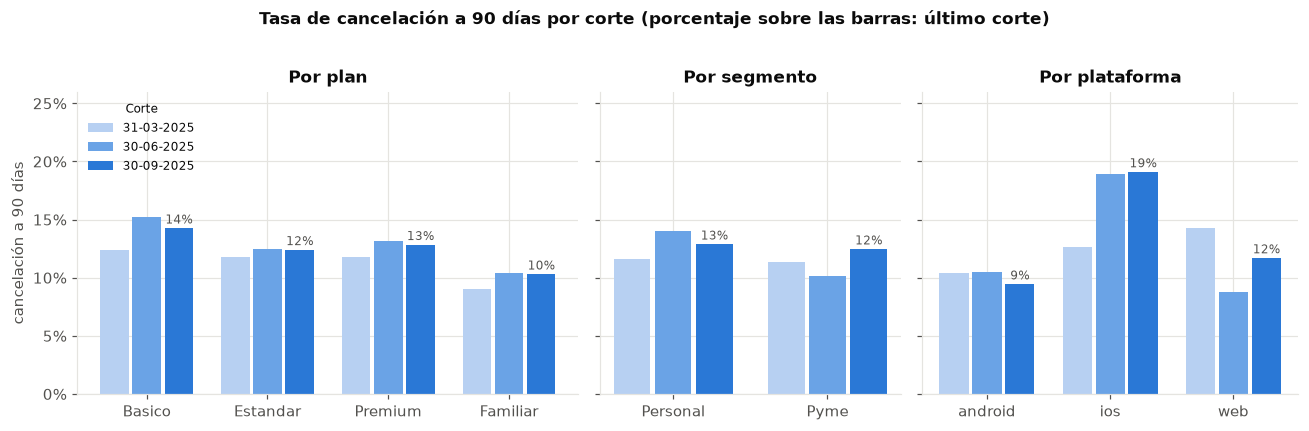

Clientes-corte por plan: {'Basico': 1598, 'Estandar': 1430, 'Premium': 967, 'Familiar': 714}
Clientes-corte por segmento: {'Personal': 3740, 'Pyme': 969}
Clientes-corte por plataforma_principal: {'android': 2633, 'ios': 1596, 'web': 480}


In [14]:
def plan_al_corte(corte):
    """Plan que tenía cada cliente activo al cierre del día `corte` (suscripción iniciada y aún abierta)."""
    s = subs[(subs.fecha_inicio <= corte) & (subs.fecha_fin.isna() | (subs.fecha_fin > corte))]
    assert s.cliente_id.is_unique, 'un cliente con dos suscripciones abiertas a la vez'
    return s.set_index('cliente_id').plan

base = etiquetas.merge(clientes[['cliente_id', 'segmento', 'plataforma_principal']], on='cliente_id')
base['plan'] = pd.concat([plan_al_corte(c).reindex(base.loc[base.fecha_corte == c, 'cliente_id']).set_axis(base.index[base.fecha_corte == c])
                          for c in CORTES])
assert base.plan.notna().all(), 'hay etiquetas sin plan vigente al corte'

def barras_por_corte(ax, tabla, titulo, orden):
    tabla = tabla.loc[orden]
    n = tabla.shape[1]; ancho = 0.8 / n
    for j, (corte, color) in enumerate(zip(tabla.columns, AZULES_CORTE)):
        x = np.arange(len(tabla)) + (j - (n - 1) / 2) * ancho
        ax.bar(x, tabla[corte].values, width=ancho - 0.03, color=color, label=pd.Timestamp(corte).strftime('%d-%m-%Y'))
        if j == n - 1:                                            # etiqueta solo el último corte (el más reciente)
            for xi, v in zip(x, tabla[corte].values):
                ax.text(xi, v + 0.004, pct_es(v, 0).replace(' %', '%'), ha='center', fontsize=8, color=INK2)
    ax.set_xticks(range(len(tabla))); ax.set_xticklabels(tabla.index); ax.set_title(titulo)
    ax.yaxis.set_major_formatter(lambda v, _: f'{100*v:.0f}%'); ax.set_ylim(0, 0.26)

dimensiones = [('plan', 'Por plan', ['Basico', 'Estandar', 'Premium', 'Familiar']),
               ('segmento', 'Por segmento', ['Personal', 'Pyme']),
               ('plataforma_principal', 'Por plataforma', ['android', 'ios', 'web'])]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True, gridspec_kw={'width_ratios': [4, 2.4, 3]})
for ax, (col, titulo, orden) in zip(axs, dimensiones):
    tab = base.pivot_table(index=col, columns='fecha_corte', values='churn_90d', aggfunc='mean')
    barras_por_corte(ax, tab, titulo, orden)
axs[0].set_ylabel('cancelación a 90 días'); axs[0].legend(title='Corte', frameon=False, fontsize=8, title_fontsize=8, loc='upper left')
plt.suptitle('Tasa de cancelación a 90 días por corte (porcentaje sobre las barras: último corte)', y=1.02, fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

for col, _, orden in dimensiones:
    print(f'Clientes-corte por {col}:', base[col].value_counts().loc[orden].to_dict())

**Lectura y decisiones.**
- **iOS** es la única plataforma que se separa de forma sostenida: pasa de 12,6 % (31-mar) a ~19 % (30-jun y 30-sep), mientras Android se queda en 9–10 %. (Web oscila entre 9 y 14 % con solo ~480 casos: es ruido.) Es una brecha que **aparece en el tiempo**, no una diferencia fija del segmento: una pista concreta para la parte 5 y una razón para mirar el uso de la app (errores, versión) en la parte 4.
- **Básico** cancela más (12 → 15 → 14 %) y el salto coincide con su alza de precio de abril (una pista, no una prueba); **Familiar** es el plan que menos cancela (~10 %). El plan entra como variable. (El plan también define el *valor* de retener, no solo el riesgo: eso es la parte 3.)
- **Segmento:** Personal (13 %) y Pyme (12 %) difieren poco en el último corte; entra como variable, pero no espero que pese mucho.

**¿La brecha de iOS coincide con la llegada de la versión 5.2.0?** Las barras por corte son demasiado gruesas (cada corte mira 90 días) para responderlo. Lo miro por **mes calendario** y por **versión de la app**. La versión de cada cliente sale de sus eventos: cuenta como "5.2.0" desde el primer día que la usa. Mido la cancelación como tasa mensual sobre **personas-día en riesgo** (así un cliente que actualiza a mitad de mes se reparte entre las dos versiones, en vez de asignarlo a una por error).

La 5.2.0 aparece por primera vez el 2025-08-01 y solo en iOS. La usan 468 de 1039 clientes iOS; 85 % la adoptó en su primer mes.


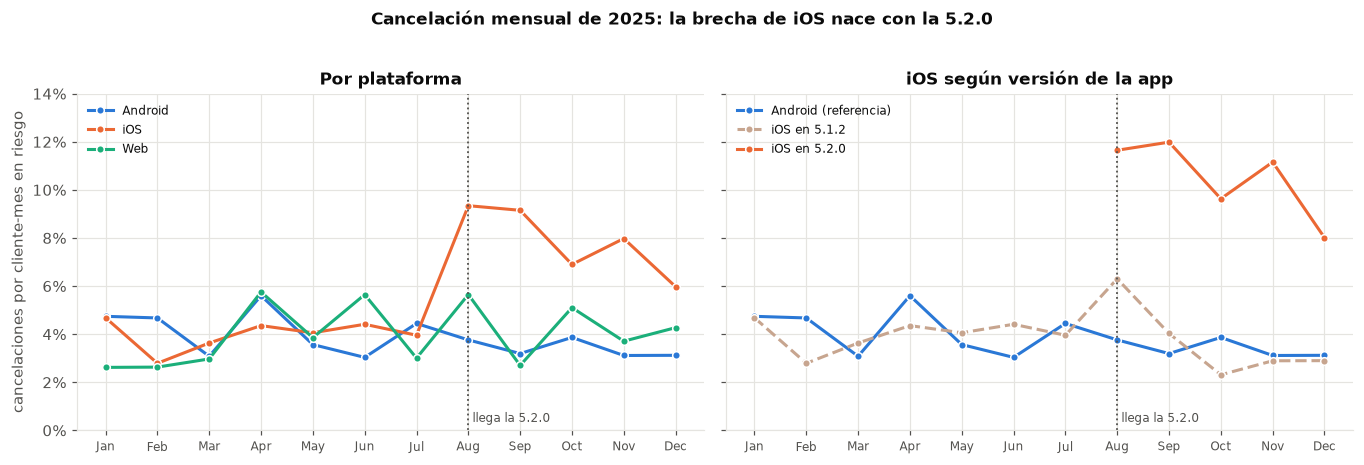

personas_mes  cancelaciones tasa mensual  \
periodo           grupo                                                 
antes (ene–jul)   android            5543            229        4,1 %   
                  ios 5.1.2          3547            142        4,0 %   
                  web                 984             38        3,9 %   
después (ago–dic) android            4951            169        3,4 %   
                  ios 5.1.2          1083             41        3,8 %   
                  ios 5.2.0          1701            179       10,5 %   
                  web                 934             40        4,3 %   

                            ± (IC 95 %)  
periodo           grupo                  
antes (ene–jul)   android         0,5 %  
                  ios 5.1.2       0,7 %  
                  web             1,2 %  
después (ago–dic) android         0,5 %  
                  ios 5.1.2       1,2 %  
                  ios 5.2.0       1,5 %  
                  web             1,3 %

In [15]:
llegada_520 = eventos.loc[eventos.version_app == '5.2.0', 'fecha'].min().normalize()
primer_520 = eventos.loc[eventos.version_app == '5.2.0'].groupby('cliente_id').fecha.min().dt.normalize()
adopcion_mes = primer_520.dt.to_period('M').value_counts().sort_index()
print(f'La 5.2.0 aparece por primera vez el {llegada_520.date()} y solo en iOS. La usan {len(primer_520)} de '
      f"{int((clientes.plataforma_principal == 'ios').sum())} clientes iOS; {pct_es(adopcion_mes.iloc[0] / adopcion_mes.sum(), 0)} la adoptó en su primer mes.")

cl_ = (clientes.set_index('cliente_id')[['fecha_alta', 'plataforma_principal']]
       .join(cancelaciones.set_index('cliente_id').fecha_baja).join(primer_520.rename('primer_520')))

def exposicion_mes(mes):
    """Por grupo: días-persona en riesgo y cancelaciones del mes. iOS se divide en 5.1.2 / 5.2.0 según el día en que cada cliente la usa."""
    ini, fin = mes.start_time, (mes + 1).start_time
    d = cl_[(cl_.fecha_alta < fin) & (cl_.fecha_baja.isna() | (cl_.fecha_baja >= ini))].copy()
    d['desde'] = d.fecha_alta.clip(lower=ini)
    baja_en_mes = d.fecha_baja.notna() & (d.fecha_baja < fin)
    d['hasta'] = fin
    d.loc[baja_en_mes, 'hasta'] = d.loc[baja_en_mes, 'fecha_baja'] + UN_DIA     # se cuenta el día de la baja
    d['dias'] = (d.hasta - d.desde).dt.days
    ios = d.plataforma_principal == 'ios'
    ini520 = d.desde.where(d.primer_520.isna() | (d.desde > d.primer_520), d.primer_520)   # desde cuándo está en 5.2.0 dentro del mes
    d['dias_520'] = ((d.hasta - ini520).dt.days.fillna(0).clip(lower=0)).where(ios & d.primer_520.notna(), 0)   # solo iOS que alguna vez usó 5.2.0
    d['canc_520'] = baja_en_mes & ios & d.primer_520.notna() & (d.primer_520 <= d.fecha_baja)
    filas = []
    for g in ['android', 'web']:
        m = d.plataforma_principal == g
        filas.append((g, d.loc[m, 'dias'].sum(), int(baja_en_mes[m].sum())))
    filas.append(('ios 5.1.2', (d.loc[ios, 'dias'] - d.loc[ios, 'dias_520']).sum(), int((baja_en_mes & ios & ~d.canc_520).sum())))
    filas.append(('ios 5.2.0', d.loc[ios, 'dias_520'].sum(), int(d.canc_520.sum())))
    return [(str(mes), g, dias, c) for g, dias, c in filas]

MESES = pd.period_range('2025-01', '2025-12', freq='M')
exp = pd.DataFrame([f for m in MESES for f in exposicion_mes(m)], columns=['mes', 'grupo', 'dias', 'canc'])
exp['personas_mes'] = exp.dias / 30
exp['tasa'] = exp.canc / exp.personas_mes                       # cancelaciones por persona-mes en riesgo
ios_total = exp[exp.grupo.str.startswith('ios')].groupby('mes')[['dias', 'canc']].sum().assign(grupo='ios')
exp_plat = pd.concat([exp[exp.grupo.isin(['android', 'web'])][['mes', 'grupo', 'dias', 'canc']], ios_total.reset_index()])
exp_plat['tasa'] = exp_plat.canc / (exp_plat.dias / 30)

MIN_PM = 60                                                     # no dibujo puntos con menos de 60 personas-mes (muy ruidosos)
def linea(ax, df, grupo, color, etiqueta, estilo='-'):
    d = df[(df.grupo == grupo) & (df.dias / 30 >= MIN_PM)]
    ax.plot(d.mes, d.tasa, color=color, linestyle=estilo, linewidth=2, marker='o', markersize=5, markeredgecolor='white', label=etiqueta)

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.1), sharey=True)
for grupo, color, et_ in [('android', AZUL, 'Android'), ('ios', NARANJA, 'iOS'), ('web', AQUA, 'Web')]:
    linea(ax[0], exp_plat, grupo, color, et_)
ax[0].set_title('Por plataforma')
linea(ax[1], exp_plat, 'android', AZUL, 'Android (referencia)')
linea(ax[1], exp, 'ios 5.1.2', '#c7a58f', 'iOS en 5.1.2', estilo='--')
linea(ax[1], exp, 'ios 5.2.0', NARANJA, 'iOS en 5.2.0')
ax[1].set_title('iOS según versión de la app')
for a in ax:
    a.axvline(str(llegada_520.to_period('M')), color=INK2, linestyle=':', linewidth=1.2)
    a.set_xticks(range(len(MESES))); a.set_xticklabels([m.strftime('%b') for m in MESES], fontsize=8)
    a.yaxis.set_major_formatter(lambda v, _: f'{100*v:.0f}%'); a.legend(frameon=False, fontsize=8, loc='upper left')
    a.text(list(str(m) for m in MESES).index(str(llegada_520.to_period('M'))) + 0.08, 0.0035, 'llega la 5.2.0', fontsize=8, color=INK2)
ax[0].set_ylabel('cancelaciones por cliente-mes en riesgo'); ax[0].set_ylim(0, 0.14)
plt.suptitle('Cancelación mensual de 2025: la brecha de iOS nace con la 5.2.0', y=1.02, fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

# Tasas agrupadas antes y después de la llegada, con intervalo aproximado del 95 %
exp['periodo'] = np.where(exp.mes < str(llegada_520.to_period('M')), 'antes (ene–jul)', 'después (ago–dic)')
res = exp.groupby(['periodo', 'grupo'])[['personas_mes', 'canc']].sum()
res = res[res.personas_mes > 0]
res['tasa mensual'] = (100 * res.canc / res.personas_mes).map(lambda v: pct_es(v / 100, 1))
res['± (IC 95 %)'] = (196 * np.sqrt(res.canc) / res.personas_mes).map(lambda v: pct_es(v / 100, 1))
res['personas_mes'] = res.personas_mes.round(0).astype(int)
display(res.rename(columns={'canc': 'cancelaciones'}))

**Lectura.** Sí coincide con la llegada de la 5.2.0.
- **Antes** de agosto iOS cancela igual que Android: 4,0 % vs 4,1 % por cliente-mes en riesgo. Los puntos de iOS y Android se mezclan en el gráfico izquierdo de enero a julio.
- **Desde el 1-ago-2025**, cuando la 5.2.0 aparece (solo en iOS), los clientes iOS que la usan cancelan a **10,5 % mensual (±1,5)**, frente a 3,4 % en Android y 3,8 % en los iOS que siguen en la 5.1.2. Esa es la brecha por corte que vimos arriba (12,6 % → 19 %); las diferencias de marzo (12,6 % vs 10,4 %) eran ruido.
- La adopción fue casi inmediata (85 % en agosto), lo que se parece a una actualización masiva más que a una elección de los clientes.

**Cautelas.** (1) Es observacional: no prueba causalidad. Comparar contra Android e iOS 5.1.2 *en los mismos meses* descarta que sea un efecto de calendario, pero no descarta que quienes actualizaron fueran distintos. (2) El punto de agosto de iOS 5.1.2 (~6 %) mezcla a quienes actualizaron a mitad de mes. (3) Al final del año la tasa de 5.2.0 baja (8 % en diciembre): hay que vigilar si es mejora o un efecto de quién queda.

**Decisión.** La versión de la app y los errores de arranque (`CRASH_ON_START`) entran como variables en la parte 4, y en la validación miraré el rendimiento en iOS por separado. Como la 5.2.0 solo pesa en el corte de septiembre, hay riesgo de **cambio de distribución** (lo anoto en riesgos). La parte 5 profundiza en la causa (crashes) y en la acción.

### 3.2 Evidencia de la fuga del CRM

Si `contactado_por_retencion` fuera un dato legítimo al corte, debería parecerse entre quienes cancelan y quienes no. Miro dos cosas: (i) cuántos aparecen contactados y **cuándo** (antes o después del corte), y (ii) cuántos días antes de la baja se contactó a quienes cancelaron.

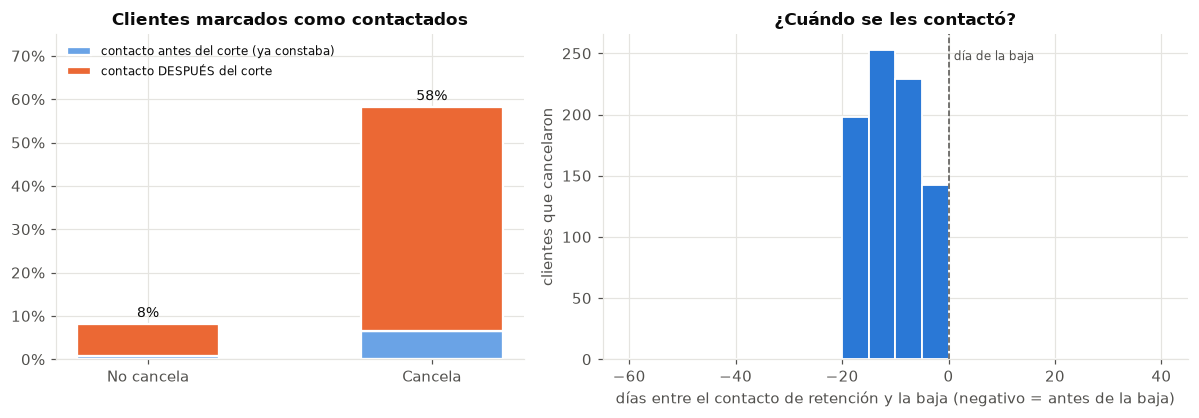

            antes despues   total
churn_90d                        
no cancela  0,7 %   7,6 %   8,2 %
cancela     6,6 %  51,7 %  58,3 %

Clientes que cancelaron y fueron contactados: 822; mediana -11 días respecto a la baja; 100 % contactados en los 30 días previos a la baja.


In [16]:
crm = (etiquetas.merge(clientes_crm, on='cliente_id')
       .assign(antes=lambda d: d.fecha_contacto_retencion <= d.fecha_corte,
               despues=lambda d: d.fecha_contacto_retencion > d.fecha_corte))
tab = crm.groupby('churn_90d')[['antes', 'despues']].mean()
tab['total'] = tab.antes + tab.despues

inactivos = clientes_crm.merge(cancelaciones[['cliente_id', 'fecha_baja']], on='cliente_id')
dias_antes_baja = (inactivos.fecha_contacto_retencion - inactivos.fecha_baja).dt.days.dropna()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={'width_ratios': [1, 1.25]})
x = np.arange(2); etiquetas_x = ['No cancela', 'Cancela']
ax[0].bar(x, tab.antes, color=AZULES_CORTE[1], width=0.5, edgecolor='white', linewidth=1.5, label='contacto antes del corte (ya constaba)')
ax[0].bar(x, tab.despues, bottom=tab.antes, color=NARANJA, width=0.5, edgecolor='white', linewidth=1.5, label='contacto DESPUÉS del corte')
for xi, t in zip(x, tab.total): ax[0].text(xi, t + 0.015, pct_es(t, 0).replace(' %', '%'), ha='center', fontsize=9, color=INK)
ax[0].set_xticks(x); ax[0].set_xticklabels(etiquetas_x); ax[0].set_ylim(0, 0.75)
ax[0].yaxis.set_major_formatter(lambda v, _: f'{100*v:.0f}%'); ax[0].set_title('Clientes marcados como contactados')
ax[0].legend(frameon=False, fontsize=8, loc='upper left')
ax[1].hist(dias_antes_baja.clip(-60, 40), bins=np.arange(-60, 45, 5), color=AZUL, edgecolor='white', linewidth=1.2)
ax[1].axvline(0, color=INK2, linewidth=1, linestyle='--'); ax[1].text(1, ax[1].get_ylim()[1] * 0.92, 'día de la baja', fontsize=8, color=INK2)
ax[1].set_xlabel('días entre el contacto de retención y la baja (negativo = antes de la baja)')
ax[1].set_ylabel('clientes que cancelaron'); ax[1].set_title('¿Cuándo se les contactó?')
plt.tight_layout(); plt.show()

print(tab.assign(**{c: tab[c].map(pct_es) for c in tab}).rename(index={0: 'no cancela', 1: 'cancela'}).to_string())
print(f'\nClientes que cancelaron y fueron contactados: {len(dias_antes_baja)}; mediana {dias_antes_baja.median():.0f} días respecto a la baja; '
      f'{pct_es(((dias_antes_baja >= -30) & (dias_antes_baja <= 0)).mean(), 0)} contactados en los 30 días previos a la baja.')

**Lectura y decisión.** Entre quienes cancelan, ~58 % figura como contactado; entre quienes no, ~8 %. Y casi todo ese contacto ocurre **después** del corte (naranja). Los 822 clientes cancelados que figuran contactados lo fueron **entre 3 y 19 días antes de su baja, sin una sola excepción** (mediana 11 días): el equipo de retención llamó a quienes ya estaban a punto de irse, o el registro se creó al iniciarse la cancelación. Es decir, el campo describe el *resultado* (quién estaba en riesgo), no una causa conocida al corte. Un modelo que lo use "acertaría" con información que en producción no tendría. **Se excluye** (decisión aprobada). Y deja una **limitación** que llevaré al memo: los contactos pasados influyeron en quién terminó cancelando, así que las etiquetas históricas ya incluyen el efecto de esas ofertas.

### 3.3 ¿El cobro doble merece ser una variable?

Compruebo si los clientes con un cobro doble en los 6 meses previos al corte cancelan más. Solo cuento lo que se conocía al corte (`fecha_carga` ≤ corte).

In [17]:
filas = []
for c in CORTES:
    conocidos = set(cobros_dobles.loc[(cobros_dobles.fecha_carga < c + UN_DIA) &
                                      (cobros_dobles.periodo_inicio >= c - pd.Timedelta(days=180)), 'cliente_id'])
    g = etiquetas[etiquetas.fecha_corte == c]
    filas.append(pd.DataFrame({'corte': c.date(), 'doble_cobro_6m': g.cliente_id.isin(conocidos).map({True: 'con', False: 'sin'}).values,
                               'churn': g.churn_90d.values}))
dc = pd.concat(filas).groupby(['corte', 'doble_cobro_6m']).churn.agg(['size', 'mean']).unstack()
dc.columns = [f'{"clientes" if a == "size" else "cancelación"} {b}' for a, b in dc.columns]
for c in dc.columns:
    if c.startswith('cancel'): dc[c] = dc[c].map(pct_es)
dc

,clientes con,clientes sin,cancelación con,cancelación sin
corte,,,,
2025-03-31,90,1304,"22,2 %","10,8 %"
2025-06-30,112,1476,"12,5 %","13,3 %"
2025-09-30,113,1614,"17,7 %","12,5 %"


**Lectura y decisión.** La señal **no es estable**: entre quienes tuvieron un cobro doble en los 6 meses previos, la cancelación fue 22 % (mar), 12,5 % (jun) y 18 % (sep), frente a 11–13 % de quienes no lo tuvieron; pero son apenas ~90–110 clientes por corte y en junio no hay diferencia. Es una **hipótesis, no una conclusión**. Decisión: la conservo como variable candidata (es barata de calcular y ya se aisló con su `fecha_carga`), dejo que el modelo decida si le sirve, y no afirmo causalidad. La retomo con los tickets de "cobro doble" en las partes 4 y 5.

### 3.4 ¿El método de pago distingue a quienes cancelan?

Pregunta pendiente: ¿vale la pena añadir `metodo_pago` (tarjeta, PSE, débito automático, efectivo) como variable? Uso el método de **la última factura conocida al corte** (`facturas_al_corte`). Para no decidir mirando los resultados, **fijo la regla antes de calcular**: un método tiene *señal consistente* si su tasa de cancelación va en **la misma dirección en los 3 cortes** respecto al resto **y** la diferencia es significativa (|z| > 1,96, prueba de dos proporciones, método frente al resto) en **al menos 2 de los 3 cortes**. Si ningún método la cumple, se descarta.

In [18]:
def z_dos_proporciones(x1, n1, x2, n2):
    p = (x1 + x2) / (n1 + n2)
    return (x1 / n1 - x2 / n2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))

filas = []
for c in CORTES:
    ultimo = (facturas_al_corte(c).sort_values(['cliente_id', 'periodo_inicio']).groupby('cliente_id').tail(1)
              .set_index('cliente_id').metodo_pago)
    g = etiquetas[etiquetas.fecha_corte == c].assign(metodo=lambda d: d.cliente_id.map(ultimo))
    assert g.metodo.notna().all()
    for m, d in g.groupby('metodo'):
        r = g[g.metodo != m]
        filas.append({'corte': c.date(), 'método': m, 'clientes': len(d), 'cancelación del método': d.churn_90d.mean(),
                      'cancelación del resto': r.churn_90d.mean(),
                      'z': z_dos_proporciones(d.churn_90d.sum(), len(d), r.churn_90d.sum(), len(r))})
mp = pd.DataFrame(filas)
vista = mp.copy()
for col in ['cancelación del método', 'cancelación del resto']: vista[col] = vista[col].map(pct_es)
vista['z'] = vista.z.round(2)
display(vista.set_index(['método', 'corte']).sort_index())

consistentes = []
for m, d in mp.groupby('método'):
    misma_direccion = d.z.gt(0).all() or d.z.lt(0).all()
    n_sig = int((d.z.abs() > 1.96).sum())
    if misma_direccion and n_sig >= 2: consistentes.append(m)
    print(f'{m:12s} misma dirección en los 3 cortes: {str(misma_direccion):5s} | |z|>1,96 en {n_sig} de 3 cortes')
METODO_PAGO_CANDIDATA = len(consistentes) > 0
print('\nMétodos con señal consistente:', consistentes or 'ninguno', '→ se', 'AÑADE' if METODO_PAGO_CANDIDATA else 'DESCARTA')

clientes cancelación del método cancelación del resto  \
método      corte                                                               
debito_auto 2025-03-31       290                 12,8 %                11,2 %   
            2025-06-30       304                 13,8 %                13,1 %   
            2025-09-30       362                 14,1 %                12,5 %   
efectivo    2025-03-31       138                 13,0 %                11,4 %   
            2025-06-30       150                 12,0 %                13,4 %   
            2025-09-30       158                 13,3 %                12,7 %   
pse         2025-03-31       404                 12,1 %                11,3 %   
            2025-06-30       504                 13,7 %                13,0 %   
            2025-09-30       540                 13,3 %                12,6 %   
tarjeta     2025-03-31       562                 10,1 %                12,5 %   
            2025-06-30       630                 12,9 %                13,5 %   
            2025-09-30       667                 11,5 %                13,6 %   

                           z  
método      corte             
debito_auto 2025-03-31  0.72  
            2025-06-30  0.34  
            2025-09-30  0.83  
efectivo    2025-03-31  0.58  
            2025-06-30 -0.47  
            2025-09-30  0.20  
pse         2025-03-31  0.43  
            2025-06-30  0.37  
            2025-09-30  0.45  
tarjeta     2025-03-31 -1.35  
            2025-06-30 -0.35  
            2025-09-30 -1.24

debito_auto  misma dirección en los 3 cortes: True  | |z|>1,96 en 0 de 3 cortes
efectivo     misma dirección en los 3 cortes: False | |z|>1,96 en 0 de 3 cortes
pse          misma dirección en los 3 cortes: True  | |z|>1,96 en 0 de 3 cortes
tarjeta      misma dirección en los 3 cortes: True  | |z|>1,96 en 0 de 3 cortes

Métodos con señal consistente: ninguno → se DESCARTA


**Decisión: descartada.** Ningún método cumple la regla: no hay un solo corte con |z| > 1,96. La única regularidad es que **tarjeta** tiene una tasa menor al resto en los 3 cortes (−2 puntos en marzo y septiembre), pero con diferencias que no pasan de |z| ≈ 1,4: compatible con ruido. No la añado como variable (menos variables, menos cosas que defender). Si más adelante se obtuviera más historia, vale la pena revisarla.

---
<a id="s4"></a>

## 4. Features al corte

Una fila por **(cliente, corte)**: un cliente activo en la fecha de corte, descrito solo con lo que se sabía al **cierre de ese día**. Es el mismo procedimiento para los 3 cortes de entrenamiento y para el 31-12-2025 (los 1.610 a puntuar).

**Reglas de construcción**
1. Toda tabla se filtra por la fecha en que el dato **existía**: facturas por `fecha_carga` (y pagos solo si ocurrieron hasta el corte), eventos y tickets por su fecha, suscripciones por su inicio (un fin posterior al corte no se conoce).
2. Ventanas **cortas y comparables entre cortes** (30, 60, 90 y 180 días, o 6 periodos de facturación): los eventos solo existen desde enero de 2025, así que en el corte de marzo no hay más de ~3 meses de historia.
3. **Pocas variables, cada una con una hipótesis.** Son 5 grupos y 29 variables; las que no pude justificar (p. ej. ciudad) no entran.
4. Una función por grupo y una que las une, `construir_features(corte, ids, T)`, que recibe las tablas como argumento: así la prueba anti-fuga (4.7) puede ejecutarla con datos truncados.

Vacíos: no los relleno aquí. La imputación se hará **dentro del pipeline del modelo** (ajustada solo con entrenamiento), y donde "no tener dato" es informativo hay una bandera.

In [19]:
# ── Utilidades comunes a todos los grupos ─────────────────────────────────────
def _conteo(df, ids):
    """Filas por cliente, alineadas a `ids` (0 si el cliente no aparece)."""
    return df.groupby('cliente_id').size().reindex(ids).fillna(0).astype(int)

def _ventana(df, col, fin, dias):
    """Filas con `col` en los últimos `dias` días antes de `fin` (exclusivo)."""
    return df[(df[col] >= fin - pd.Timedelta(days=dias)) & (df[col] < fin)]

### 4.1 Antigüedad y plan

**Por qué.** El riesgo de cancelar cambia con el tiempo de relación: los clientes nuevos y los que acaban de cambiar de plan no se comportan como los antiguos. El **plan** además fija el precio y, por tanto, el valor de retener (parte 3). `n_cambios_plan` cuenta las suscripciones anteriores (cada una terminó en un cambio de plan: un cliente activo no puede haber cancelado antes).

In [20]:
def f_antiguedad_plan(corte, ids, T):
    cl = T['clientes'].set_index('cliente_id').reindex(ids)
    s = T['subs']
    abiertas = s[(s.fecha_inicio <= corte) & (s.fecha_fin.isna() | (s.fecha_fin > corte))].set_index('cliente_id')
    out = pd.DataFrame(index=ids)
    out['antiguedad_dias'] = (corte - cl.fecha_alta).dt.days
    out['plan'] = abiertas.plan.reindex(ids)
    out['dias_en_plan'] = (corte - abiertas.fecha_inicio.reindex(ids)).dt.days
    out['n_cambios_plan'] = (s[s.fecha_inicio <= corte].groupby('cliente_id').size().reindex(ids).fillna(0) - 1).astype(int)
    return out

### 4.2 Facturación

**Por qué.** La mora y los pagos tardíos son señales clásicas de fricción con el servicio. Se miden sobre **6 periodos de facturación** (el del corte y los 5 anteriores) y solo con lo conocido al corte (`facturas_al_corte`, sección 2.3):
- `n_impagas_6m`: facturas ya vencidas al corte y sin pago registrado.
- `pagos_tardios_6m`: facturas pagadas después de su vencimiento.
- `metodo_pago`: **descartado** tras revisarlo en la sección 3.4 (sin señal consistente entre cortes).
- `cobro_doble_6m`: **candidata**, no afirmación (la señal era inestable en la sección 3.3; que el modelo decida si le sirve).
- `precio_lista` y `post_alza`: el **régimen de precio** vigente al corte (sección 2.3). `post_alza` vale 1 si el plan ya tuvo un cambio de precio en vigor. **No** uso `dias_desde_cambio_precio`: al 31-dic valdría 274 días en el Básico, un valor que el modelo nunca vio al entrenar (90 y 182), y a un modelo lineal lo haría extrapolar. El indicador binario sí tiene soporte en entrenamiento (0 en marzo; 1 en junio y septiembre).

In [21]:
def f_facturacion(corte, ids, T, plan, censurar_pagos=True):
    fin = corte + UN_DIA
    f = facturas_al_corte(corte, T['facturas'], censurar_pagos)
    ini6 = (corte.to_period('M') - 5).start_time                       # 6 periodos de facturación
    vencidas = f[(f.periodo_inicio >= ini6) & (f.fecha_vencimiento < fin)]   # el vencimiento se conoce desde la emisión
    cd = T['cobros_dobles']
    cd6 = cd[(cd.fecha_carga < fin) & (cd.periodo_inicio >= ini6)]
    reg = construir_regimenes(T['facturas'])
    out = pd.DataFrame(index=ids)
    out['n_impagas_6m'] = _conteo(vencidas[vencidas.fecha_pago.isna()], ids)
    out['pagos_tardios_6m'] = _conteo(vencidas[vencidas.fecha_pago > vencidas.fecha_vencimiento], ids)
    out['cobro_doble_6m'] = _conteo(cd6, ids)
    out['precio_lista'] = plan.map(lambda p: precio_lista_al_corte(p, corte, reg))
    out['post_alza'] = plan.map(lambda p: int((reg[p].vigente_desde <= corte).sum() > 1))
    return out

### 4.3 Uso de la app

**Por qué.** El desuso suele anteceder a la baja: menos inicios de sesión, más días sin abrir la app, y errores que frustran. Variables:
- *Frecuencia:* `logins_30d`, `usos_30d` (uso de funcionalidades) y `tendencia_logins` (últimos 30 días menos los 30 anteriores: ¿está cayendo?).
- *Recencia:* `dias_desde_ultimo_evento` y la bandera `sin_eventos` (quien no tiene ningún evento hasta el corte no es un dato perdido: es un cliente inactivo o nuevo).
- *Errores:* `crashes_arranque_60d` (el error `CRASH_ON_START`, el de la hipótesis iOS de la sección 3) y `otros_errores_30d` (`TIMEOUT`, `NET_ERR`) por separado, porque son fenómenos distintos.
- *Versión:* `usa_5_2_0` = 1 si el cliente ya usó la 5.2.0 hasta el corte. Solo existe en iOS y desde agosto de 2025 → ver el riesgo en 4.8.

In [22]:
def f_app(corte, ids, T):
    fin = corte + UN_DIA
    e = T['eventos']; e = e[e.fecha < fin]
    e30, e60 = _ventana(e, 'fecha', fin, 30), _ventana(e, 'fecha', fin, 60)
    e_ant = e[(e.fecha >= fin - pd.Timedelta(days=60)) & (e.fecha < fin - pd.Timedelta(days=30))]      # los 30 días anteriores a los últimos 30
    ultimo = e.groupby('cliente_id').fecha.max().reindex(ids)
    out = pd.DataFrame(index=ids)
    out['logins_30d'] = _conteo(e30[e30.tipo == 'login'], ids)
    out['tendencia_logins'] = out.logins_30d - _conteo(e_ant[e_ant.tipo == 'login'], ids)
    out['usos_30d'] = _conteo(e30[e30.tipo == 'uso_funcionalidad'], ids)
    out['otros_errores_30d'] = _conteo(e30[(e30.tipo == 'error_app') & (e30.codigo_error != 'CRASH_ON_START')], ids)
    out['crashes_arranque_60d'] = _conteo(e60[e60.codigo_error == 'CRASH_ON_START'], ids)
    out['dias_desde_ultimo_evento'] = (fin - ultimo).dt.days
    out['sin_eventos'] = ultimo.isna().astype(int)
    out['usa_5_2_0'] = pd.Index(ids).isin(e.loc[e.version_app == '5.2.0', 'cliente_id'].unique()).astype(int)
    return out

### 4.4 Tickets: tema por reglas de texto

**Por qué reglas y no la categoría del sistema.** Las categorías de los dos esquemas no son equivalentes (sección 2.4), así que la categoría original mezclaría el cambio de sistema con un cambio de comportamiento. El **texto del cliente** sí es comparable. Como hay solo **38 textos distintos** (plantillas), unas reglas de palabras clave bastan, son transparentes y se pueden defender línea por línea; un modelo de lenguaje o embeddings no aportarían nada que las reglas no capturen aquí.

Dos decisiones de diseño:
- Las reglas clasifican el **tema** (de qué se trata), no el **sentimiento**: una parte de los textos es **irónica** (agradecen o felicitan por algo que claramente es un problema), y un análisis de sentimiento los leería al revés. El tema no se ve afectado por la ironía.
- La **intención de baja** (el cliente dice que cancela o se va) se marca aparte del tema, porque aparece dentro de tickets de otros temas (p. ej. una queja de cobro que termina amenazando con irse).

Variables: `tickets_90d` (volumen), `tickets_intencion_baja_90d`, `tickets_tecnico_90d` (app que se cierra, lentitud, acceso), `tickets_cobro_90d` (cobro doble o no reconocido), y, de **resolución y satisfacción**, `tickets_abiertos_180d`, `horas_resolucion_media_180d` y `csat_medio_180d`, estas dos últimas solo con tickets ya resueltos al corte (la satisfacción se conoce al resolverse). Se excluyen los tickets anteriores al alta (decisión de la sección 2.4).

In [23]:
# Reglas de tema: la primera que coincide gana (el orden importa; se evalúa sobre el texto del cliente en minúsculas)
REGLAS_TEMA = [
    ('app_se_cierra',       r'se (?:cierra|cierre|cae)|no abre'),
    ('cancelar',            r'cancel|dar de baja'),
    ('cobro_doble',         r'cobro (?:doble|duplicado)|dos veces|dos cobros|cobran doble|facturaron'),
    ('cobro_no_reconocido', r'no reconozco|valor diferente|tarifa|pago más|aumento'),
    ('lentitud',            r'\blent|velocidad'),          # \b: "lent" al inicio de palabra (si no, también casaría "exce-lent-e")
    ('acceso',              r'clave|contraseña|entrar a mi cuenta'),
    ('cambio_plan',         r'\bplan\b'),
]
INTENCION_BAJA = r'cancel|dar de baja|\birme\b'
TEMAS_TECNICOS = ['app_se_cierra', 'lentitud', 'acceso']
TEMAS_COBRO = ['cobro_doble', 'cobro_no_reconocido']

def clasificar_tema(textos):
    low = textos.str.lower()
    tema = pd.Series('otro', index=textos.index)
    for nombre, patron in reversed(REGLAS_TEMA):        # aplico de la última a la primera para que la primera regla gane
        tema = tema.where(~low.str.contains(patron, regex=True), nombre)
    return tema

tickets['tema'] = clasificar_tema(tickets.texto)
tickets['intencion_baja'] = tickets.texto.str.lower().str.contains(INTENCION_BAJA, regex=True)

# Validación: las reglas contra la categoría del propio sistema (agregado; el texto no se imprime)
orig = tickets.subcategoria.where(tickets.subcategoria.notna(), tickets.categoria)
orig = orig.replace({'cambio_clave': 'acceso', 'no_reconoce_cobro': 'cobro_no_reconocido'})
acuerdo = (tickets.tema == orig).groupby(tickets.esquema).mean().map(pct_es)
print('Coincidencia de las reglas con la categoría del sistema:', acuerdo.to_dict(), '| tickets sin tema (otro):', int((tickets.tema == 'otro').sum()))
display(pd.crosstab(tickets.tema, tickets.esquema, margins=True))
print(f"Tickets con intención de baja explícita: {pct_es(tickets.intencion_baja.mean())}; "
      f"de ellos, con tema 'cancelar': {pct_es((tickets.loc[tickets.intencion_baja, 'tema'] == 'cancelar').mean(), 0)}")

def f_tickets(corte, ids, T):
    fin = corte + UN_DIA
    t = T['tickets']; t = t[(t.fecha < fin) & ~t.antes_del_alta]
    t90, t180 = _ventana(t, 'fecha', fin, 90), _ventana(t, 'fecha', fin, 180)
    resuelto = t180.fecha_resolucion.notna() & (t180.fecha_resolucion < fin)       # resuelto *según lo que se sabía al corte*
    res = t180[resuelto]
    out = pd.DataFrame(index=ids)
    out['tickets_90d'] = _conteo(t90, ids)
    out['tickets_intencion_baja_90d'] = _conteo(t90[t90.intencion_baja], ids)
    out['tickets_tecnico_90d'] = _conteo(t90[t90.tema.isin(TEMAS_TECNICOS)], ids)
    out['tickets_cobro_90d'] = _conteo(t90[t90.tema.isin(TEMAS_COBRO)], ids)
    out['tickets_abiertos_180d'] = _conteo(t180[~resuelto], ids)
    horas = (res.fecha_resolucion - res.fecha).dt.total_seconds() / 3600
    out['horas_resolucion_media_180d'] = horas.groupby(res.cliente_id).mean().reindex(ids)
    out['csat_medio_180d'] = res.groupby('cliente_id').csat.mean().reindex(ids)
    return out

Coincidencia de las reglas con la categoría del sistema: {'A': '100,0 %', 'B': '100,0 %'} | tickets sin tema (otro): 0


esquema,A,B,All
tema,,,
acceso,418,239,657
app_se_cierra,0,658,658
cambio_plan,243,118,361
cancelar,463,249,712
cobro_doble,452,194,646
cobro_no_reconocido,318,108,426
lentitud,537,262,799
All,2431,1828,4259


Tickets con intención de baja explícita: 21,8 %; de ellos, con tema 'cancelar': 77 %


**Lectura.** Esta comparación con la categoría del sistema sirvió para **detectar un error de mis propias reglas**: una primera versión buscaba "lent" sin marcar el inicio de palabra y por eso "exce*lent*e" caía en el tema *lentitud* (el acuerdo era 97,8 %, no 100 %). Con la regla corregida (`\blent`) el acuerdo es total. **Ojo con esa cifra:** construí las reglas mirando las 38 plantillas, así que el acuerdo alto es en parte por construcción. **Límite:** con textos nuevos las reglas podrían fallar o dejar el tema en "otro". En producción habría que vigilar la proporción de tickets sin tema.

### 4.5 Demografía básica

**Por qué.** Solo lo que tiene una hipótesis: `edad` (con su bandera `edad_invalida`, sección 2.2), `segmento` (Personal/Pyme: contratos y comportamiento de pago distintos), `canal_adquisicion` (el canal de venta condiciona la calidad del cliente) y `plataforma_principal` (la que separa a iOS en la sección 3). **No** uso ciudad: no tengo una hipótesis que la justifique y suma 5 categorías de ruido.

In [24]:
def f_demografia(corte, ids, T):
    cl = T['clientes'].set_index('cliente_id').reindex(ids)
    return cl[['edad', 'edad_invalida', 'segmento', 'canal_adquisicion', 'plataforma_principal']]

GRUPOS = {}      # nombre del grupo -> columnas (se llena al construir; sirve para ablaciones por grupo)

def construir_features(corte, ids, T, censurar_pagos=True):
    """Variables de cada cliente en `ids` con la información disponible al cierre del día `corte`."""
    ids = pd.Index(ids, name='cliente_id')
    ap = f_antiguedad_plan(corte, ids, T)
    partes = {'antigüedad y plan': ap,
              'facturación': f_facturacion(corte, ids, T, ap['plan'], censurar_pagos),
              'uso de la app': f_app(corte, ids, T),
              'tickets': f_tickets(corte, ids, T),
              'demografía': f_demografia(corte, ids, T)}
    for g, df in partes.items(): GRUPOS[g] = list(df.columns)
    return pd.concat(partes.values(), axis=1)

### 4.6 Construcción del dataset de entrenamiento y del conjunto a puntuar

In [25]:
T = {'clientes': clientes, 'subs': subs, 'facturas': facturas, 'cobros_dobles': cobros_dobles,
     'eventos': eventos, 'tickets': tickets}

partes = []
for c in CORTES:
    g = etiquetas[etiquetas.fecha_corte == c]
    X = construir_features(c, g.cliente_id.values, T)
    X['fecha_corte'] = c
    X['churn_90d'] = g.set_index('cliente_id').churn_90d.reindex(X.index).values
    partes.append(X)
datos_modelo = pd.concat(partes).reset_index()                        # 4.709 filas: (cliente, corte)
X_puntuar = construir_features(FECHA_DATOS, puntuar.cliente_id.values, T).reset_index()   # 1.610 filas, corte 31-12-2025

FEATURES = [c for g in GRUPOS.values() for c in g]
CATEGORICAS = ['plan', 'segmento', 'canal_adquisicion', 'plataforma_principal']
NUMERICAS = [c for c in FEATURES if c not in CATEGORICAS]
print(f'datos_modelo: {datos_modelo.shape[0]} filas | X_puntuar: {X_puntuar.shape[0]} filas | {len(FEATURES)} features '
      f'({len(NUMERICAS)} numéricas + {len(CATEGORICAS)} categóricas)')
print({g: len(c) for g, c in GRUPOS.items()})

nulos = (datos_modelo[FEATURES].isna().mean().loc[lambda s: s > 0] * 100).round(1).rename('% de vacíos (entrenamiento)').to_frame()
nulos['% de vacíos (a puntuar)'] = (X_puntuar[FEATURES].isna().mean() * 100).round(1)
display(nulos.dropna(how='all'))

datos_modelo: 4709 filas | X_puntuar: 1610 filas | 29 features (25 numéricas + 4 categóricas)
{'antigüedad y plan': 4, 'facturación': 5, 'uso de la app': 8, 'tickets': 7, 'demografía': 5}


,% de vacíos (entrenamiento),% de vacíos (a puntuar)
dias_desde_ultimo_evento,1.9,0.0
horas_resolucion_media_180d,68.4,57.6
csat_medio_180d,69.7,64.1
edad,1.8,2.0


**Lectura.** Los vacíos son esperables y tienen explicación: `edad` (valores 0 y 999 de la sección 2.2), `dias_desde_ultimo_evento` (clientes sin eventos), y `horas_resolucion_media_180d` / `csat_medio_180d` (clientes sin tickets resueltos en 180 días; el CSAT además falta en un tercio de los tickets del esquema B). Se imputarán dentro del modelo.

### 4.7 Prueba anti-fuga: features con los datos truncados

La prueba más directa: para cada corte **recalculo todas las features con las tablas truncadas a esa fecha** (se borra todo lo posterior al cierre del corte: facturas cargadas después, pagos posteriores, eventos, tickets, resoluciones y cierres de suscripción futuros) y exijo que el resultado sea **idéntico** al calculado con los datos completos. Si alguna variable se alimentara de información posterior al corte, los dos cálculos diferirían.

In [26]:
def truncar_tablas(T, corte):
    """Copia de las tablas como estarían al cierre del día `corte`: se elimina todo lo posterior."""
    fin = corte + UN_DIA
    s = T['subs'][T['subs'].fecha_inicio < fin].copy()
    futuro = s.fecha_fin >= fin                                           # un cierre posterior al corte aún no ha ocurrido
    s.loc[futuro, 'fecha_fin'] = pd.NaT
    s.loc[futuro, 'motivo_cancelacion'] = np.nan
    f = T['facturas'][T['facturas'].fecha_carga < fin].copy()
    f['fecha_pago'] = f.fecha_pago.where(f.fecha_pago < fin)
    t = T['tickets'][T['tickets'].fecha < fin].copy()
    sin_resolver = t.fecha_resolucion >= fin
    t.loc[sin_resolver, 'fecha_resolucion'] = pd.NaT
    t.loc[sin_resolver, 'csat'] = np.nan
    t['despues_de_la_baja'] = False                                       # esa bandera usa la fecha de baja (futuro): no se conoce
    return {'clientes': T['clientes'][T['clientes'].fecha_alta < fin].copy(), 'subs': s, 'facturas': f,
            'cobros_dobles': T['cobros_dobles'][T['cobros_dobles'].fecha_carga < fin].copy(),
            'eventos': T['eventos'][T['eventos'].fecha < fin].copy(), 'tickets': t}

def columnas_distintas(a, b):
    malas = []
    for col in a.columns:
        try:
            pd.testing.assert_series_equal(a[col], b[col], check_dtype=False, check_exact=False, rtol=1e-9)
        except AssertionError:
            malas.append(col)
    return malas

resumen_fuga = []
for c in CORTES:
    ids_c = etiquetas.loc[etiquetas.fecha_corte == c, 'cliente_id'].values
    completo = construir_features(c, ids_c, T)
    truncado = construir_features(c, ids_c, truncar_tablas(T, c))
    malas = columnas_distintas(completo, truncado)
    resumen_fuga.append({'corte': c.date(), 'filas': len(ids_c), 'features': completo.shape[1],
                         'features distintas con datos truncados': len(malas)})
    assert not malas, f'FUGA en el corte {c.date()}: {malas}'
display(pd.DataFrame(resumen_fuga).set_index('corte'))

# Prueba de que la prueba funciona (control positivo): si desactivo a propósito la regla de pagos, la prueba debe detectar la fuga
c = CORTES[-1]; ids_c = etiquetas.loc[etiquetas.fecha_corte == c, 'cliente_id'].values
malas = columnas_distintas(construir_features(c, ids_c, T, censurar_pagos=False),
                           construir_features(c, ids_c, truncar_tablas(T, c), censurar_pagos=False))
print(f'Control positivo (corte {c.date()}, sin censurar pagos a propósito): la prueba detecta fuga en {malas}')

,filas,features,features distintas con datos truncados
corte,,,
2025-03-31,1394,29,0
2025-06-30,1588,29,0
2025-09-30,1727,29,0


Control positivo (corte 2025-09-30, sin censurar pagos a propósito): la prueba detecta fuga en ['n_impagas_6m', 'pagos_tardios_6m']


**Lectura.** Con la regla aplicada, las 29 variables son **idénticas** con datos completos y truncados en los tres cortes. Y como control positivo, al desactivar a propósito la censura de pagos, la prueba sí detecta la diferencia: la prueba no es un trámite, puede fallar. (Esto no demuestra que no haya otra fuga de tipo distinto —p. ej. una variable construida con una etiqueta—, pero sí que **ninguna variable usa información posterior al corte**.)

### 4.8 El riesgo de la versión 5.2.0 y los crashes: solo varían en el corte de septiembre

La 5.2.0 aparece el 1-ago-2025. Por eso `usa_5_2_0` y `crashes_arranque_60d` son prácticamente **constantes (0) en los cortes de marzo y junio** y solo varían en septiembre. Lo mismo, en menor medida, le pasa a `post_alza` (0 solo en marzo). Miro cuánto, y cómo se compara con la cartera de 31-dic:

In [27]:
ios = lambda d: d[d.plataforma_principal == 'ios']
filas = []
for c in CORTES:
    d = ios(datos_modelo[datos_modelo.fecha_corte == c])
    filas.append({'conjunto': str(c.date()), 'clientes iOS': len(d), 'usan 5.2.0': int(d.usa_5_2_0.sum()),
                  '% usa 5.2.0': pct_es(d.usa_5_2_0.mean()), '% con ≥3 crashes (60d)': pct_es((d.crashes_arranque_60d >= 3).mean()),
                  'cancelaciones entre quienes usan 5.2.0': int(d.loc[d.usa_5_2_0 == 1, 'churn_90d'].sum())})
d = ios(X_puntuar)
filas.append({'conjunto': '2025-12-31 (a puntuar)', 'clientes iOS': len(d), 'usan 5.2.0': int(d.usa_5_2_0.sum()), '% usa 5.2.0': pct_es(d.usa_5_2_0.mean()),
              '% con ≥3 crashes (60d)': pct_es((d.crashes_arranque_60d >= 3).mean()), 'cancelaciones entre quienes usan 5.2.0': '—'})
display(pd.DataFrame(filas).set_index('conjunto'))

# ¿Qué otras variables cambian de distribución entre el entrenamiento y la cartera a puntuar? (diferencia de medias, en desviaciones)
sep = datos_modelo[datos_modelo.fecha_corte == CORTES[-1]]
mu, sd = datos_modelo[NUMERICAS].mean(), datos_modelo[NUMERICAS].std()
mu_dic = X_puntuar[NUMERICAS].mean()
deriva = pd.DataFrame({'vs. todo el entrenamiento (desv.)': (mu_dic - mu) / sd,
                       'vs. solo septiembre (desv.)': (mu_dic - sep[NUMERICAS].mean()) / sd})
top = deriva.reindex(deriva.abs().max(axis=1).sort_values(ascending=False).index).head(8).round(2)
top['media entrenamiento'] = mu.reindex(top.index).round(2); top['media septiembre'] = sep[NUMERICAS].mean().reindex(top.index).round(2)
top['media a puntuar'] = mu_dic.reindex(top.index).round(2)
print('Variables que más se desplazan entre la cartera a puntuar (31-dic) y el entrenamiento:'); display(top)

,clientes iOS,usan 5.2.0,% usa 5.2.0,% con ≥3 crashes (60d),cancelaciones entre quienes usan 5.2.0
conjunto,,,,,
2025-03-31,492,0,"0,0 %","0,0 %",0
2025-06-30,549,0,"0,0 %","0,0 %",0
2025-09-30,555,350,"63,1 %","57,5 %",88
2025-12-31 (a puntuar),487,289,"59,3 %","58,1 %",—


Variables que más se desplazan entre la cartera a puntuar (31-dic) y el entrenamiento:


,vs. todo el entrenamiento (desv.),vs. solo septiembre (desv.),media entrenamiento,media septiembre,media a puntuar
antiguedad_dias,0.45,0.35,292.18,314.25,392.72
dias_en_plan,0.42,0.32,270.52,290.84,359.60
crashes_arranque_60d,0.41,-0.03,0.50,1.34,1.28
usa_5_2_0,0.40,-0.09,0.07,0.20,0.18
tickets_tecnico_90d,0.39,0.19,0.16,0.25,0.33
horas_resolucion_media_180d,0.31,0.23,111.41,124.97,165.10
tickets_90d,0.29,0.18,0.28,0.34,0.44
tickets_abiertos_180d,0.28,0.17,0.06,0.09,0.14


**Qué implica.** En entrenamiento, el efecto de la 5.2.0 solo se puede aprender de las filas de **septiembre**. Eso tiene cuatro consecuencias:

1. **La validación hacia adelante no puede evaluar bien esas variables.** Entrenar con marzo y validar en junio no contiene la 5.2.0 en ningún lado. Entrenar con marzo+junio y validar en septiembre mide un modelo que **nunca vio** la 5.2.0 enfrentado a un corte donde sí pesa: es **pesimista** y no dice cuánto valdría el modelo con esas variables.
2. **El modelo final aprende el efecto de un solo corte**: ~350 filas iOS con 5.2.0 y 88 cancelaciones entre ellas (tabla de arriba). Suficiente para ver el efecto, poco para estimarlo con precisión: hay riesgo de sobreajuste.
3. **La cartera a puntuar se parece a septiembre, no a marzo/junio:** 59 % de los iOS con 5.2.0 frente a 63 % en septiembre, y 58 % con ≥3 crashes frente a 58 %. Es decir, **septiembre es el corte más parecido a lo que se va a puntuar, y es justo el único donde no se puede validar hacia adelante.** Además la relación podría cambiar (arreglos de la app, o que ya se hayan ido los más afectados).
4. **`tickets_tecnico_90d` hereda el mismo problema:** el tema *app que se cierra* (658 tickets) no existe antes de agosto.

**Otras derivas, menores:** `antiguedad_dias` y `dias_en_plan` suben en la cartera (los que sobreviven envejecen; es estructural y los árboles lo toleran, a un modelo lineal lo haría extrapolar un poco). `tickets_90d` y `horas_resolucion_media_180d` también suben (+0,2 desv. frente a septiembre): puede ser comportamiento real o el efecto del sistema nuevo de atención; lo vigilo en la validación.

**Cómo lo manejo**
- **Entrenar el modelo final con los tres cortes**, como se pidió.
- **Reportar septiembre siempre por separado**, además de la métrica promedio: (a) validación hacia adelante marzo+junio → septiembre, partida en iOS / no iOS y con / sin 5.2.0; (b) una **validación dentro del régimen**: solo el corte de septiembre, con validación cruzada **agrupada por cliente** (en un solo corte hay una fila por cliente, sin repetidos), comparando el modelo *sin* las variables de 5.2.0 y crashes contra el modelo *con* ellas. Es la única forma honesta de medir su aporte, porque es donde existen.
- **Criterio para conservarlas:** solo si mejoran PR-AUC (qué tan arriba quedan los que sí cancelan) y valor en COP en (b) más allá del ruido (intervalo por *bootstrap*: repetir el cálculo con clientes remuestreados) y **no empeoran** marzo/junio.
- **Salvaguardas:** en el gradiente, restricción de monotonía creciente para `crashes_arranque_60d` y `usa_5_2_0` (más crashes no puede *bajar* el riesgo, aunque con pocos datos el modelo lo "aprendiera"); y **no** ponderar septiembre (sería una decisión arbitraria).
- **Producción:** vigilar mes a mes la distribución de estas variables y reentrenar cuando haya más meses con la 5.2.0.

El mismo criterio vale para `post_alza` en el Básico: validar el Básico por separado.

---
<a id="s5"></a>

## 5. Modelos

Comparo **cuatro modelos**, del más simple al más flexible:

| | Modelo | Por qué está |
|---|---|---|
| (a) | **Regla simple**: una sola condición | La referencia que cualquier equipo de retención podría aplicar sin ciencia de datos. Si el modelo no la supera con holgura, no se justifica. |
| (b) | **Regresión logística** | Lineal, explicable y casi siempre bien calibrada. |
| (c) | **HistGradientBoosting (HGB) calibrado** | Captura no linealidades e interacciones (p. ej. plataforma × versión). Se calibra (para que «20 %» signifique que 2 de cada 10 cancelan) porque el umbral de contacto usa la probabilidad absoluta. |
| (d) | **Random Forest** | Otro modelo de árboles, con otra forma de generalizar; se muestra sin calibrar y, como añadido, calibrado. |

**Validaciones** (ninguna aleatoria por filas):
1. **Hacia adelante:** marzo → junio, y marzo+junio → septiembre. Imita el uso real: predecir el futuro.
2. **Agrupada por cliente dentro de septiembre**, repetida varias veces: una sola fila por cliente, así que no hay clientes repetidos entre entrenamiento y prueba.
3. **Agrupada por cliente sobre los 3 cortes** (solo para el criterio de las variables de la 5.2.0).

Todas las métricas de septiembre llevan **intervalos de confianza por *bootstrap* de clientes** (se remuestrean clientes, 1.000 veces): con ~1.700 clientes y ~220 cancelaciones, sin intervalos no se pueden comparar modelos.

### 5.1 La economía de la decisión y las métricas

El **umbral de contacto sale de la economía, no de la validación**. Contactar a un cliente cuesta 25.000 COP; si cancelaba, la oferta lo retiene con probabilidad 40 % y retenerlo vale 12 mensualidades. Contactar conviene cuando

> `p × 0,40 × (12 × precio vigente) > 25.000`  ⇔  `p > 25.000 / (0,40 × 12 × precio)`

El umbral es **distinto por plan** (un cliente Premium se contacta con menos riesgo que uno Básico, porque retenerlo vale más) y exige probabilidades **calibradas**: por eso la calibración pesa tanto como el ranking. Mido la calibración con el **ECE** (error medio entre la probabilidad predicha y la tasa observada por tramos; menor es mejor) y el ranking con la **PR-AUC**.

In [28]:
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# ── Economía: valor de retener, ganancia por cancelador y umbral por plan ──
V_RETENER = {p: MESES_VALOR * v for p, v in PRECIO_VIGENTE.items()}
GANANCIA_RETENIDO = {p: EFECTIVIDAD * V_RETENER[p] - COSTO_CONTACTO for p in PRECIO_VIGENTE}   # valor esperado de contactar a quien SÍ cancelaba
UMBRAL_ECONOMICO = {p: COSTO_CONTACTO / (EFECTIVIDAD * V_RETENER[p]) for p in PRECIO_VIGENTE}
UMBRAL_PLAN = {p: (UMBRAL_FIJO if UMBRAL_FIJO is not None else UMBRAL_ECONOMICO[p]) for p in PRECIO_VIGENTE}   # UMBRAL_FIJO solo si se fija a mano en los parámetros
tabla_eco = pd.DataFrame({'precio vigente': PRECIO_VIGENTE, 'valor de retener (12 meses)': V_RETENER,
                          'valor esperado de contactar a un cancelador': GANANCIA_RETENIDO, 'umbral p*': UMBRAL_PLAN}).round(3)
for c in tabla_eco.columns[:3]: tabla_eco[c] = tabla_eco[c].map(n_es)
display(tabla_eco)

def _eco(plan):
    V = plan.map(V_RETENER).values.astype(float)
    return EFECTIVIDAD * V, plan.map(UMBRAL_PLAN).values.astype(float)        # (valor esperado si cancelaba y se retiene, umbral)

def decidir(p, plan):
    return (np.asarray(p) >= _eco(plan)[1]).astype(int)

def valor_cop(y, contactar, plan):
    """Valor esperado en COP de una decisión: por cada contactado, −25.000, más 40 % × 12 mensualidades si de verdad iba a cancelar."""
    ev, _ = _eco(plan)
    return float(np.sum(np.asarray(contactar) * (np.asarray(y) * ev - COSTO_CONTACTO)))

def valor_maximo(y, plan):
    """Valor si se contactara exactamente a quienes cancelan (un oráculo): cota superior."""
    return valor_cop(y, np.asarray(y), plan)

def ece(y, p, bins=10):
    """Error de calibración esperado: diferencia media (ponderada) entre probabilidad predicha y tasa observada por tramos."""
    d = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p)})
    d['tramo'] = pd.qcut(d.p, bins, labels=False, duplicates='drop')
    g = d.groupby('tramo').agg(y=('y', 'mean'), p=('p', 'mean'), n=('y', 'size'))
    return float((g.n * (g.y - g.p).abs()).sum() / g.n.sum())

def metricas(y, p, plan):
    y, p = np.asarray(y), np.asarray(p); c = decidir(p, plan)
    return {'pr_auc': average_precision_score(y, p), 'auc': roc_auc_score(y, p), 'brier': brier_score_loss(y, p), 'ece': ece(y, p),
            'contactos': int(c.sum()), 'valor': valor_cop(y, c, plan), 'pct_max': valor_cop(y, c, plan) / valor_maximo(y, plan)}

BOOT_B = 1000
def bootstrap(y, preds, plan, B=BOOT_B, seed=SEED):
    """Bootstrap de clientes. Devuelve (nombres, {métrica: matriz B × modelos}). Mismos remuestreos para todos los modelos → diferencias pareadas."""
    y = np.asarray(y); n = len(y); ev, thr = _eco(plan)
    nombres = list(preds); P = np.column_stack([np.asarray(preds[k], dtype=float) for k in nombres]); C = (P >= thr[:, None]).astype(float)
    rng = np.random.default_rng(seed)
    out = {m: np.full((B, len(nombres)), np.nan) for m in ['pr_auc', 'brier', 'valor']}
    for b in range(B):
        idx = rng.integers(0, n, n); yb = y[idx]
        if yb.sum() == 0: continue
        for j in range(len(nombres)):
            pb = P[idx, j]
            out['pr_auc'][b, j] = average_precision_score(yb, pb)
            out['brier'][b, j] = np.mean((pb - yb) ** 2)
            out['valor'][b, j] = np.sum(C[idx, j] * (yb * ev[idx] - COSTO_CONTACTO))
    return nombres, out

def _ic(a):
    lo, hi = np.nanpercentile(a, [2.5, 97.5]); return lo, hi
def fmt(v, lo, hi, d=3): return f'{v:.{d}f} [{lo:.{d}f}–{hi:.{d}f}]'

def tabla_metricas(y, preds, plan):
    nombres, bs = bootstrap(y, preds, plan)
    filas = []
    for j, k in enumerate(nombres):
        m = metricas(y, preds[k], plan)
        filas.append({'modelo': k, 'PR-AUC [IC 95 %]': fmt(m['pr_auc'], *_ic(bs['pr_auc'][:, j])), 'AUC': f"{m['auc']:.3f}",
                      'Brier [IC 95 %]': fmt(m['brier'], *_ic(bs['brier'][:, j]), d=4), 'ECE': f"{m['ece']:.3f}", 'contactos': m['contactos'],
                      'valor COP, millones [IC 95 %]': fmt(m['valor'] / 1e6, *[v / 1e6 for v in _ic(bs['valor'][:, j])], d=2),
                      '% del valor máximo': pct_es(m['pct_max'], 0)})
    return pd.DataFrame(filas).set_index('modelo'), (nombres, bs)

def referencias(y, plan):
    y = np.asarray(y)
    return (f"Referencias → tasa de cancelación: {pct_es(y.mean())} (Brier de predecir siempre la tasa base: {y.mean() * (1 - y.mean()):.4f}) | "
            f"valor de contactar a todos: {valor_cop(y, np.ones(len(y)), plan) / 1e6:.2f} M | de no contactar: 0 | máximo posible (oráculo): {valor_maximo(y, plan) / 1e6:.2f} M COP")

def diferencias(nombres, bs, ref):
    """Diferencia pareada (modelo − ref) en PR-AUC y en valor, con IC por bootstrap. '*' si el IC excluye 0."""
    j0 = nombres.index(ref); filas = []
    for j, k in enumerate(nombres):
        if j == j0: continue
        fila = {'modelo': k}
        for m, nom, esc in [('pr_auc', 'Δ PR-AUC', 1), ('valor', 'Δ valor (M COP)', 1e6)]:
            d = (bs[m][:, j] - bs[m][:, j0]) / esc; lo, hi = _ic(d)
            fila[nom] = fmt(np.nanmean(d), lo, hi, d=3 if m == 'pr_auc' else 2) + (' *' if lo > 0 or hi < 0 else '')
        filas.append(fila)
    return pd.DataFrame(filas).set_index('modelo')

,precio vigente,valor de retener (12 meses),valor esperado de contactar a un cancelador,umbral p*
Basico,23.900,286.800,89.720,0.218
Estandar,34.900,418.800,142.520,0.149
Premium,49.900,598.800,214.520,0.104
Familiar,59.900,718.800,262.520,0.087


### 5.2 Decisiones fijadas ANTES de ver resultados (con una excepción, declarada en B)

Para que ninguna de estas elecciones se ajuste a los resultados, las dejo escritas y como constantes antes de entrenar nada.

**A. Regla simple de referencia: *"tiene al menos una factura vencida sin pagar"* (`n_impagas_6m ≥ 1`).** Una sola condición, elegida por estas razones y **sin mirar su desempeño**:
- La **mora** es la señal que cualquier equipo de cobranza o retención usa primero: es intuitiva y explicable en una frase.
- Existe para **todos** los clientes en **todos** los cortes, y no depende de que tengan eventos, tickets ni de la versión de la app (cuya cobertura cambia entre cortes; la alternativa "sin eventos en 30 días" depende de logs que empiezan en enero de 2025).
- Su probabilidad es simplemente la tasa de cancelación histórica de cada grupo (con mora / sin mora), calculada con los datos de entrenamiento. Así está calibrada por construcción y se compara en igualdad de condiciones con los modelos.

**B. Criterio para conservar las variables de la 5.2.0 (condiciones 1 y 2, escritas antes de ver resultados).** Las tres variables que solo varían en septiembre (`usa_5_2_0`, `crashes_arranque_60d`, `tickets_tecnico_90d`) se **conservan solo si se cumplen las dos condiciones**:
1. En la **validación agrupada dentro de septiembre** (10 repeticiones, 5 pliegues, con el HGB calibrado), el modelo *con* las variables supera al modelo *sin* ellas **en PR-AUC y en valor en COP a la vez en al menos el 70 % de las repeticiones**.
2. En la **validación agrupada sobre los 3 cortes**, no empeoran marzo ni junio: la PR-AUC fuera de muestra en las filas de marzo y en las de junio, con las variables, no cae más de **0,005** respecto a sin ellas.

> **Excepción declarada.** Más adelante (5.3 ter) añadí una **condición 3, de signos** de los coeficientes de la logística. La añadí **después de ver el primer resultado**, así que esa condición **no** estaba fijada de antemano; el resto de este bloque (A, C, D, E y las condiciones 1 y 2 de B) sí.

**C. Monotonía.** Si se conservan, la **restricción de monotonía creciente** en `usa_5_2_0` y `crashes_arranque_60d` (más crashes no puede bajar el riesgo) se documenta como **supuesto** (se apoya en un solo corte) y se compara el modelo con y sin ella. Se aplica **solo si no cuesta rendimiento**: PR-AUC media no inferior en más de 0,005 y valor medio no inferior al 98 % del valor sin restricción.

**D. Regla de selección del modelo.** Entre los modelos de la validación hacia adelante a septiembre, elijo así:
1. *Rendimiento:* se descarta quien tenga una PR-AUC **significativamente inferior** al mejor (IC 95 % de la diferencia pareada por completo por debajo de 0).
2. *Calibración:* se descarta quien tenga un **ECE > 0,03** en septiembre (el umbral usa la probabilidad absoluta).
3. *Estabilidad y robustez:* entre los que quedan, se prefiere el que mantenga el mismo ranking en junio, en la validación agrupada dentro de septiembre y en los subgrupos (iOS / no iOS, con / sin 5.2.0, Básico).
4. *Empate:* si las diferencias **no son significativas**, gana el modelo **más simple y explicable** (regresión logística < HGB < Random Forest).

**E. Calibración e hiperparámetros.** Calibración **sigmoide** (Platt) hecha con validación cruzada **agrupada por cliente** dentro del entrenamiento (con pocas cancelaciones la isotónica sobreajusta; comparo ambas en 5.7 solo como contraste). Hiperparámetros **fijos y conservadores**, sin ajustarlos sobre la validación: con ~4.700 filas y 13 % de positivos, afinarlos sobreajustaría.

In [29]:
# Constantes fijadas antes de entrenar (ver celda anterior)
VARS_520 = ['usa_5_2_0', 'crashes_arranque_60d', 'tickets_tecnico_90d']
MONOTONAS = ['usa_5_2_0', 'crashes_arranque_60d']
N_REP_SEP, N_REP_TODOS, N_REP_COMPARA = 10, 5, 5
MAYORIA = 0.70                  # fracción mínima de repeticiones en que "con" debe ganar a "sin" (PR-AUC y valor)
TOL_PRAUC = 0.005               # caída máxima tolerada de PR-AUC
TOL_VALOR = 0.98                # el valor con monotonía debe ser ≥ 98 % del valor sin ella
ECE_MAX = 0.03

# Matriz numérica de entrenamiento (categorías con columnas fijas; los vacíos se conservan y se imputan dentro del modelo)
CATEGORIAS_FIJAS = {c: sorted(set(datos_modelo[c]) | set(X_puntuar[c])) for c in CATEGORICAS}
def matriz(df):
    X = df[NUMERICAS].astype(float).copy()
    for c, cats in CATEGORIAS_FIJAS.items():
        for v in cats: X[f'{c}={v}'] = (df[c] == v).astype(float).values
    return X.reset_index(drop=True)

XM, y_all, g_all, plan_all = matriz(datos_modelo), datos_modelo.churn_90d.values, datos_modelo.cliente_id.values, datos_modelo.plan
corte_all = datos_modelo.fecha_corte.values
es_corte = lambda c: (datos_modelo.fecha_corte == c).values
print(f'Matriz de entrenamiento: {XM.shape[0]} filas × {XM.shape[1]} columnas | Mar/Jun/Sep: {[int(es_corte(c).sum()) for c in CORTES]}')

Matriz de entrenamiento: 4709 filas × 39 columnas | Mar/Jun/Sep: [1394, 1588, 1727]


In [30]:
# ── Los modelos ──
class Regla:
    """(a) Regla simple: probabilidad = tasa histórica de cancelación del grupo 'con mora' / 'sin mora'."""
    def fit(self, X, y):
        con = (X['n_impagas_6m'] >= 1).values
        self.p1, self.p0 = y[con].mean(), y[~con].mean(); return self
    def predict(self, X):
        return np.where((X['n_impagas_6m'] >= 1).values, self.p1, self.p0)

class Modelo:
    def __init__(self, tipo, excluir=(), monotona=False, calibrar=None):
        self.tipo, self.excluir, self.monotona, self.calibrar = tipo, tuple(excluir), monotona, calibrar
    def _base(self):
        if self.tipo == 'logistica':
            return Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('esc', StandardScaler()),
                             ('lr', LogisticRegression(C=1.0, max_iter=2000))])
        if self.tipo == 'hgb':
            cst = [1 if c in MONOTONAS else 0 for c in self.cols] if self.monotona else None
            return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=40,
                                                  l2_regularization=1.0, monotonic_cst=cst, random_state=SEED)
        if self.tipo == 'rf':
            return Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                             ('rf', RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features='sqrt', n_jobs=-1, random_state=SEED))])
    def fit(self, X, y, grupos):
        self.cols = [c for c in X.columns if c not in self.excluir]; X = X[self.cols]
        if self.tipo == 'regla':
            self.m = Regla().fit(X, np.asarray(y)); return self
        base = self._base()
        if self.calibrar:
            splits = list(StratifiedGroupKFold(3, shuffle=True, random_state=SEED).split(X, y, grupos))   # calibración agrupada por cliente
            self.m = CalibratedClassifierCV(base, method=self.calibrar, cv=splits).fit(X, y)
        else:
            self.m = base.fit(X, y)
        return self
    def predict(self, X):
        X = X[self.cols]
        return self.m.predict(X) if self.tipo == 'regla' else self.m.predict_proba(X)[:, 1]

def entrenar_predecir(spec, tr, te):
    """Entrena con las filas `tr` (máscara booleana de datos_modelo) y predice las filas `te`."""
    return Modelo(**spec).fit(XM[tr], y_all[tr], g_all[tr]).predict(XM[te])

### 5.3 ¿Se conservan las variables de la 5.2.0? (criterio B, aplicado tal cual se fijó)

Tres configuraciones del HGB calibrado: **A** sin las variables de la 5.2.0, **B** con ellas y **C** con ellas y con monotonía.

In [31]:
def cv_sep(excluir, monotona, n_rep=N_REP_SEP):
    """Validación agrupada por cliente dentro de septiembre (5 pliegues × n_rep repeticiones): predicciones fuera de muestra por repetición."""
    m = es_corte(CORTES[-1]); X, y, g = XM[m].reset_index(drop=True), y_all[m], g_all[m]
    oof = np.zeros((n_rep, len(y)))
    for r in range(n_rep):
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r).split(X, y, g):
            oof[r, te] = Modelo('hgb', excluir, monotona, 'sigmoid').fit(X.iloc[tr], y[tr], g[tr]).predict(X.iloc[te])
    return oof

def cv_todos(excluir, monotona, n_rep=N_REP_TODOS):
    """Validación agrupada por cliente sobre los 3 cortes (un cliente nunca está en entrenamiento y prueba a la vez)."""
    oof = np.zeros((n_rep, len(y_all)))
    for r in range(n_rep):
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r).split(XM, y_all, g_all):
            oof[r, te] = Modelo('hgb', excluir, monotona, 'sigmoid').fit(XM.iloc[tr], y_all[tr], g_all[tr]).predict(XM.iloc[te])
    return oof

m_sep = es_corte(CORTES[-1]); y_sep, plan_sep = y_all[m_sep], plan_all[m_sep]
CONF = {'A (sin variables 5.2.0)': (tuple(VARS_520), False), 'B (con variables, sin monotonía)': ((), False), 'C (con variables y monotonía)': ((), True)}
oof_sep = {k: cv_sep(*v) for k, v in CONF.items()}
por_rep = {k: pd.DataFrame({'pr_auc': [average_precision_score(y_sep, o) for o in oofs],
                            'valor': [valor_cop(y_sep, decidir(o, plan_sep), plan_sep) for o in oofs]}) for k, oofs in oof_sep.items()}
resumen = pd.DataFrame({k: {'PR-AUC media': d.pr_auc.mean(), 'PR-AUC (desv. entre repeticiones)': d.pr_auc.std(), 'valor medio (M COP)': d.valor.mean() / 1e6} for k, d in por_rep.items()}).T
display(resumen.round(3))
A, B, C = por_rep['A (sin variables 5.2.0)'], por_rep['B (con variables, sin monotonía)'], por_rep['C (con variables y monotonía)']
gana_B = float(((B.pr_auc > A.pr_auc) & (B.valor > A.valor)).mean())
print(f'Condición 1 — B supera a A en PR-AUC y valor a la vez en {pct_es(gana_B, 0)} de las {N_REP_SEP} repeticiones (mínimo {pct_es(MAYORIA, 0)}): {"CUMPLE" if gana_B >= MAYORIA else "NO CUMPLE"}')

oof_todos = {'A': cv_todos(tuple(VARS_520), False), 'B': cv_todos((), False)}
pr_cut = lambda oofs, c: np.array([average_precision_score(y_all[es_corte(c)], o[es_corte(c)]) for o in oofs])
dif = {nom: (pr_cut(oof_todos['B'], c) - pr_cut(oof_todos['A'], c)).mean() for nom, c in zip(['marzo', 'junio'], CORTES[:2])}
ok2 = all(v >= -TOL_PRAUC for v in dif.values())
print('Condición 2 — cambio de PR-AUC fuera de muestra con las variables (B − A):', {k: round(v, 4) for k, v in dif.items()},
      f'(tolerancia −{TOL_PRAUC}): {"CUMPLE" if ok2 else "NO CUMPLE"}')
USAR_VARS_520 = bool(gana_B >= MAYORIA and ok2)
print(f'\n→ Variables de la 5.2.0 y crashes: {"SE CONSERVAN" if USAR_VARS_520 else "SE DESCARTAN"}')

if USAR_VARS_520:
    ok_pr = C.pr_auc.mean() >= B.pr_auc.mean() - TOL_PRAUC
    ok_v = C.valor.mean() >= B.valor.mean() - (1 - TOL_VALOR) * abs(B.valor.mean())
    USAR_MONOTONIA = bool(ok_pr and ok_v)
    print(f'Monotonía (C frente a B): PR-AUC {C.pr_auc.mean():.4f} vs {B.pr_auc.mean():.4f}; valor {C.valor.mean() / 1e6:.2f} vs {B.valor.mean() / 1e6:.2f} M → '
          f'{"SE APLICA" if USAR_MONOTONIA else "NO SE APLICA"}')
else:
    USAR_MONOTONIA = False
EXCLUIR_FINAL = () if USAR_VARS_520 else tuple(VARS_520)
print('Configuración para el resto del notebook → excluir:', list(EXCLUIR_FINAL), '| monotonía:', USAR_MONOTONIA)

,PR-AUC media,PR-AUC (desv. entre repeticiones),valor medio (M COP)
A (sin variables 5.2.0),0.293,0.009,10.857
"B (con variables, sin monotonía)",0.298,0.009,11.358
C (con variables y monotonía),0.299,0.008,11.522


Condición 1 — B supera a A en PR-AUC y valor a la vez en 50 % de las 10 repeticiones (mínimo 70 %): NO CUMPLE


Condición 2 — cambio de PR-AUC fuera de muestra con las variables (B − A): {'marzo': np.float64(-0.0005), 'junio': np.float64(-0.0019)} (tolerancia −0.005): CUMPLE

→ Variables de la 5.2.0 y crashes: SE DESCARTAN
Configuración para el resto del notebook → excluir: ['usa_5_2_0', 'crashes_arranque_60d', 'tickets_tecnico_90d'] | monotonía: False


**Lectura (aplicando la regla B tal cual).** **Las variables de la 5.2.0 y los crashes se descartan**: con ellas, el HGB mejora PR-AUC *y* valor a la vez solo en la mitad de las repeticiones (la regla exigía el 70 %). La mejora media es pequeña (PR-AUC 0,293 → 0,298; valor 10,9 → 11,4 M COP) y **menor que la variación entre repeticiones** (±0,009 de PR-AUC): no se distingue del ruido. La condición 2 (no empeorar marzo ni junio) sí se cumple, pero no basta.

Cómo lo interpreto, sin sobrestimarlo:
- **No** significa que la 5.2.0 no importe para el negocio: la sección 3 muestra que sus usuarios cancelan al ~10 % mensual frente a 3–4 %. Eso es el hallazgo de la parte 5. Significa que, **para predecir *quién* cancela, las otras variables (plataforma iOS, caída de uso, tickets) ya recogen casi todo** y las específicas añaden poco. Es una explicación plausible, **no probada**.
- La **monotonía** (C) no costaba nada (PR-AUC 0,299; valor 11,5 M COP) pero queda sin aplicar porque las variables se descartaron. Como era un supuesto apoyado en un solo corte, prefiero no depender de él.
- Si más adelante se acumulan meses con la 5.2.0, el criterio se puede reevaluar con más datos.

Desde aquí, **todos los modelos de la sección 5 se entrenan sin esas tres variables**. Es la decisión de este primer paso; en 5.3 bis y 5.3 ter la repito con la logística, y lo que decido para el modelo final se explica allí.

### 5.3 bis Sensibilidad: la misma comparación con la regresión logística (el modelo final)

La decisión de arriba se tomó con el HGB, pero el modelo elegido después es la logística. Repito la comparación con y sin las variables de la 5.2.0 usando la logística (10 repeticiones dentro de septiembre y 5 sobre los 3 cortes, mismos pliegues). **Es un segundo análisis, hecho después de ver el resultado del HGB**, y no uno fijado de antemano; reporto su resultado tal cual.

In [32]:
def cv_logistica(excluir, n_rep, ambito):
    m = es_corte(CORTES[-1]) if ambito == 'sep' else np.ones(len(y_all), dtype=bool)
    X, y, g = XM[m].reset_index(drop=True), y_all[m], g_all[m]
    oof = np.zeros((n_rep, len(y)))
    for r in range(n_rep):
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r).split(X, y, g):
            oof[r, te] = Modelo('logistica', excluir).fit(X.iloc[tr], y[tr], g[tr]).predict(X.iloc[te])
    return oof

oofL = {'A (sin variables 5.2.0)': cv_logistica(tuple(VARS_520), N_REP_SEP, 'sep'), 'B (con variables 5.2.0)': cv_logistica((), N_REP_SEP, 'sep')}
repL = {k: pd.DataFrame({'pr_auc': [average_precision_score(y_sep, o) for o in oofs],
                         'valor': [valor_cop(y_sep, decidir(o, plan_sep), plan_sep) for o in oofs]}) for k, oofs in oofL.items()}
print('Logística, validación agrupada dentro de septiembre (10 repeticiones):')
display(pd.DataFrame({k: {'PR-AUC media': d.pr_auc.mean(), 'desv. entre repeticiones': d.pr_auc.std(), 'valor medio (M COP)': d.valor.mean() / 1e6} for k, d in repL.items()}).T.round(3))
AL, BL = repL['A (sin variables 5.2.0)'], repL['B (con variables 5.2.0)']
gana_L = float(((BL.pr_auc > AL.pr_auc) & (BL.valor > AL.valor)).mean())
print(f'Condición 1 aplicada a la logística — B supera a A en PR-AUC y valor a la vez en {pct_es(gana_L, 0)} de las repeticiones (mínimo {pct_es(MAYORIA, 0)}): '
      f'{"CUMPLE" if gana_L >= MAYORIA else "NO CUMPLE"}')

# Diferencia con IC por bootstrap de clientes (predicción de cada cliente promediada entre repeticiones)
nom_L, bs_L = bootstrap(y_sep, {'A': oofL['A (sin variables 5.2.0)'].mean(0), 'B': oofL['B (con variables 5.2.0)'].mean(0)}, plan_sep)
print('Diferencia B − A en septiembre, con IC 95 % por bootstrap de clientes (* = excluye 0):'); display(diferencias(nom_L, bs_L, 'A').rename(index={'B': 'logística con − sin variables 5.2.0'}))

oofL_t = {'A': cv_logistica(tuple(VARS_520), N_REP_TODOS, 'todos'), 'B': cv_logistica((), N_REP_TODOS, 'todos')}
difL = {nom: (pr_cut(oofL_t['B'], c) - pr_cut(oofL_t['A'], c)).mean() for nom, c in zip(['marzo', 'junio'], CORTES[:2])}
print('Condición 2 aplicada a la logística — cambio de PR-AUC fuera de muestra con las variables (B − A):', {k: round(float(v), 4) for k, v in difL.items()},
      f'(tolerancia −{TOL_PRAUC}): {"CUMPLE" if all(v >= -TOL_PRAUC for v in difL.values()) else "NO CUMPLE"}')

Logística, validación agrupada dentro de septiembre (10 repeticiones):


,PR-AUC media,desv. entre repeticiones,valor medio (M COP)
A (sin variables 5.2.0),0.298,0.006,10.697
B (con variables 5.2.0),0.327,0.008,10.950


Condición 1 aplicada a la logística — B supera a A en PR-AUC y valor a la vez en 70 % de las repeticiones (mínimo 70 %): CUMPLE


Diferencia B − A en septiembre, con IC 95 % por bootstrap de clientes (* = excluye 0):


,Δ PR-AUC,Δ valor (M COP)
modelo,,
logística con − sin variables 5.2.0,0.030 [0.006–0.057] *,0.24 [-1.16–1.58]


Condición 2 aplicada a la logística — cambio de PR-AUC fuera de muestra con las variables (B − A): {'marzo': -0.0009, 'junio': 0.0007} (tolerancia −0.005): CUMPLE


**Lectura (segundo análisis, hecho conociendo el primer resultado).** Con la logística la comparación sale **distinta** a la del HGB, y la reporto tal cual:
- Con las variables, la PR-AUC media sube de 0,298 a 0,327 y el IC de la diferencia (+0,030 [0,006–0,057]) **excluye 0**. El valor sube 0,24 M COP, pero con intervalo [−1,16–1,58] que **incluye 0**. No empeora marzo ni junio (−0,0009 y +0,0007).
- Aplicada tal cual a la logística, la condición 1 se cumple **justo en el mínimo** (7 de 10 repeticiones = 70 %): está en el borde, no dentro con holgura. Y lo que importa al negocio, el valor en COP, no mejora de forma demostrable.
- **Qué significa:** "se descartan" fue una conclusión **específica del HGB**. En la logística, las variables mejoran algo el *ranking* en septiembre, pero eso se apoya en **un solo corte** (solo varían ahí) y no se traduce en valor demostrable.
- **Qué hice y qué queda abierto:** mantengo el modelo final **sin** esas variables como una decisión **conservadora y declarada** (no como el resultado mecánico de una regla fijada de antemano): el primer análisis, con el HGB, las descartó, y depender de variables que solo varían en un corte es más frágil ante el cambio de distribución. **Incluirlas es una alternativa razonable**: basta poner `INCLUIR_5_2_0 = True` en la celda de parámetros y rehacer la sección 6 (la tabla «con / sin» está en 6.1).

### 5.3 ter Segundo paso: las condiciones aplicadas a la logística, más una condición de signos añadida después

Aplico a la logística las dos condiciones de 5.2-B y **añado una tercera que no estaba en la regla original**. Tres verificaciones:
1. **Condición 1** (≥ 70 % de repeticiones ganadas en PR-AUC y valor a la vez): ya calculada en 5.3 bis.
2. **Condición 2** (marzo y junio no empeoran más de 0,005 de PR-AUC, validación agrupada sobre los 3 cortes): ya calculada en 5.3 bis.
3. **Condición 3, añadida después de ver los resultados anteriores: signos coherentes.** Los coeficientes de `usa_5_2_0` y `crashes_arranque_60d` deben ser **positivos** (más crashes o usar la 5.2.0 no puede bajar el riesgo). La idea viene de la monotonía de 5.2-C, que era un supuesto por documentar y no una condición de exclusión; aquí la uso como condición **por prudencia, y la fijé conociendo los resultados de las condiciones 1 y 2**. Se miran en la logística entrenada con los 3 cortes y variables estandarizadas, y su estabilidad con 200 reentrenamientos de clientes remuestreados.


In [33]:
mod_con = Modelo('logistica', ()).fit(XM, y_all, g_all)                         # logística CON las tres variables, entrenada con los 3 cortes
nombres_col = mod_con.m.named_steps['imp'].get_feature_names_out(mod_con.cols)
coef = pd.Series(mod_con.m.named_steps['lr'].coef_[0], index=nombres_col)

_gi = pd.Series(np.arange(len(g_all))).groupby(g_all).indices
_ids = np.array(list(_gi.keys())); _rng = np.random.default_rng(SEED)
coef_b = {v: [] for v in VARS_520}
for _ in range(200):
    idx = np.concatenate([_gi[c] for c in _rng.choice(_ids, len(_ids), replace=True)])
    mb = Modelo('logistica', ()).fit(XM.iloc[idx].reset_index(drop=True), y_all[idx], g_all[idx])
    cb = pd.Series(mb.m.named_steps['lr'].coef_[0], index=mb.m.named_steps['imp'].get_feature_names_out(mb.cols))
    for v in VARS_520: coef_b[v].append(cb.get(v, np.nan))
orden_abs = coef.abs().rank(ascending=False).astype(int)
tabla_coef = pd.DataFrame({v: {'coeficiente (por desviación estándar)': coef[v], 'razón de odds por desv. estándar': float(np.exp(coef[v])),
                               'IC 95 % del coeficiente (bootstrap)': f'{np.nanpercentile(coef_b[v], 2.5):.3f} a {np.nanpercentile(coef_b[v], 97.5):.3f}',
                               '% de reentrenamientos con signo positivo': pct_es(float(np.mean(np.array(coef_b[v]) > 0)), 0),
                               f'lugar por tamaño entre {len(coef)} columnas': int(orden_abs[v])} for v in VARS_520}).T
tabla_coef.iloc[:, :2] = tabla_coef.iloc[:, :2].astype(float).round(3)
display(tabla_coef)

COND1_L = bool(gana_L >= MAYORIA)
COND2_L = bool(all(v >= -TOL_PRAUC for v in difL.values()))
SIGNOS_OK = bool(coef['usa_5_2_0'] > 0 and coef['crashes_arranque_60d'] > 0)
USAR_VARS_520_FINAL = COND1_L and COND2_L and SIGNOS_OK
EXCLUIR_LOGISTICA = () if USAR_VARS_520_FINAL else tuple(VARS_520)
print(f'Condición 1 (logística): {"CUMPLE" if COND1_L else "NO CUMPLE"} ({pct_es(gana_L, 0)} de las repeticiones)')
print(f'Condición 2 (logística): {"CUMPLE" if COND2_L else "NO CUMPLE"} (marzo {difL["marzo"]:+.4f}, junio {difL["junio"]:+.4f}; tolerancia −{TOL_PRAUC})')
print(f'Condición 3 (añadida después de ver el primer resultado): signos positivos en usa_5_2_0 y crashes_arranque_60d: {"SÍ" if SIGNOS_OK else "NO"}')
print(f'\n→ Con las tres condiciones: {"se incluirían las tres variables" if USAR_VARS_520_FINAL else "se mantiene la exclusión"}  (EXCLUIR_LOGISTICA = {list(EXCLUIR_LOGISTICA)}). Con solo las condiciones 1 y 2 se incluirían: {"sí" if (COND1_L and COND2_L) else "no"}.')

,coeficiente (por desviación estándar),razón de odds por desv. estándar,IC 95 % del coeficiente (bootstrap),% de reentrenamientos con signo positivo,lugar por tamaño entre 43 columnas
usa_5_2_0,0.211,1.235,0.075 a 0.437,100 %,9
crashes_arranque_60d,-0.095,0.909,-0.292 a 0.049,9 %,18
tickets_tecnico_90d,-0.418,0.659,-0.625 a -0.227,0 %,3


Condición 1 (logística): CUMPLE (70 % de las repeticiones)
Condición 2 (logística): CUMPLE (marzo -0.0009, junio +0.0007; tolerancia −0.005)
Condición 3 (añadida después de ver el primer resultado): signos positivos en usa_5_2_0 y crashes_arranque_60d: NO

→ Con las tres condiciones: se mantiene la exclusión  (EXCLUIR_LOGISTICA = ['usa_5_2_0', 'crashes_arranque_60d', 'tickets_tecnico_90d']). Con solo las condiciones 1 y 2 se incluirían: sí.


**Cómo llegué a esta decisión, tal cual ocurrió.**
1. **Primer análisis (5.3, con el HGB; condiciones 1 y 2 escritas antes de ver resultados).** La condición 1 **no se cumplió** (50 % de las repeticiones frente al 70 % exigido); la 2, sí. Resultado: **se descartaron** las variables.
2. **Segundo análisis (5.3 bis y esta sección, con la logística).** Lo hice **después** de ver el primer resultado y de elegir la logística como modelo final: **no estaba fijado de antemano**. La condición 1 se cumple **justo en el mínimo** (70 %) y la 2 se cumple (marzo −0,0009; junio +0,0007). **Con solo esas dos condiciones, la decisión habría sido incluirlas.**
3. **La condición de signos (la 3) la añadí en este segundo paso, ya conociendo esos resultados.** No estaba en la regla original. Los signos **no son coherentes**: `usa_5_2_0` sale positivo (+0,21; positivo en el 100 % de los reentrenamientos), pero `crashes_arranque_60d` sale **negativo** (−0,10; negativo en el 91 %) y `tickets_tecnico_90d` también (−0,42).
4. **Decisión: mantener la exclusión, como una decisión conservadora y declarada**, no como el resultado de una regla fijada antes de ver los datos. `predicciones.csv` se calcula sin las tres variables.

**Con / sin, a la vista (detalle en 6.1).** Con las variables, la PR-AUC dentro de septiembre sube **+0,030** (IC +0,006 a +0,057), el valor esperado de la decisión no mejora de forma demostrable (+0,24 M COP, IC −1,16 a +1,58) y **65 de 1.610 clientes cambian de lista** (492 contactos sin ellas y 491 con ellas). **Incluirlas es una alternativa razonable**; basta `INCLUIR_5_2_0 = True` en la celda de parámetros. Me quedo con la exclusión porque las variables solo varían en un corte y dos de los tres signos son incoherentes, pero es una elección de prudencia y la dejo a la vista para que se pueda discutir.

Una aclaración para que nadie se lleve una impresión equivocada: un signo negativo en los crashes **no significa** que los crashes protejan. Casi todos los clientes que usan la 5.2.0 tienen crashes (99 %, ver sección 8), así que `crashes_arranque_60d` y `usa_5_2_0` son casi la misma variable en el único corte donde varían. El modelo reparte el efecto entre las dos y una se invierte: es la señal habitual de **colinealidad con una sola observación del fenómeno**. Otra razón para no fiarse de esos coeficientes.

La comparación completa de las dos versiones del modelo final (backtest, contactos y valor esperado en la cartera) está en la tabla de 6.1.


### 5.4 Validación hacia adelante: marzo → junio y marzo+junio → septiembre

Los cuatro modelos (más el Random Forest calibrado como contraste) con la configuración decidida en 5.3. Probabilidades → decisión con el **umbral por plan** de 5.1. Los intervalos son *bootstrap* de clientes (1.000).

In [34]:
ESPEC = {'(a) Regla simple (mora)': dict(tipo='regla'),
         '(b) Regresión logística': dict(tipo='logistica', excluir=EXCLUIR_FINAL),
         '(c) HGB calibrado': dict(tipo='hgb', excluir=EXCLUIR_FINAL, monotona=USAR_MONOTONIA, calibrar='sigmoid'),
         '(d) Random Forest': dict(tipo='rf', excluir=EXCLUIR_FINAL),
         '(d′) Random Forest calibrado': dict(tipo='rf', excluir=EXCLUIR_FINAL, calibrar='sigmoid')}
FOLDS = [('Marzo → Junio', [CORTES[0]], CORTES[1]), ('Marzo+Junio → Septiembre', CORTES[:2], CORTES[2])]
PRED = {}                                  # PRED[fold][modelo] = probabilidades en el corte de prueba
for nombre_fold, tr_c, te_c in FOLDS:
    tr, te = np.isin(corte_all, np.array(tr_c, dtype='datetime64[ns]')), es_corte(te_c)
    PRED[nombre_fold] = {k: entrenar_predecir(s, tr, te) for k, s in ESPEC.items()}

TABLAS, BS = {}, {}
for nombre_fold, tr_c, te_c in FOLDS:
    te = es_corte(te_c); y_te, plan_te = y_all[te], plan_all[te]
    TABLAS[nombre_fold], BS[nombre_fold] = tabla_metricas(y_te, PRED[nombre_fold], plan_te)
    print(f'\n=== {nombre_fold} ({int(te.sum())} clientes de prueba) ===')
    display(TABLAS[nombre_fold]); print(referencias(y_te, plan_te))


=== Marzo → Junio (1588 clientes de prueba) ===


,PR-AUC [IC 95 %],AUC,Brier [IC 95 %],ECE,contactos,"valor COP, millones [IC 95 %]",% del valor máximo
modelo,,,,,,,
(a) Regla simple (mora),0.136 [0.118–0.155],0.514,0.1152 [0.1024–0.1284],0.018,406,2.26 [-0.79–5.64],7 %
(b) Regresión logística,0.242 [0.196–0.303],0.649,0.1115 [0.0993–0.1239],0.042,372,4.63 [1.38–7.78],15 %
(c) HGB calibrado,0.222 [0.184–0.272],0.655,0.1109 [0.0987–0.1229],0.021,449,5.82 [2.15–9.49],18 %
(d) Random Forest,0.223 [0.183–0.278],0.656,0.1111 [0.0991–0.1232],0.024,463,4.96 [1.45–8.47],16 %
(d′) Random Forest calibrado,0.221 [0.181–0.274],0.655,0.1115 [0.0996–0.1238],0.027,415,5.83 [2.38–9.31],18 %


Referencias → tasa de cancelación: 13,2 % (Brier de predecir siempre la tasa base: 0.1148) | valor de contactar a todos: -2.83 M | de no contactar: 0 | máximo posible (oráculo): 31.62 M COP



=== Marzo+Junio → Septiembre (1727 clientes de prueba) ===


,PR-AUC [IC 95 %],AUC,Brier [IC 95 %],ECE,contactos,"valor COP, millones [IC 95 %]",% del valor máximo
modelo,,,,,,,
(a) Regla simple (mora),0.134 [0.116–0.153],0.521,0.1115 [0.1004–0.1230],0.004,724,3.27 [-0.72–7.47],10 %
(b) Regresión logística,0.323 [0.275–0.388],0.760,0.1011 [0.0906–0.1111],0.026,585,11.68 [7.55–15.90],35 %
(c) HGB calibrado,0.293 [0.245–0.355],0.746,0.1036 [0.0932–0.1138],0.040,571,10.68 [6.39–14.77],32 %
(d) Random Forest,0.317 [0.268–0.379],0.752,0.1021 [0.0921–0.1122],0.043,614,11.70 [7.52–16.04],35 %
(d′) Random Forest calibrado,0.308 [0.258–0.374],0.748,0.1019 [0.0918–0.1121],0.033,533,12.33 [8.02–16.50],36 %


Referencias → tasa de cancelación: 12,8 % (Brier de predecir siempre la tasa base: 0.1116) | valor de contactar a todos: -3.86 M | de no contactar: 0 | máximo posible (oráculo): 33.79 M COP


In [35]:
# Diferencias pareadas respecto a la regla simple y a la regresión logística, en septiembre (con IC; * = el IC excluye 0)
nombres_sep, bs_sep = BS['Marzo+Junio → Septiembre']
print('Septiembre — cada modelo frente a la REGLA SIMPLE:'); display(diferencias(nombres_sep, bs_sep, '(a) Regla simple (mora)'))
print('Septiembre — cada modelo frente a la REGRESIÓN LOGÍSTICA:'); display(diferencias(nombres_sep, bs_sep, '(b) Regresión logística'))

Septiembre — cada modelo frente a la REGLA SIMPLE:


,Δ PR-AUC,Δ valor (M COP)
modelo,,
(b) Regresión logística,0.194 [0.144–0.251] *,8.36 [5.23–11.44] *
(c) HGB calibrado,0.163 [0.116–0.214] *,7.35 [4.49–9.88] *
(d) Random Forest,0.188 [0.136–0.244] *,8.37 [5.57–11.18] *
(d′) Random Forest calibrado,0.179 [0.128–0.235] *,9.02 [6.26–11.90] *


Septiembre — cada modelo frente a la REGRESIÓN LOGÍSTICA:


,Δ PR-AUC,Δ valor (M COP)
modelo,,
(a) Regla simple (mora),-0.194 [-0.251–-0.144] *,-8.36 [-11.44–-5.23] *
(c) HGB calibrado,-0.032 [-0.082–0.017],-1.01 [-3.13–1.24]
(d) Random Forest,-0.007 [-0.049–0.037],0.01 [-2.13–2.17]
(d′) Random Forest calibrado,-0.016 [-0.062–0.034],0.66 [-1.59–2.82]


**Lectura.**
- **La regla simple casi no discrimina:** en septiembre su PR-AUC (0,134) es prácticamente la tasa base (0,128) y su AUC es 0,52. **La mora, por sí sola, no predice quién cancela.** Su valor (3,3 M COP) tiene un intervalo que incluye 0.
- **Todos los modelos superan claramente a la regla** (septiembre: +0,16 a +0,19 de PR-AUC y +7 a +9 M COP; los intervalos de la diferencia excluyen 0).
- **Entre los modelos no hay diferencias demostrables.** Frente a la regresión logística, ningún intervalo de diferencia excluye 0, ni en PR-AUC ni en valor. En septiembre el valor va de 10,7 a 12,3 M COP, con intervalos de unos ±4 M: entre 32 % y 36 % del máximo posible (33,8 M), y contactar a todos *perdería* 3,9 M.
- **Junio** (entrenado solo con marzo, 1.400 filas) es más difícil: PR-AUC de 0,22–0,24 y 4,6–5,8 M COP. Menos datos y un cambio de régimen (alza del Básico, llegada de la 5.2.0).
- **Calibración (ECE):** en septiembre la logística (0,026) es la única de los modelos que cumple el límite de 0,03; HGB (0,040), Random Forest (0,043) y Random Forest calibrado (0,033) lo superan. En junio la logística es la peor (0,042). El ECE no tiene intervalo y las diferencias son pequeñas: lo tomo como indicio, no como veredicto.

### 5.5 Validación agrupada por cliente dentro de septiembre (los cuatro modelos)

La misma pregunta con otra partición: dentro de septiembre (una fila por cliente), 5 pliegues × 5 repeticiones, y la predicción de cada cliente se promedia entre repeticiones (siempre fuera de muestra). Aquí el modelo **sí** aprende del régimen de la 5.2.0, así que es la comparación más parecida a lo que se va a puntuar.

In [36]:
def cv_sep_modelo(spec, n_rep=N_REP_COMPARA):
    m = es_corte(CORTES[-1]); X, y, g = XM[m].reset_index(drop=True), y_all[m], g_all[m]
    oof = np.zeros((n_rep, len(y)))
    for r in range(n_rep):
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=SEED + 100 + r).split(X, y, g):
            oof[r, te] = Modelo(**spec).fit(X.iloc[tr], y[tr], g[tr]).predict(X.iloc[te])
    return oof.mean(axis=0)

PRED_CV = {k: cv_sep_modelo(s) for k, s in ESPEC.items()}
tabla_cv, (nombres_cv, bs_cv) = tabla_metricas(y_sep, PRED_CV, plan_sep)
display(tabla_cv); print(referencias(y_sep, plan_sep))
print('\nDentro de septiembre — cada modelo frente a la REGRESIÓN LOGÍSTICA:'); display(diferencias(nombres_cv, bs_cv, '(b) Regresión logística'))

,PR-AUC [IC 95 %],AUC,Brier [IC 95 %],ECE,contactos,"valor COP, millones [IC 95 %]",% del valor máximo
modelo,,,,,,,
(a) Regla simple (mora),0.120 [0.103–0.140],0.475,0.1116 [0.1006–0.1231],0.037,686,3.04 [-0.82–7.41],9 %
(b) Regresión logística,0.309 [0.262–0.379],0.738,0.1014 [0.0913–0.1116],0.014,560,11.07 [7.24–15.08],33 %
(c) HGB calibrado,0.315 [0.261–0.376],0.751,0.1006 [0.0909–0.1109],0.022,557,11.28 [7.11–15.34],33 %
(d) Random Forest,0.332 [0.279–0.396],0.762,0.1006 [0.0907–0.1107],0.033,618,13.15 [8.58–17.52],39 %
(d′) Random Forest calibrado,0.328 [0.274–0.391],0.756,0.0994 [0.0900–0.1093],0.014,518,12.24 [8.27–16.20],36 %


Referencias → tasa de cancelación: 12,8 % (Brier de predecir siempre la tasa base: 0.1116) | valor de contactar a todos: -3.86 M | de no contactar: 0 | máximo posible (oráculo): 33.79 M COP

Dentro de septiembre — cada modelo frente a la REGRESIÓN LOGÍSTICA:


,Δ PR-AUC,Δ valor (M COP)
modelo,,
(a) Regla simple (mora),-0.194 [-0.256–-0.143] *,-8.00 [-10.86–-4.81] *
(c) HGB calibrado,0.004 [-0.043–0.050],0.17 [-2.03–2.37]
(d) Random Forest,0.021 [-0.022–0.063],2.07 [-0.14–4.39]
(d′) Random Forest calibrado,0.017 [-0.030–0.062],1.19 [-0.78–3.16]


**Lectura.** Con otra partición el panorama es el mismo: la regla sigue lejos (PR-AUC 0,120) y los modelos quedan en 0,31–0,33 sin diferencias demostrables. Cambia el orden de puntos (aquí el Random Forest es el mejor, +0,021 de PR-AUC y +2,1 M COP sobre la logística, con intervalos que incluyen 0), lo que indica que **quién gana depende de la partición**: otra razón para no elegir por un ganador de puntos. La calibración mejora (ECE de 0,014 en la logística y el Random Forest calibrado; 0,022 en el HGB), porque aquí el modelo sí entrena con septiembre.

### 5.6 Calibración

El umbral usa la probabilidad absoluta, así que miro dos cosas en septiembre (hacia adelante): la **curva de calibración** (si el modelo dice 20 %, ¿cancela el 20 %?) y el efecto de calibrar el HGB, **sin calibrar vs. sigmoide (la elegida) vs. isotónica** (esta última solo como contraste).

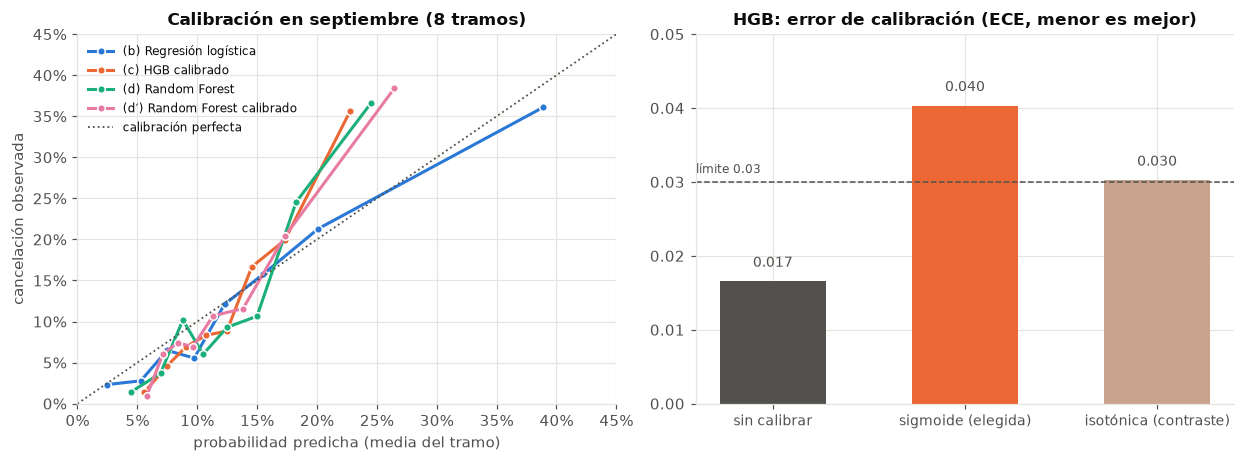

Tasa observada en septiembre: 12,8 %


,Brier,ECE,prob. media predicha,PR-AUC
sin calibrar,0.1019,0.0165,0.1268,0.2931
sigmoide (elegida),0.1036,0.0403,0.1250,0.2932
isotónica (contraste),0.1027,0.0302,0.1262,0.3029


In [37]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3))
colores = {'(b) Regresión logística': AZUL, '(c) HGB calibrado': NARANJA, '(d) Random Forest': AQUA, '(d′) Random Forest calibrado': MAGENTA}
y_te = y_all[es_corte(CORTES[-1])]
for k, col in colores.items():
    d = pd.DataFrame({'y': y_te, 'p': PRED['Marzo+Junio → Septiembre'][k]}); d['t'] = pd.qcut(d.p, 8, labels=False, duplicates='drop')
    g = d.groupby('t').agg(p=('p', 'mean'), y=('y', 'mean'))
    ax[0].plot(g.p, g.y, marker='o', markersize=5, markeredgecolor='white', linewidth=2, color=col, label=k)
lim = 0.45; ax[0].plot([0, lim], [0, lim], color=INK2, linestyle=':', linewidth=1.2, label='calibración perfecta')
ax[0].set_xlim(0, lim); ax[0].set_ylim(0, lim); ax[0].set_xlabel('probabilidad predicha (media del tramo)'); ax[0].set_ylabel('cancelación observada')
ax[0].xaxis.set_major_formatter(lambda v, _: f'{100*v:.0f}%'); ax[0].yaxis.set_major_formatter(lambda v, _: f'{100*v:.0f}%')
ax[0].set_title('Calibración en septiembre (8 tramos)'); ax[0].legend(frameon=False, fontsize=8, loc='upper left')

# Efecto de calibrar el HGB
tr_m = np.isin(corte_all, np.array(CORTES[:2], dtype='datetime64[ns]')); te_m = es_corte(CORTES[-1])
variantes = {'sin calibrar': dict(tipo='hgb', excluir=EXCLUIR_FINAL, monotona=USAR_MONOTONIA),
             'sigmoide (elegida)': dict(tipo='hgb', excluir=EXCLUIR_FINAL, monotona=USAR_MONOTONIA, calibrar='sigmoid'),
             'isotónica (contraste)': dict(tipo='hgb', excluir=EXCLUIR_FINAL, monotona=USAR_MONOTONIA, calibrar='isotonic')}
cal = {k: entrenar_predecir(s, tr_m, te_m) for k, s in variantes.items()}
cal_tab = pd.DataFrame({k: {'Brier': brier_score_loss(y_te, p), 'ECE': ece(y_te, p), 'prob. media predicha': p.mean(), 'PR-AUC': average_precision_score(y_te, p)} for k, p in cal.items()}).T
ax[1].bar(range(3), cal_tab.ECE, color=[INK2, NARANJA, '#c9a38c'], width=0.55)
for i, v in enumerate(cal_tab.ECE): ax[1].text(i, v + 0.002, f'{v:.3f}', ha='center', fontsize=9, color=INK2)
ax[1].axhline(ECE_MAX, color=INK2, linestyle='--', linewidth=1); ax[1].text(-0.4, ECE_MAX + 0.0012, f'límite {ECE_MAX}', fontsize=8, color=INK2, ha='left'); ax[1].set_ylim(0, 0.05)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(cal_tab.index, fontsize=9); ax[1].set_title('HGB: error de calibración (ECE, menor es mejor)')
plt.tight_layout(); plt.show()
print(f'Tasa observada en septiembre: {pct_es(y_te.mean())}')
display(cal_tab.round(4))

**Lectura.**
- Todos los modelos siguen razonablemente la diagonal, pero el tramo de **mayor riesgo** es el que más falla: **los modelos de árboles lo subestiman** (predicen 23–26 % donde cancela el 36–38 %); la logística lo sobreestima apenas (39 % vs 36 %). Para el umbral importa, porque son justo los clientes que se contactan.
- **Calibrar con sigmoide empeoró al HGB** (ECE 0,040 frente a 0,017 sin calibrar; la isotónica queda en 0,030). Con ~3.000 filas de entrenamiento y 13 % de positivos, la calibración añade ruido en lugar de quitarlo. Mantengo (c) *calibrado* como se fijó de antemano, pero lo señalo: **si se eligiera el HGB, usaría la versión sin calibrar**. (La elección final no cambia, ver 5.8.)

**Zoom donde actúan los umbrales.** Los umbrales por plan caen entre 0,087 y 0,218, así que lo que importa es qué tan fiable es la probabilidad **entre 0,05 y 0,30**. Abajo, tramos fijos de 0,05 en esa zona, para la logística, el HGB calibrado y el Random Forest, en septiembre (entrenado con marzo+junio) y en junio (entrenado con marzo); las barras son ±1,96 errores estándar de la tasa observada y las líneas punteadas, los umbrales de cada plan.

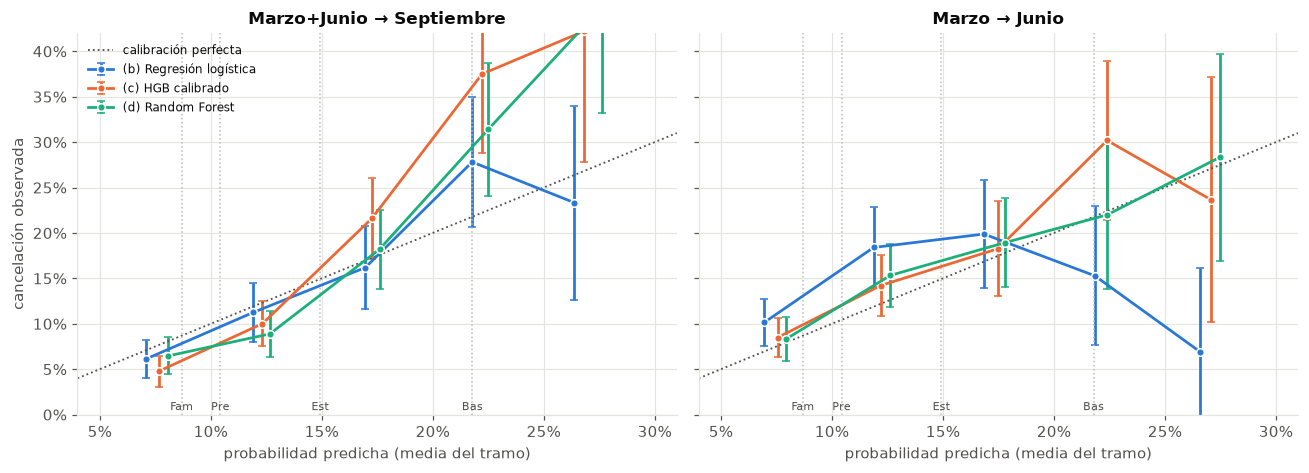

clientes  \
validación               modelo                  tramo                                        
Marzo+Junio → Septiembre (b) Regresión logística [0.05, 0.1)                            489   
                                                 [0.1, 0.15)                            373   
                                                 [0.15, 0.2)                            247   
                                                 [0.2, 0.25)                            151   
                                                 [0.25, 0.3)                             60   
                                                 fracción de clientes en 0,05–0,30            
                         (c) HGB calibrado       [0.05, 0.1)                            607   
                                                 [0.1, 0.15)                            579   
                                                 [0.15, 0.2)                            324   
                                                 [0.2, 0.25)                            120   
                                                 [0.25, 0.3)                             45   
                                                 fracción de clientes en 0,05–0,30            
                         (d) Random Forest       [0.05, 0.1)                            557   
                                                 [0.1, 0.15)                            495   
                                                 [0.15, 0.2)                            302   
                                                 [0.2, 0.25)                            156   
                                                 [0.25, 0.3)                             69   
                                                 fracción de clientes en 0,05–0,30            
Marzo → Junio            (b) Regresión logística [0.05, 0.1)                            522   
                                                 [0.1, 0.15)                            288   
                                                 [0.15, 0.2)                            171   
                                                 [0.2, 0.25)                             85   
                                                 [0.25, 0.3)                             29   
                                                 fracción de clientes en 0,05–0,30            
                         (c) HGB calibrado       [0.05, 0.1)                            625   
                                                 [0.1, 0.15)                            422   
                                                 [0.15, 0.2)                            208   
                                                 [0.2, 0.25)                            106   
                                                 [0.25, 0.3)                             38   
                                                 fracción de clientes en 0,05–0,30            
                         (d) Random Forest       [0.05, 0.1)                            506   
                                                 [0.1, 0.15)                            424   
                                                 [0.15, 0.2)                            243   
                                                 [0.2, 0.25)                            100   
                                                 [0.25, 0.3)                             60   
                                                 fracción de clientes en 0,05–0,30            

                                                                                    predicho  \
validación               modelo                  tramo                                         
Marzo+Junio → Septiembre (b) Regresión logística [0.05, 0.1)                           0.075   
                                                 [0.1, 0.15)                           0.123   
                                                 [0.15, 0.2)                           0

In [38]:
BINS_ZOOM = np.array([0.05, 0.10, 0.15, 0.20, 0.25, 0.30])
def calib_zoom(y, p):
    d = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p)})
    d = d[(d.p >= BINS_ZOOM[0]) & (d.p < BINS_ZOOM[-1])].copy()
    d['tramo'] = pd.cut(d.p, BINS_ZOOM, right=False)
    g = d.groupby('tramo', observed=True).agg(n=('y', 'size'), pred=('p', 'mean'), obs=('y', 'mean'))
    g['se'] = np.sqrt(g.obs * (1 - g.obs) / g.n)
    return g

MODELOS_ZOOM = {'(b) Regresión logística': AZUL, '(c) HGB calibrado': NARANJA, '(d) Random Forest': AQUA}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
filas_zoom = []
for a, (nf_, c_) in zip(ax, [('Marzo+Junio → Septiembre', CORTES[2]), ('Marzo → Junio', CORTES[1])]):
    y_z = y_all[es_corte(c_)]
    for off, (k, col) in zip([-0.004, 0, 0.004], MODELOS_ZOOM.items()):
        g = calib_zoom(y_z, PRED[nf_][k])
        a.errorbar(g.pred + off, g.obs, yerr=1.96 * g.se, marker='o', markersize=5, markeredgecolor='white', linewidth=1.8, capsize=2.5, color=col, label=k)
        for t, r in g.iterrows(): filas_zoom.append({'validación': nf_, 'modelo': k, 'tramo': str(t), 'clientes': int(r.n), 'predicho': round(r.pred, 3), 'observado': round(r.obs, 3)})
        en_zona = ((PRED[nf_][k] >= BINS_ZOOM[0]) & (PRED[nf_][k] < BINS_ZOOM[-1])).mean()
        filas_zoom.append({'validación': nf_, 'modelo': k, 'tramo': 'fracción de clientes en 0,05–0,30', 'clientes': '', 'predicho': round(en_zona, 3), 'observado': ''})
    a.plot([0.04, 0.31], [0.04, 0.31], color=INK2, linestyle=':', linewidth=1.2, label='calibración perfecta')
    for plan_, thr in UMBRAL_PLAN.items(): a.axvline(thr, color='#bbbbbb', linestyle=':', linewidth=1); a.text(thr, 0.005, plan_[:3], fontsize=7.5, color=INK2, ha='center')
    a.set_xlim(0.04, 0.31); a.set_ylim(0, 0.42); a.set_title(nf_); a.set_xlabel('probabilidad predicha (media del tramo)')
    a.xaxis.set_major_formatter(lambda v, _: f'{100*v:.0f}%'); a.yaxis.set_major_formatter(lambda v, _: f'{100*v:.0f}%')
ax[0].set_ylabel('cancelación observada'); ax[0].legend(frameon=False, fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()
display(pd.DataFrame(filas_zoom).set_index(['validación', 'modelo', 'tramo']))

**Lectura** (cada punto tiene un error de unos ±0,03–0,06 en los tramos de 150–500 clientes y de ±0,10 o más en los de menos de 100: miro la tendencia, no cada punto).
- **Septiembre:** la logística sigue bien la diagonal en toda la zona (predicho 0,075 / 0,123 / 0,174 / 0,222 / 0,268 frente a observado 0,061 / 0,113 / 0,162 / 0,278 / 0,233; diferencias dentro del error). Los árboles **subestiman desde 0,20**: el HGB predice 0,222 y observa 0,375; predice 0,268 y observa 0,422; el Random Forest predice 0,273 y observa 0,449. Ahí está justo el umbral del Básico (0,218): con árboles se contactaría de menos a Básicos de riesgo alto.
- **Junio** (entrenado solo con marzo): ningún modelo queda limpio. La logística **subestima los tramos bajos** (predice 0,074 y observa 0,102; predice 0,123 y observa 0,184) y su último tramo (29 clientes) es solo ruido; los árboles lo hacen algo mejor ahí (HGB: 0,076 → 0,085 y 0,122 → 0,142).
- **Conclusión:** la calibración de la logística es buena con el régimen de septiembre y menos estable con poco historial. Por eso la uso como **apoyo** y no como criterio decisivo.

### 5.7 Subgrupos de septiembre y el plan Básico

Los promedios pueden esconder diferencias: miro los subgrupos que el análisis previo señaló. En **septiembre**, iOS / no iOS y, dentro de iOS, con / sin la 5.2.0 (con intervalos). Y el **Básico** por separado en junio y septiembre, que era la preocupación del alza de precio: en junio el modelo se entrena solo con marzo, cuando el Básico aún no había subido.

In [39]:
def tabla_subgrupos(nombre_fold, te_c, grupos):
    te = es_corte(te_c); d = datos_modelo[te].reset_index(drop=True); y_te = y_all[te]; plan_te = plan_all[te].reset_index(drop=True)
    filas = []
    for gname, mask in grupos(d).items():
        mk = np.asarray(mask)
        preds = {k: np.asarray(p)[mk] for k, p in PRED[nombre_fold].items()}
        nombres, bs = bootstrap(y_te[mk], preds, plan_te[mk])
        for j, k in enumerate(nombres):
            m = metricas(y_te[mk], preds[k], plan_te[mk])
            filas.append({'subgrupo': gname, 'clientes': int(mk.sum()), 'cancelan': int(y_te[mk].sum()), 'modelo': k,
                          'PR-AUC [IC 95 %]': fmt(m['pr_auc'], *_ic(bs['pr_auc'][:, j])),
                          'valor COP, millones [IC 95 %]': fmt(m['valor'] / 1e6, *[v / 1e6 for v in _ic(bs['valor'][:, j])], d=2)})
    return pd.DataFrame(filas).set_index(['subgrupo', 'clientes', 'cancelan', 'modelo'])

print('SEPTIEMBRE por plataforma y versión:')
display(tabla_subgrupos('Marzo+Junio → Septiembre', CORTES[2], lambda d: {
    'no iOS': d.plataforma_principal != 'ios', 'iOS': d.plataforma_principal == 'ios',
    'iOS con 5.2.0': (d.plataforma_principal == 'ios') & (d.usa_5_2_0 == 1), 'iOS sin 5.2.0': (d.plataforma_principal == 'ios') & (d.usa_5_2_0 == 0)}))
print('PLAN BÁSICO frente al resto, en junio (entrenado solo con marzo) y en septiembre:')
for nf, c in [('Marzo → Junio', CORTES[1]), ('Marzo+Junio → Septiembre', CORTES[2])]:
    print(f'— {nf}'); display(tabla_subgrupos(nf, c, lambda d: {'Básico': d.plan == 'Basico', 'otros planes': d.plan != 'Basico'}))

SEPTIEMBRE por plataforma y versión:


PR-AUC [IC 95 %]  \
subgrupo      clientes cancelan modelo                                              
no iOS        1172     115      (a) Regla simple (mora)       0.111 [0.089–0.137]   
                                (b) Regresión logística       0.305 [0.232–0.403]   
                                (c) HGB calibrado             0.239 [0.184–0.321]   
                                (d) Random Forest             0.251 [0.190–0.336]   
                                (d′) Random Forest calibrado  0.237 [0.182–0.318]   
iOS           555      106      (a) Regla simple (mora)       0.188 [0.157–0.225]   
                                (b) Regresión logística       0.352 [0.282–0.453]   
                                (c) HGB calibrado             0.346 [0.280–0.437]   
                                (d) Random Forest             0.382 [0.311–0.480]   
                                (d′) Random Forest calibrado  0.386 [0.314–0.484]   
iOS con 5.2.0 350      88       (a) Regla simple (mora)       0.246 [0.203–0.296]   
                                (b) Regresión logística       0.404 [0.320–0.513]   
                                (c) HGB calibrado             0.410 [0.326–0.519]   
                                (d) Random Forest             0.463 [0.366–0.584]   
                                (d′) Random Forest calibrado  0.476 [0.379–0.596]   
iOS sin 5.2.0 205      18       (a) Regla simple (mora)       0.087 [0.052–0.132]   
                                (b) Regresión logística       0.217 [0.101–0.391]   
                                (c) HGB calibrado             0.231 [0.128–0.419]   
                                (d) Random Forest             0.263 [0.135–0.474]   
                                (d′) Random Forest calibrado  0.263 [0.137–0.474]   

                                                             valor COP, millones [IC 95 %]  
subgrupo      clientes cancelan modelo                                                      
no iOS        1172     115      (a) Regla simple (mora)                 -0.69 [-3.75–2.48]  
                                (b) Regresión logística                   4.40 [1.78–7.01]  
                                (c) HGB calibrado                         3.19 [0.49–6.00]  
                                (d) Random Forest                         4.12 [1.18–7.08]  
                                (d′) Random Forest calibrado              4.26 [1.59–6.91]  
iOS           555      106      (a) Regla simple (mora)                   3.95 [1.01–6.72]  
                                (b) Regresión logística                  7.27 [3.97–10.57]  
                                (c) HGB calibrado                        7.50 [4.27–10.74]  
                                (d) Random Forest                        7.58 [4.43–10.73]  
                                (d′) Random Forest calibrado             8.08 [4.90–11.25]  
iOS con 5.2.0 350      88       (a) Regla simple (mora)                   4.84 [2.33–7.45]  
                                (b) Regresión logística                  7.37 [4.76–10.23]  
                                (c) HGB calibrado                        7.36 [4.52–10.30]  
                                (d) Random Forest                        7.76 [5.13–10.54]  
                                (d′) Random Forest calibrado             8.13 [5.52–10.94]  
iOS sin 5.2.0 205      18       (a) Regla simple (mora)                 -0.88 [-1.87–0.18]  
                                (b) Regresión logística                 -0.10 [-1.24–1.13]  
                                (c) HGB calibrado                        0.14 [-0.97–1.30]  
                                (d) Random Forest                       -0.18 [-1.20–0.94]  
                                (d′) Random Forest calibrado            -0.06 [-1.07–1.04]

PLAN BÁSICO frente al resto, en junio (entrenado solo con marzo) y en septiembre:
— Marzo → Junio


PR-AUC [IC 95 %]  \
subgrupo     clientes cancelan modelo                                              
Básico       538      82       (a) Regla simple (mora)       0.159 [0.126–0.197]   
                               (b) Regresión logística       0.282 [0.203–0.368]   
                               (c) HGB calibrado             0.260 [0.196–0.357]   
                               (d) Random Forest             0.261 [0.198–0.354]   
                               (d′) Random Forest calibrado  0.265 [0.200–0.355]   
otros planes 1050     128      (a) Regla simple (mora)       0.124 [0.102–0.148]   
                               (b) Regresión logística       0.222 [0.167–0.291]   
                               (c) HGB calibrado             0.204 [0.156–0.269]   
                               (d) Random Forest             0.206 [0.155–0.275]   
                               (d′) Random Forest calibrado  0.201 [0.155–0.268]   

                                                            valor COP, millones [IC 95 %]  
subgrupo     clientes cancelan modelo                                                      
Básico       538      82       (a) Regla simple (mora)                   0.00 [0.00–0.00]  
                               (b) Regresión logística                  0.32 [-0.40–1.08]  
                               (c) HGB calibrado                        0.47 [-0.23–1.27]  
                               (d) Random Forest                        0.23 [-0.39–0.92]  
                               (d′) Random Forest calibrado             0.48 [-0.24–1.35]  
otros planes 1050     128      (a) Regla simple (mora)                  2.26 [-1.06–5.53]  
                               (b) Regresión logística                   4.31 [1.23–7.33]  
                               (c) HGB calibrado                         5.35 [1.76–8.79]  
                               (d) Random Forest                         4.74 [1.18–8.16]  
                               (d′) Random Forest calibrado              5.35 [1.88–8.73]

— Marzo+Junio → Septiembre


PR-AUC [IC 95 %]  \
subgrupo     clientes cancelan modelo                                              
Básico       575      82       (a) Regla simple (mora)       0.149 [0.117–0.186]   
                               (b) Regresión logística       0.301 [0.225–0.404]   
                               (c) HGB calibrado             0.283 [0.212–0.376]   
                               (d) Random Forest             0.305 [0.230–0.409]   
                               (d′) Random Forest calibrado  0.294 [0.219–0.399]   
otros planes 1152     139      (a) Regla simple (mora)       0.125 [0.106–0.149]   
                               (b) Regresión logística       0.351 [0.280–0.430]   
                               (c) HGB calibrado             0.311 [0.245–0.389]   
                               (d) Random Forest             0.350 [0.272–0.428]   
                               (d′) Random Forest calibrado  0.340 [0.265–0.421]   

                                                            valor COP, millones [IC 95 %]  
subgrupo     clientes cancelan modelo                                                      
Básico       575      82       (a) Regla simple (mora)                   0.00 [0.00–0.00]  
                               (b) Regresión logística                  1.17 [-0.02–2.35]  
                               (c) HGB calibrado                         0.81 [0.02–1.66]  
                               (d) Random Forest                         1.17 [0.24–2.16]  
                               (d′) Random Forest calibrado              1.12 [0.15–2.12]  
otros planes 1152     139      (a) Regla simple (mora)                  3.27 [-0.76–7.53]  
                               (b) Regresión logística                 10.51 [6.58–14.46]  
                               (c) HGB calibrado                        9.87 [5.99–14.15]  
                               (d) Random Forest                       10.52 [6.55–14.73]  
                               (d′) Random Forest calibrado            11.21 [7.37–15.23]

**Lectura.**
- **El valor de la decisión se concentra en iOS con 5.2.0:** ese subgrupo (350 clientes, 88 cancelaciones, 25 %) aporta ~7,4 de los ~11,7 M COP de la logística. **El modelo los encuentra aunque no tenga las variables de la 5.2.0** (PR-AUC 0,40–0,48), probablemente por otras señales (uso, tickets). En **iOS sin 5.2.0** (205 clientes, 18 cancelaciones) el valor es ≈ 0 con intervalos que cruzan 0: ahí no hay nada que ganar contactando.
- **Fuera de iOS** la logística rinde mejor que los árboles (PR-AUC 0,31 vs 0,24–0,25; intervalos solapados), y en iOS los árboles son algo mejores (0,38 vs 0,35; también solapados). Es el mismo patrón de "sin diferencias demostrables".
- **Plan Básico:** su ranking es tan bueno como el del resto (junio: PR-AUC 0,26–0,28 vs 0,20–0,22 en los otros planes, aun entrenando solo con marzo, antes del alza), así que **el cambio de régimen de precio no deterioró el modelo**. Pero su **valor es pequeño** (0,2–1,2 M COP, intervalos que casi siempre cruzan 0) por la economía: el umbral del Básico es el más alto (0,218) y retener a un cancelador Básico solo deja 89.720 COP esperados.

### 5.8 Elección del modelo: la regla D aplicada de forma mecánica

Para que la elección no dependa de mi criterio del momento, aplico en código la regla fijada en 5.2: (1) descartar a quien sea **significativamente inferior** al mejor en PR-AUC; (2) descartar a quien tenga **ECE > 0,03** en septiembre; (3) mirar la **estabilidad** (posición en cada validación); (4) si queda más de uno, gana el **más simple**.

In [40]:
SIMPLICIDAD = ['(a) Regla simple (mora)', '(b) Regresión logística', '(c) HGB calibrado', '(d) Random Forest', '(d′) Random Forest calibrado']
nf = 'Marzo+Junio → Septiembre'
nombres_f, bs_f = BS[nf]
met = {k: metricas(y_sep, PRED[nf][k], plan_sep) for k in nombres_f}
mejor = max(met, key=lambda k: met[k]['pr_auc']); j0 = nombres_f.index(mejor)
filas = []
for j, k in enumerate(nombres_f):
    d = bs_f['pr_auc'][:, j] - bs_f['pr_auc'][:, j0]; lo, hi = _ic(d)
    inferior = (k != mejor) and hi < 0
    filas.append({'modelo': k, 'PR-AUC': round(met[k]['pr_auc'], 3), 'Δ frente al mejor [IC 95 %]': 'el mejor' if k == mejor else fmt(np.nanmean(d), lo, hi),
                  '1) ¿significativamente inferior?': 'SÍ → fuera' if inferior else 'no',
                  'ECE': round(met[k]['ece'], 3), '2) ¿ECE > 0,03?': 'SÍ → fuera' if met[k]['ece'] > ECE_MAX else 'no',
                  'queda': (not inferior) and met[k]['ece'] <= ECE_MAX})
paso = pd.DataFrame(filas).set_index('modelo'); display(paso.drop(columns='queda'))
quedan = [k for k in SIMPLICIDAD if k in paso.index and paso.loc[k, 'queda']]
if not quedan:        # salvaguarda: si ninguno cumple el ECE, se queda con los no inferiores y se elige el de menor ECE
    quedan = [min([k for k in paso.index if '→ fuera' not in paso.loc[k, '1) ¿significativamente inferior?']], key=lambda k: met[k]['ece'])]
MODELO_ELEGIDO = quedan[0]                        # lista en orden de simplicidad
print('Tras los pasos 1 y 2 quedan:', quedan, '→ paso 4 (el más simple):', MODELO_ELEGIDO)
sin_ece = [k for k in SIMPLICIDAD if paso.loc[k, '1) ¿significativamente inferior?'] == 'no']
print('Sensibilidad — SIN el filtro de ECE (solo pasos 1 y 4) quedarían:', sin_ece, '→ el más simple:', sin_ece[0])

# Paso 3: estabilidad — posición (1 = mejor) por PR-AUC en cada validación y en cada subgrupo
d_sep = datos_modelo[es_corte(CORTES[2])].reset_index(drop=True); d_jun = datos_modelo[es_corte(CORTES[1])].reset_index(drop=True)
y_jun = y_all[es_corte(CORTES[1])]; ios_m = (d_sep.plataforma_principal == 'ios').values; bas_m = (d_sep.plan == 'Basico').values
escenarios = {'Marzo→Junio': (y_jun, PRED['Marzo → Junio'], None), 'Mar+Jun→Septiembre': (y_sep, PRED[nf], None),
              'Dentro de septiembre (agrupada)': (y_sep, PRED_CV, None), 'Sep: iOS': (y_sep, PRED[nf], ios_m), 'Sep: no iOS': (y_sep, PRED[nf], ~ios_m),
              'Sep: Básico': (y_sep, PRED[nf], bas_m), 'Sep: otros planes': (y_sep, PRED[nf], ~bas_m)}
pr_esc = pd.DataFrame({e: {k: average_precision_score(y[m] if m is not None else y, np.asarray(P[k])[m] if m is not None else P[k]) for k in SIMPLICIDAD}
                       for e, (y, P, m) in escenarios.items()})
print('\nPaso 3 — PR-AUC en cada escenario (arriba) y posición de cada modelo (1 = mejor):')
display(pr_esc.round(3)); display(pr_esc.rank(ascending=False).astype(int))

,PR-AUC,Δ frente al mejor [IC 95 %],1) ¿significativamente inferior?,ECE,"2) ¿ECE > 0,03?"
modelo,,,,,
(a) Regla simple (mora),0.134,-0.194 [-0.251–-0.144],SÍ → fuera,0.004,no
(b) Regresión logística,0.323,el mejor,no,0.026,no
(c) HGB calibrado,0.293,-0.032 [-0.082–0.017],no,0.040,SÍ → fuera
(d) Random Forest,0.317,-0.007 [-0.049–0.037],no,0.043,SÍ → fuera
(d′) Random Forest calibrado,0.308,-0.016 [-0.062–0.034],no,0.033,SÍ → fuera


Tras los pasos 1 y 2 quedan: ['(b) Regresión logística'] → paso 4 (el más simple): (b) Regresión logística
Sensibilidad — SIN el filtro de ECE (solo pasos 1 y 4) quedarían: ['(b) Regresión logística', '(c) HGB calibrado', '(d) Random Forest', '(d′) Random Forest calibrado'] → el más simple: (b) Regresión logística

Paso 3 — PR-AUC en cada escenario (arriba) y posición de cada modelo (1 = mejor):


,Marzo→Junio,Mar+Jun→Septiembre,Dentro de septiembre (agrupada),Sep: iOS,Sep: no iOS,Sep: Básico,Sep: otros planes
(a) Regla simple (mora),0.136,0.134,0.120,0.188,0.111,0.149,0.125
(b) Regresión logística,0.242,0.323,0.309,0.352,0.305,0.301,0.351
(c) HGB calibrado,0.222,0.293,0.315,0.346,0.239,0.283,0.311
(d) Random Forest,0.223,0.317,0.332,0.382,0.251,0.305,0.350
(d′) Random Forest calibrado,0.221,0.308,0.328,0.386,0.237,0.294,0.340


,Marzo→Junio,Mar+Jun→Septiembre,Dentro de septiembre (agrupada),Sep: iOS,Sep: no iOS,Sep: Básico,Sep: otros planes
(a) Regla simple (mora),5,5,5,5,5,5,5
(b) Regresión logística,1,1,4,3,1,2,1
(c) HGB calibrado,3,4,3,4,3,4,4
(d) Random Forest,2,2,1,2,2,1,2
(d′) Random Forest calibrado,4,3,2,1,4,3,3


**Elección: la regresión logística.** Se apoya en **dos razones**; la calibración es solo un apoyo.

1. **No hay diferencias significativas entre los modelos de aprendizaje.** Frente a la logística, ningún intervalo de la diferencia pareada excluye 0, ni en septiembre hacia adelante ni en la validación agrupada dentro de septiembre (PR-AUC y valor). Solo la regla simple queda atrás con claridad (+0,19 de PR-AUC y +8,4 M COP a favor de la logística, con intervalos que excluyen 0). La logística tiene PR-AUC de **0,323 [0,275–0,388]** en septiembre (2,5 veces la tasa base de 12,8 %) y un valor de **11,7 M COP [7,6–15,9]**, el 35 % del máximo posible.
2. **Simplicidad.** Con diferencias no demostrables gana el modelo más simple (regla fijada de antemano): sus coeficientes se leen y se explican a gerencia, no tiene hiperparámetros que ajustar y no necesita calibración aparte.
3. **Solo como apoyo: la calibración.** El ECE no tiene intervalo y no es consistente entre validaciones: la logística es la mejor de los modelos de aprendizaje en septiembre (0,026) pero **la peor en junio (0,042)**. El filtro de ECE ≤ 0,03 de la regla D sí eliminó a los árboles, pero **no es lo que decide**: sin ese filtro (celda anterior) quedan cuatro modelos y el criterio del más simple elige igual la logística. En la zona de 0,05–0,30, donde actúan los umbrales, la logística sigue la diagonal en septiembre y los árboles subestiman por encima de 0,20; en junio ningún modelo es limpio y la logística subestima los tramos bajos (curvas de 5.6).

**Estabilidad.** Su posición (de 1 a 5) cambia con el escenario: **1.ª** en junio y en septiembre hacia adelante, **1.ª** fuera de iOS y en los planes que no son Básico, 2.ª en el Básico, 3.ª en iOS y **4.ª en la validación agrupada dentro de septiembre** (donde los árboles le sacan 0,006–0,023 de PR-AUC, sin diferencia significativa). Lo estable es que **siempre queda muy por encima de la regla y dentro del grupo de cabeza**.

**Nota sobre las variables de la 5.2.0.** La comparación de modelos de las secciones 5.4–5.8 se hizo **sin** esas variables, porque en la validación hacia adelante no pueden aprenderse (en el entrenamiento valen siempre lo mismo). Si se incluyeran en el modelo final (la alternativa razonable, ver 5.3 ter y 6.1), esa comparación no cambia; lo que cambia es la sección 6. El modelo final **no** las lleva por una decisión conservadora y declarada, no por una regla fijada de antemano.

**Lo que esta elección NO dice.** No dice que la logística sea *mejor* que el Random Forest o el HGB: con ~1.700 clientes y ~220 cancelaciones los intervalos son demasiado anchos para afirmarlo, y en la partición agrupada el Random Forest queda primero en puntos. Elijo por **calibración, simplicidad y robustez**, no por un ganador de puntos. Y el umbral de cada plan **sale de la economía** (0,218 / 0,149 / 0,104 / 0,087): **nunca se ajustó sobre la validación**.

**Un matiz honesto sobre la partición.** Los árboles ganan en la validación agrupada dentro de septiembre, donde el modelo **sí entrena con el régimen de la 5.2.0**, y la logística gana hacia adelante, donde tiene que extrapolar. El modelo final se entrenará con los tres cortes, **incluido septiembre**, así que se parece algo más al escenario agrupado. No lo tomo como razón para cambiar de modelo (las diferencias no son significativas y la logística está mejor calibrada), pero es **la primera cosa que reviso si en producción los árboles resultaran mejores**.

**Qué me haría dudar de este modelo** (para la parte 6): la calibración del tramo alto con datos de un solo régimen de la app; que `antiguedad_dias` y `dias_en_plan` en la cartera de diciembre están más altos que en entrenamiento y un modelo lineal los extrapola; que el ECE de la logística en junio (0,042) fue el peor; y que el valor estimado tiene un intervalo de ±4 M COP.

---
<a id="s6"></a>

## 6. Decisión de negocio: a quién contactar el 31-12-2025

Con el modelo elegido en la sección 5 (**regresión logística**; va **sin** las variables de la 5.2.0 por una decisión conservadora y declarada en 5.3 ter; la tabla «con / sin» de 6.1 muestra cuánto cambiaría con ellas) hago lo siguiente:
1. Lo **entreno con los tres cortes** (4.709 filas, septiembre incluido) y **puntúo a los 1.610 clientes activos al 31-12-2025**, con el plan y el precio vigentes de cada uno.
2. **Contacto** a quien supere el **umbral de su plan** (sale de la economía, no se ajusta con datos).
3. Estimo el **valor esperado**, el **número de contactos** y su **sensibilidad** a la efectividad de la oferta y al costo de contacto.
4. Escribo `predicciones.csv` y lo valido.

> **Para rehacer esta decisión tras cambiar un parámetro** (costo, efectividad, precios, umbral fijo, modelo final, variables quitadas, `INCLUIR_5_2_0` o `MAX_CONTACTOS`): ejecuta la celda de **5.1 (economía)** y **todas las celdas de esta sección 6**. No hace falta tocar nada más.

El valor esperado de contactar a un cliente con probabilidad `p` es `p × efectividad × (12 × precio) − costo`. Es una **esperanza que supone la probabilidad bien calibrada**; el resultado real variará.

In [41]:
# ── 6.1 Las dos versiones del modelo final (sin y con las variables de la 5.2.0) ──
MODELO_USADO = MODELO_FINAL if MODELO_FINAL is not None else MODELO_ELEGIDO     # parámetro MODELO_FINAL, o el que eligió la regla de 5.8
ES_LOGISTICA = ESPEC[MODELO_USADO]['tipo'] == 'logistica'
espec_final = lambda excl: {**ESPEC[MODELO_USADO], 'excluir': tuple(sorted(set(excl) | set(EXCLUIR_EXTRA)))}
print('Modelo usado:', MODELO_USADO, '| variables quitadas a mano (EXCLUIR_EXTRA):', EXCLUIR_EXTRA, '| umbral fijo:', UMBRAL_FIJO)
XP = matriz(X_puntuar)
plan_p = X_puntuar.plan.reset_index(drop=True)
assert plan_p.isin(PRECIO_VIGENTE.keys()).all()
V_p = plan_p.map(V_RETENER).values.astype(float)
def valor_esperado(p, V, contactos, ef=EFECTIVIDAD, costo=COSTO_CONTACTO):
    return float(np.sum(contactos * (p * ef * V - costo)))
def decision(p, V, ef=EFECTIVIDAD, costo=COSTO_CONTACTO):
    return (p >= costo / (ef * V)).astype(int)                  # umbral por cliente según su plan

VERSIONES = {'sin las variables de la 5.2.0': tuple(VARS_520), 'con las tres variables': ()}
VERSION_FINAL = 'con las tres variables' if (INCLUIR_5_2_0 or not EXCLUIR_LOGISTICA) else 'sin las variables de la 5.2.0'   # INCLUIR_5_2_0 = False (defecto): la decisión de 5.3 ter
PROB, CONT, MOD = {}, {}, {}
for k, excl in VERSIONES.items():
    MOD[k] = Modelo(**espec_final(excl)).fit(XM, y_all, g_all)                                  # entrenado con los 3 cortes
    PROB[k] = np.round(MOD[k].predict(XP), 6)                                                 # se redondea ANTES de decidir: el archivo es consistente con el umbral
    CONT[k] = decidir(PROB[k], plan_p)
    if UMBRAL_FIJO is None: assert (decision(PROB[k], V_p) == CONT[k]).all()                  # la misma regla por dos caminos

# Backtest de septiembre de cada versión: hacia adelante (donde las variables no pueden aprenderse) y agrupado dentro de septiembre (donde sí)
tr_s, te_s = np.isin(corte_all, np.array(CORTES[:2], dtype='datetime64[ns]')), es_corte(CORTES[2])
BT_FWD = {k: Modelo(**espec_final(excl)).fit(XM[tr_s], y_all[tr_s], g_all[tr_s]).predict(XM[te_s]) for k, excl in VERSIONES.items()}
BT_CV = ({'sin las variables de la 5.2.0': oofL['A (sin variables 5.2.0)'].mean(0), 'con las tres variables': oofL['B (con variables 5.2.0)'].mean(0)} if ES_LOGISTICA and not EXCLUIR_EXTRA
         else {k: cv_sep_modelo(espec_final(excl)) for k, excl in VERSIONES.items()})
tb_f, _ = tabla_metricas(y_sep, BT_FWD, plan_sep); tb_c, _ = tabla_metricas(y_sep, BT_CV, plan_sep)
cols_bt = ['PR-AUC [IC 95 %]', 'valor COP, millones [IC 95 %]']
comp = pd.concat({'Hacia adelante (Mar+Jun → Sep)': tb_f[cols_bt], 'Agrupada dentro de septiembre': tb_c[cols_bt]}, names=['backtest', 'versión'])
display(comp)
print('Diferencia (con − sin), hacia adelante:'); display(diferencias(*bootstrap(y_sep, {'sin': BT_FWD['sin las variables de la 5.2.0'], 'con': BT_FWD['con las tres variables']}, plan_sep), 'sin'))
print('Diferencia (con − sin), agrupada dentro de septiembre:'); display(diferencias(*bootstrap(y_sep, {'sin': BT_CV['sin las variables de la 5.2.0'], 'con': BT_CV['con las tres variables']}, plan_sep), 'sin'))

filas = []
for k in VERSIONES:
    filas.append({'versión': k + (' ← usada' if k == VERSION_FINAL else ''), 'contactos (de 1.610)': int(CONT[k].sum()),
                  'valor esperado, M COP': round(valor_esperado(PROB[k], V_p, CONT[k]) / 1e6, 2),
                  'contactos de iOS con 5.2.0': int((CONT[k] * ((X_puntuar.plataforma_principal == 'ios') & (X_puntuar.usa_5_2_0 == 1)).values).sum())})
display(pd.DataFrame(filas).set_index('versión'))
distintos = int((CONT['sin las variables de la 5.2.0'] != CONT['con las tres variables']).sum())
print(f'Clientes cuya decisión cambia entre las dos versiones: {distintos} de {len(CONT[VERSION_FINAL])}')

Modelo usado: (b) Regresión logística | variables quitadas a mano (EXCLUIR_EXTRA): [] | umbral fijo: None


PR-AUC [IC 95 %]  \
backtest                       versión                                              
Hacia adelante (Mar+Jun → Sep) sin las variables de la 5.2.0  0.323 [0.275–0.388]   
                               con las tres variables         0.317 [0.270–0.383]   
Agrupada dentro de septiembre  sin las variables de la 5.2.0  0.303 [0.257–0.372]   
                               con las tres variables         0.335 [0.280–0.402]   

                                                             valor COP, millones [IC 95 %]  
backtest                       versión                                                      
Hacia adelante (Mar+Jun → Sep) sin las variables de la 5.2.0            11.68 [7.55–15.90]  
                               con las tres variables                   12.52 [8.25–16.93]  
Agrupada dentro de septiembre  sin las variables de la 5.2.0            10.88 [7.07–14.88]  
                               con las tres variables                   11.12 [7.10–15.04]

Diferencia (con − sin), hacia adelante:


,Δ PR-AUC,Δ valor (M COP)
modelo,,
con,-0.007 [-0.030–0.017],0.85 [-0.40–2.15]


Diferencia (con − sin), agrupada dentro de septiembre:


,Δ PR-AUC,Δ valor (M COP)
modelo,,
con,0.030 [0.006–0.057] *,0.24 [-1.16–1.58]


,contactos (de 1.610),"valor esperado, M COP",contactos de iOS con 5.2.0
versión,,,
sin las variables de la 5.2.0 ← usada,492,12.58,191
con las tres variables,491,12.06,208


Clientes cuya decisión cambia entre las dos versiones: 65 de 1610


**Lectura.** Las dos versiones dan **prácticamente lo mismo**:
- **Hacia adelante** (donde las variables no pueden aprenderse, porque en el entrenamiento valen siempre lo mismo) no hay diferencia: PR-AUC −0,007 (IC −0,030 a +0,017) y valor +0,85 M COP (IC −0,40 a +2,15).
- **Dentro de septiembre** (donde sí pueden aprenderse), con las variables mejora el ranking (PR-AUC +0,030, IC +0,006 a +0,057), pero **no el valor** (+0,24 M, IC −1,16 a +1,58).
- **En la cartera del 31-dic:** 492 contactos sin las variables y 491 con ellas; valor esperado de 12,6 frente a 12,1 M COP; la decisión cambia en 65 de 1.610 clientes (4 %), y con las variables hay 17 contactos más entre los iOS con 5.2.0 (208 frente a 191).

**La versión usada es la que no lleva las variables** (decisión conservadora y declarada, 5.3 ter). Incluirlas es una alternativa razonable: cambiaría 65 clientes de lista y el valor esperado no mejora de forma demostrable. La tabla se deja completa para que se vea cuánto habría cambiado el resultado; con `INCLUIR_5_2_0 = True` se usaría la otra versión.

In [42]:
# ── 6.1 (cont.) Decisión con la versión usada ──
prob, contactar = PROB[VERSION_FINAL], CONT[VERSION_FINAL].copy()
if MAX_CONTACTOS is not None and contactar.sum() > MAX_CONTACTOS:      # tope opcional: se queda con los de mayor ganancia esperada por contacto
    _gan = np.where(contactar == 1, prob * EFECTIVIDAD * V_p - COSTO_CONTACTO, -np.inf)
    _top = np.argsort(-_gan, kind='stable')[:int(MAX_CONTACTOS)]
    contactar = np.zeros_like(contactar); contactar[_top] = 1
    print(f'Tope MAX_CONTACTOS = {MAX_CONTACTOS}: se contacta a {int(contactar.sum())} de los {int(CONT[VERSION_FINAL].sum())} que superan el umbral')
print('Versión usada para predicciones.csv:', VERSION_FINAL)

res = pd.DataFrame({'plan': plan_p, 'p': prob, 'contactar': contactar, 'valor': contactar * (prob * EFECTIVIDAD * V_p - COSTO_CONTACTO)})
por_plan = res.groupby('plan').agg(clientes=('p', 'size'), prob_media=('p', 'mean'), cancelaciones_esperadas=('p', 'sum'), contactos=('contactar', 'sum'), valor_esperado=('valor', 'sum'))
por_plan.insert(1, 'umbral', pd.Series(UMBRAL_PLAN))
por_plan.loc['TOTAL'] = [len(res), np.nan, res.p.mean(), res.p.sum(), res.contactar.sum(), res.valor.sum()]
fmt_pp = por_plan.copy()
fmt_pp['% contactado'] = (por_plan.contactos / por_plan.clientes).map(lambda v: pct_es(v, 0))
fmt_pp['prob_media'] = por_plan.prob_media.map(lambda v: pct_es(v))
fmt_pp['cancelaciones_esperadas'] = por_plan.cancelaciones_esperadas.round(0).astype(int)
fmt_pp['contactos'] = por_plan.contactos.astype(int); fmt_pp['clientes'] = por_plan.clientes.astype(int)
fmt_pp['umbral'] = por_plan.umbral.map(lambda v: '' if pd.isna(v) else f'{v:.3f}')
fmt_pp['valor_esperado'] = (por_plan.valor_esperado / 1e6).map(lambda v: f'{v:.2f} M')
display(fmt_pp)
todos = valor_esperado(prob, V_p, np.ones(len(prob)))
print(f'Referencias (valor esperado): contactar a todos {todos / 1e6:.2f} M COP | no contactar 0 | la decisión por umbral {res.valor.sum() / 1e6:.2f} M COP con {int(res.contactar.sum())} contactos '
      f'({pct_es(res.contactar.mean(), 0)} de la cartera; inversión en contactos: {n_es(res.contactar.sum() * COSTO_CONTACTO)} COP)')
print(f'Cancelaciones esperadas en 90 días en la cartera: {res.p.sum():.0f} ({pct_es(res.p.mean())}); entre los contactados: {res.p[res.contactar == 1].sum():.0f}')

Versión usada para predicciones.csv: sin las variables de la 5.2.0


,clientes,umbral,prob_media,cancelaciones_esperadas,contactos,valor_esperado,% contactado
plan,,,,,,,
Basico,524,0.218,"13,7 %",72,83,1.14 M,16 %
Estandar,488,0.149,"12,9 %",63,139,3.02 M,28 %
Familiar,254,0.087,"11,9 %",30,120,4.01 M,47 %
Premium,344,0.104,"12,8 %",44,150,4.41 M,44 %
TOTAL,1610,,"13,0 %",209,492,12.58 M,31 %


Referencias (valor esperado): contactar a todos -2.17 M COP | no contactar 0 | la decisión por umbral 12.58 M COP con 492 contactos (31 % de la cartera; inversión en contactos: 12.300.000 COP)
Cancelaciones esperadas en 90 días en la cartera: 209 (13,0 %); entre los contactados: 125


### 6.2 ¿Qué tan firme es esa cifra?

Dos fuentes de incertidumbre, que **no** son lo mismo:
- **Estimación del modelo** (muestra finita): reentreno la logística 200 veces con clientes remuestreados (*bootstrap*) y miro cuánto cambia el valor esperado y el número de contactos.
- **Supuestos del negocio** (efectividad de la oferta y costo): se estudian en la 6.3 y pesan mucho más.

Lo que **ningún** intervalo recoge: que la probabilidad esté mal calibrada en esta cartera, o que el comportamiento de diciembre difiera del de los cortes de entrenamiento.

In [43]:
grupos_idx = pd.Series(np.arange(len(g_all))).groupby(g_all).indices
ids_u = np.array(list(grupos_idx.keys()))
rng = np.random.default_rng(SEED); B_REENT = 200
val_b, con_b = [], []
for b in range(B_REENT):
    idx = np.concatenate([grupos_idx[c] for c in rng.choice(ids_u, len(ids_u), replace=True)])
    m_b = Modelo(**espec_final(VERSIONES[VERSION_FINAL])).fit(XM.iloc[idx].reset_index(drop=True), y_all[idx], g_all[idx])
    pb = m_b.predict(XP); cb = decision(pb, V_p)
    val_b.append(valor_esperado(pb, V_p, cb)); con_b.append(int(cb.sum()))
lo, hi = np.percentile(val_b, [2.5, 97.5]); lo_c, hi_c = np.percentile(con_b, [2.5, 97.5])
print(f'Valor esperado: {res.valor.sum() / 1e6:.2f} M COP [IC 95 % por reentrenamiento: {lo / 1e6:.2f}–{hi / 1e6:.2f}] | '
      f'contactos: {int(res.contactar.sum())} [{lo_c:.0f}–{hi_c:.0f}]')
nv_, bv_ = bootstrap(y_sep, {VERSION_FINAL: BT_FWD[VERSION_FINAL]}, plan_sep)
print(f'Backtest de referencia (septiembre, hacia adelante, valor realizado con la misma regla): {metricas(y_sep, BT_FWD[VERSION_FINAL], plan_sep)["valor"] / 1e6:.2f} M COP '
      f'[IC 95 %: {_ic(bv_["valor"][:, 0])[0] / 1e6:.2f}–{_ic(bv_["valor"][:, 0])[1] / 1e6:.2f}] sobre 1.727 clientes (hacia adelante las variables de la 5.2.0 no pueden aprenderse)')

Valor esperado: 12.58 M COP [IC 95 % por reentrenamiento: 10.78–16.35] | contactos: 492 [425–553]


Backtest de referencia (septiembre, hacia adelante, valor realizado con la misma regla): 11.68 M COP [IC 95 %: 7.55–15.90] sobre 1.727 clientes (hacia adelante las variables de la 5.2.0 no pueden aprenderse)


### 6.3 Sensibilidad a la efectividad de la oferta y al costo de contacto

Los dos números del negocio son **supuestos** del enunciado (40 % y 25.000 COP). Si cambian, cambia el umbral de cada plan (`costo / (efectividad × 12 × precio)`) y con él quién se contacta. Dos lecturas:
- **(a) Decisión re-optimizada:** si supiéramos el escenario real, ¿cuánto valdría y a cuántos se contactaría?
- **(b) Decisión mantenida:** si contactamos con la decisión de hoy (40 % y 25.000 COP) y la realidad es otra, ¿cuánto valdría? Muestra **qué tan costoso es equivocarse en el supuesto**.

Ambas son valores esperados con la misma probabilidad del modelo.

In [44]:
EFECTIVIDADES = [0.20, 0.30, 0.40, 0.50]
COSTOS = [15_000, 25_000, 35_000, 50_000]
reopt, mant, ncon = {}, {}, {}
for c_ in COSTOS:
    for e_ in EFECTIVIDADES:
        d_ = decision(prob, V_p, e_, c_)
        reopt[(c_, e_)] = valor_esperado(prob, V_p, d_, e_, c_) / 1e6
        ncon[(c_, e_)] = int(d_.sum())
        mant[(c_, e_)] = valor_esperado(prob, V_p, contactar, e_, c_) / 1e6
def cuadro(dic, formato):
    t = pd.DataFrame({e_: {c_: dic[(c_, e_)] for c_ in COSTOS} for e_ in EFECTIVIDADES})
    t.index = [f'{n_es(c_)} COP' for c_ in COSTOS]; t.columns = [f'{int(100 * e_)} %' for e_ in EFECTIVIDADES]
    t.index.name = 'costo de contacto'; t.columns.name = 'efectividad'
    return t.map(formato) if hasattr(t, 'map') else t.applymap(formato)
print('(a) Valor esperado (millones COP) con la decisión RE-OPTIMIZADA para cada escenario:'); display(cuadro(reopt, lambda v: f'{v:.2f}'))
print('    Contactos con la decisión re-optimizada (de 1.610):'); display(cuadro(ncon, lambda v: f'{v}'))
print('(b) Valor esperado (millones COP) MANTENIENDO la decisión de hoy (40 % y 25.000 COP):'); display(cuadro(mant, lambda v: f'{v:.2f}'))
print('    Pérdida por no re-optimizar (a − b), millones COP:'); display(cuadro({k: reopt[k] - mant[k] for k in reopt}, lambda v: f'{v:.2f}'))

(a) Valor esperado (millones COP) con la decisión RE-OPTIMIZADA para cada escenario:


efectividad,20 %,30 %,40 %,50 %
costo de contacto,,,,
15.000 COP,5.23,11.56,19.21,27.54
25.000 COP,2.85,6.99,12.58,19.27
35.000 COP,1.68,4.68,8.81,14.03
50.000 COP,0.79,2.73,5.71,9.40


    Contactos con la decisión re-optimizada (de 1.610):


efectividad,20 %,30 %,40 %,50 %
costo de contacto,,,,
15.000 COP,367,650,863,1013
25.000 COP,149,314,492,650
35.000 COP,80,165,296,409
50.000 COP,42,92,149,229


(b) Valor esperado (millones COP) MANTENIENDO la decisión de hoy (40 % y 25.000 COP):


efectividad,20 %,30 %,40 %,50 %
costo de contacto,,,,
15.000 COP,5.06,11.28,17.50,23.72
25.000 COP,0.14,6.36,12.58,18.80
35.000 COP,-4.78,1.44,7.66,13.88
50.000 COP,-12.16,-5.94,0.28,6.50


    Pérdida por no re-optimizar (a − b), millones COP:


efectividad,20 %,30 %,40 %,50 %
costo de contacto,,,,
15.000 COP,0.17,0.28,1.71,3.82
25.000 COP,2.72,0.63,0.00,0.47
35.000 COP,6.46,3.24,1.16,0.15
50.000 COP,12.95,8.68,5.43,2.90


**Lectura.**
- **Base:** 492 contactos (31 % de la cartera), valor esperado de 12,6 M COP con una inversión de 12,3 M COP en contactos; contactar a todos *perdería* 2,2 M.
- **La efectividad pesa mucho más que el costo.** Con costo de 25.000: efectividad 20 % → 2,9 M, 30 % → 7,0 M, 40 % → 12,6 M, 50 % → 19,3 M (de 149 a 650 contactos). Con efectividad de 40 %, subir el costo a 50.000 baja el valor a 5,7 M.
- **Equivocarse hacia el lado optimista es lo caro.** Si mantengo la decisión base y la efectividad real fuera 20 %, el valor esperado es ≈ 0 (0,1 M con costo 25.000) y **negativo** si el costo sube (−4,8 M con 35.000). Con 30 % sigue positivo (6,4 M). Re-optimizar el umbral recupera casi todo, pero para eso hay que **conocer la efectividad real**.
- **Lectura práctica:** la decisión de hoy se sostiene si la efectividad es de al menos ~30 %; por debajo conviene un **piloto pequeño con grupo de control** antes de contactar a 492 clientes.
- Todas las cifras son valores **esperados** con la probabilidad del modelo, no resultados garantizados.

**Limitación importante.** Los contactos de retención del pasado **influyeron en quién canceló**: a algunos clientes se les ofreció una oferta antes de decidir, y el campo del CRM que lo registra se excluyó del modelo justamente porque ocurre 3–19 días antes de la baja. El modelo aprende de un historial **ya intervenido**: no mide el riesgo "natural" sino el riesgo bajo la política de retención de entonces. La efectividad del 40 % es un supuesto del enunciado, no se estimó con estos datos, y un experimento (grupo contactado y grupo de control aleatorio) es la única forma de medirla. Se retoma en la parte 6 y en el memo.

### 6.4 `predicciones.csv` y su validación

In [45]:
SALIDA = 'predicciones.csv'
pred = pd.DataFrame({'cliente_id': X_puntuar.cliente_id.astype(int).values, 'probabilidad': prob, 'contactar': contactar.astype(int)}).sort_values('cliente_id')
pred.to_csv(SALIDA, index=False)
print(f'Escrito {SALIDA}: {len(pred)} filas')

Escrito predicciones.csv: 1610 filas


In [46]:
# Validación del archivo escrito (se vuelve a leer del disco; no se imprime ningún ID)
chk = pd.read_csv(SALIDA)
ids_ref = set(puntuar_raw.cliente_id.astype(int))                # clientes_a_puntuar tal como viene en la base
plan_id = X_puntuar.assign(cliente_id=X_puntuar.cliente_id.astype(int)).set_index('cliente_id').plan
chk_plan = chk.cliente_id.map(plan_id)
reglas = {'columnas exactas: cliente_id, probabilidad, contactar': list(chk.columns) == ['cliente_id', 'probabilidad', 'contactar'],
          '1.610 filas (una por cliente de clientes_a_puntuar)': len(chk) == len(puntuar_raw) == 1610,
          'cliente_id entero': pd.api.types.is_integer_dtype(chk.cliente_id),
          'cliente_id único': bool(chk.cliente_id.is_unique),
          'IDs idénticos a clientes_a_puntuar': set(chk.cliente_id) == ids_ref,
          'sin vacíos': not bool(chk.isna().any().any()),
          'probabilidad en [0, 1]': bool(chk.probabilidad.between(0, 1).all()),
          'contactar solo 0 o 1': set(chk.contactar.unique()) <= {0, 1},
          'todos los clientes tienen plan conocido': bool(chk_plan.notna().all()),
          'contactar consistente con el umbral de cada plan': bool(((chk.probabilidad >= chk_plan.map(UMBRAL_PLAN)).astype(int) == chk.contactar).all()) if MAX_CONTACTOS is None
                  else bool(((chk.probabilidad >= chk_plan.map(UMBRAL_PLAN)).astype(int) >= chk.contactar).all() and chk.contactar.sum() <= MAX_CONTACTOS)}   # con tope: nadie bajo el umbral y no más de MAX_CONTACTOS
print(pd.Series(reglas).map({True: 'OK', False: 'FALLA'}).to_string())
assert all(reglas.values()), 'predicciones.csv no pasa la validación'
print(f'\nResumen del archivo: probabilidad entre {chk.probabilidad.min():.3f} y {chk.probabilidad.max():.3f} (media {chk.probabilidad.mean():.3f}) | contactar = 1 en {int(chk.contactar.sum())} de {len(chk)}')

columnas exactas: cliente_id, probabilidad, contactar    OK
1.610 filas (una por cliente de clientes_a_puntuar)      OK
cliente_id entero                                        OK
cliente_id único                                         OK
IDs idénticos a clientes_a_puntuar                       OK
sin vacíos                                               OK
probabilidad en [0, 1]                                   OK
contactar solo 0 o 1                                     OK
todos los clientes tienen plan conocido                  OK
contactar consistente con el umbral de cada plan         OK

Resumen del archivo: probabilidad entre 0.000 y 0.962 (media 0.130) | contactar = 1 en 492 de 1610


---
<a id="s7"></a>

## 7. Datos no estructurados: ¿cuánto aportan los tickets y el uso de la app?

Dos fuentes no tabulares alimentan el modelo: los **tickets de soporte** (texto libre) y los **eventos de la app** (registros de uso). Aquí digo qué hice con ellas, por qué, y **cuánto aportan realmente**, con una ablación (el mismo modelo quitando cada grupo) en la validación hacia adelante.

### 7.1 Qué enfoque usé, por qué y sus límites

**Qué hice.**
- **Tickets:** reglas de palabras clave sobre el **texto del cliente** que asignan un **tema** (la app se cierra, cobro doble, cancelar…) y una bandera de **intención de baja**; después, variables por ventana de tiempo (90 y 180 días: volumen, temas técnicos y de cobro, tickets abiertos, horas de resolución, satisfacción).
- **Uso de la app:** conteos por ventana (inicios de sesión, uso de funcionalidades, errores), tendencia frente a los 30 días anteriores, días desde el último evento.

**Por qué no embeddings ni un modelo de lenguaje.** Hay solo **38 textos distintos** (plantillas): las reglas los cubren todos y se pueden auditar uno por uno; unos embeddings representarían 38 puntos, sin la diversidad que justificaría su costo. Además las reglas son **explicables** (se puede decir por qué un cliente quedó marcado), **deterministas** (el mismo texto da siempre el mismo tema, requisito para puntuar cada mes) y **no sacan texto de clientes a un servicio externo**, importante con datos confidenciales. Un modelo de lenguaje sumaría costo, latencia y variabilidad sin aportar información que aquí no esté ya en la plantilla.

**Límites que conozco.**
1. **38 plantillas.** El acuerdo alto entre mis reglas y la categoría del sistema es en parte por construcción: escribí las reglas mirando esas mismas plantillas.
2. **Ironía.** Parte de los textos agradece o felicita por algo que claramente es un problema. Por eso clasifico **tema**, no sentimiento: el sentimiento los leería al revés.
3. **Sistema de atención nuevo** (desde el 27-jun-2025, esquema B): otra taxonomía de categorías y, en un tercio de los casos, sin satisfacción registrada. Por eso las variables salen del texto y no de la categoría, pero las de **satisfacción y tiempos de resolución** pueden no ser comparables entre los dos sistemas.
4. **Textos nuevos en producción.** Una redacción que no esté en las 38 plantillas caería en el tema "otro" o se clasificaría mal. Hay que **vigilar la proporción de tickets sin tema** y revisar las reglas cuando suba (parte 6).

### 7.2 ¿Qué señal tienen por sí solos?

Antes de la ablación, la tasa de cancelación según cada señal (los tres cortes juntos). Es descriptivo: no controla por nada más.

In [47]:
dm = datos_modelo
senales = {'tiene tickets en los últimos 90 días': dm.tickets_90d > 0,
           'algún ticket con intención de baja (90d)': dm.tickets_intencion_baja_90d > 0,
           'algún ticket técnico (90d)': dm.tickets_tecnico_90d > 0,
           'algún ticket de cobro (90d)': dm.tickets_cobro_90d > 0,
           'sin ningún evento de la app': dm.sin_eventos == 1,
           'bajan los inicios de sesión (vs. 30 d previos)': dm.tendencia_logins < 0}
filas = []
for nombre, cond in senales.items():
    cond = cond.fillna(False)
    filas.append({'señal': nombre, '% de las filas': pct_es(cond.mean(), 0), 'cancelación si la señal está': pct_es(dm.churn_90d[cond].mean()),
                  'cancelación si no': pct_es(dm.churn_90d[~cond].mean())})
display(pd.DataFrame(filas).set_index('señal'))
sin_tema = (tickets.tema == 'otro').groupby(tickets.esquema).mean()
print('Tickets sin tema (\'otro\') por esquema:', {k: pct_es(v) for k, v in sin_tema.items()}, '← esta es la cifra a vigilar en producción')

,% de las filas,cancelación si la señal está,cancelación si no
señal,,,
tiene tickets en los últimos 90 días,24 %,"16,5 %","11,3 %"
algún ticket con intención de baja (90d),2 %,"51,2 %","11,9 %"
algún ticket técnico (90d),14 %,"15,4 %","12,1 %"
algún ticket de cobro (90d),8 %,"14,5 %","12,4 %"
sin ningún evento de la app,2 %,"19,3 %","12,4 %"
bajan los inicios de sesión (vs. 30 d previos),36 %,"14,5 %","11,5 %"


Tickets sin tema ('otro') por esquema: {'A': '0,0 %', 'B': '0,0 %'} ← esta es la cifra a vigilar en producción


### 7.3 Ablación: el mismo modelo sin cada grupo

El modelo es la **regresión logística**. Para que sea comparable con la sección 5, las variables de la 5.2.0 quedan **fuera** en esta ablación (hacia adelante no se pueden aprender: valen siempre lo mismo en el entrenamiento; su aporte se evalúa en 5.3 bis y 6.1). Se mide en las dos validaciones hacia adelante, con intervalos por *bootstrap* de clientes. Una variante más, pendiente desde la sección 2.4: **incluir** los tickets anteriores al alta del cliente (que el modelo excluye por prudencia), para ver si esa decisión importa.

In [48]:
GR_TICKETS, GR_USO = GRUPOS['tickets'], GRUPOS['uso de la app']
base_excl = tuple(VARS_520)
VAR_ABL = {'Modelo completo': base_excl,
           'sin tickets': tuple(set(base_excl) | set(GR_TICKETS)),
           'sin uso de la app': tuple(set(base_excl) | set(GR_USO)),
           'sin tickets ni uso de la app': tuple(set(base_excl) | set(GR_TICKETS) | set(GR_USO))}

# Variante: incluir los tickets anteriores al alta (se recalculan solo las variables de tickets)
T_incl = {**T, 'tickets': T['tickets'].assign(antes_del_alta=False)}
XM_t = XM.copy()
for c in CORTES:
    m_c = es_corte(c); ids_c = pd.Index(datos_modelo.cliente_id.values[m_c], name='cliente_id')
    XM_t.loc[m_c, GR_TICKETS] = f_tickets(c, ids_c, T_incl)[GR_TICKETS].values

def adelante_logit(X_, excluir, tr_c, te_c):
    tr = np.isin(corte_all, np.array(tr_c, dtype='datetime64[ns]')); te = es_corte(te_c)
    return Modelo('logistica', excluir).fit(X_[tr], y_all[tr], g_all[tr]).predict(X_[te])

ABL = {}
for nombre_fold, tr_c, te_c in FOLDS:
    preds = {k: adelante_logit(XM, excl, tr_c, te_c) for k, excl in VAR_ABL.items()}
    preds['con los tickets anteriores al alta'] = adelante_logit(XM_t, base_excl, tr_c, te_c)
    te = es_corte(te_c); tab, (nom, bs) = tabla_metricas(y_all[te], preds, plan_all[te])
    ABL[nombre_fold] = (tab, nom, bs)
    print(f'\n=== {nombre_fold} ({int(te.sum())} clientes de prueba) ===')
    display(tab[['PR-AUC [IC 95 %]', 'AUC', 'valor COP, millones [IC 95 %]']])
    print('Diferencia frente al modelo completo (* = el IC excluye 0):'); display(diferencias(nom, bs, 'Modelo completo'))


=== Marzo → Junio (1588 clientes de prueba) ===


,PR-AUC [IC 95 %],AUC,"valor COP, millones [IC 95 %]"
modelo,,,
Modelo completo,0.242 [0.196–0.303],0.649,4.63 [1.38–7.78]
sin tickets,0.216 [0.179–0.273],0.654,4.84 [1.53–8.22]
sin uso de la app,0.178 [0.143–0.227],0.548,2.39 [-0.25–5.16]
sin tickets ni uso de la app,0.150 [0.127–0.186],0.546,2.01 [-0.84–4.98]
con los tickets anteriores al alta,0.237 [0.192–0.297],0.646,4.79 [1.65–8.03]


Diferencia frente al modelo completo (* = el IC excluye 0):


,Δ PR-AUC,Δ valor (M COP)
modelo,,
sin tickets,-0.023 [-0.057–0.007],0.22 [-1.10–1.60]
sin uso de la app,-0.064 [-0.095–-0.036] *,-2.23 [-4.73–0.18]
sin tickets ni uso de la app,-0.092 [-0.139–-0.050] *,-2.61 [-5.22–-0.13] *
con los tickets anteriores al alta,-0.004 [-0.011–0.003],0.17 [-0.68–1.05]



=== Marzo+Junio → Septiembre (1727 clientes de prueba) ===


,PR-AUC [IC 95 %],AUC,"valor COP, millones [IC 95 %]"
modelo,,,
Modelo completo,0.323 [0.275–0.388],0.760,11.68 [7.55–15.90]
sin tickets,0.295 [0.248–0.355],0.748,11.78 [7.68–16.03]
sin uso de la app,0.243 [0.204–0.296],0.675,7.64 [4.01–11.40]
sin tickets ni uso de la app,0.196 [0.164–0.235],0.644,5.86 [2.33–9.59]
con los tickets anteriores al alta,0.324 [0.276–0.387],0.763,12.05 [7.97–16.14]


Diferencia frente al modelo completo (* = el IC excluye 0):


,Δ PR-AUC,Δ valor (M COP)
modelo,,
sin tickets,-0.028 [-0.072–0.019],0.11 [-1.15–1.40]
sin uso de la app,-0.081 [-0.113–-0.050] *,-4.01 [-6.55–-1.78] *
sin tickets ni uso de la app,-0.130 [-0.187–-0.079] *,-5.80 [-8.58–-3.18] *
con los tickets anteriores al alta,0.001 [-0.010–0.014],0.38 [-0.06–0.89]


**Lectura.**
- **El uso de la app es lo que más aporta.** Sin él, en septiembre la PR-AUC cae de 0,323 a 0,243 (−0,081; IC −0,113 a −0,050) y el valor de 11,7 a 7,6 M COP (−4,0 M; IC −6,6 a −1,8); en junio el AUC baja de 0,649 a 0,548. Es el único grupo cuya ausencia se nota de forma demostrable en septiembre (en junio, el valor cae 2,2 M pero el IC roza el 0).
- **Los tickets aportan poco que se pueda demostrar.** Sin ellos, la PR-AUC baja 0,028 en septiembre (IC −0,072 a +0,019) y 0,023 en junio (IC −0,057 a +0,007), y el valor en COP **no cambia** (+0,1 y +0,2 M, con IC que incluyen 0). Con estas muestras no puedo afirmar que aporten ni que no. Tiene sentido: la señal de **intención de baja** es muy fuerte (51 % de cancelación frente a 12 %) pero **rara** (2 % de las filas) y, por naturaleza, **tardía**: el cliente ya decidió.
- **Los dos grupos juntos:** sin ellos la PR-AUC baja a 0,196 (−0,130) y el valor a 5,9 M COP (−5,8 M), es decir, **se pierde cerca de la mitad del valor**; el resto del modelo (facturación, antigüedad y plan, demografía) sostiene lo demás.
- **Los tickets anteriores al alta no importan:** incluirlos cambia la PR-AUC en +0,001 y el valor en +0,4 M (IC −0,06 a +0,89). Excluirlos, como decidí en la sección 2.4, es prudente y no cuesta nada.
- **Lo que NO concluyo:** que los tickets sean inútiles. Es una ablación sobre un modelo lineal con grupos correlacionados entre sí: un grupo puede "no hacer falta" porque otro lo cubre. Y la proporción de tickets sin tema es hoy 0 % solo porque las 38 plantillas están cubiertas por las reglas; esa cifra es justo la que se deteriorará si cambian los textos.

---
<a id="s8"></a>

## 8. Hallazgo abierto: la versión 5.2.0 de la app en iOS

**Lo encontrado, en una línea:** desde agosto de 2025, los clientes iOS que usan la versión 5.2.0 de la app cancelan al **10,5 % mensual, unas 3 veces** la tasa de iOS en la versión anterior (3,8 %) o de Android (3,4 %), y casi todos ellos sufren crashes de arranque. Es una **asociación fuerte con un mecanismo plausible, no una causa demostrada**.

Reúno la evidencia que ya se vio en las secciones 3, 4 y 5, la cuantifico (**cuántas cancelaciones adicionales puede explicar**, con rango) y propongo una **acción concreta**. Al final, como hipótesis secundaria, el alza del plan Básico.

### 8.1 La evidencia

Cuatro piezas, cada una con su límite:
1. **Tasa de cancelación mensual por versión** (cancelaciones por cliente-mes en riesgo; iOS se divide en 5.1.2 y 5.2.0 según el día en que cada cliente la usa).
2. **Adopción:** qué parte de los clientes iOS activos ya usa la 5.2.0.
3. **Crashes de arranque:** qué tan propios de la 5.2.0 son y si la cancelación crece con su número (una relación dosis-respuesta reforzaría la hipótesis).
4. **Qué dice el modelo:** cuántas cancelaciones esperaba de esos clientes un modelo que no conoce la 5.2.0 (ver las cautelas en 8.2).

In [49]:
# (1) Tasa mensual por versión (reusa la tabla de exposición `exp` de la sección 3.1)
mes_llegada = str(llegada_520.to_period('M'))
ev = (exp.assign(periodo=np.where(exp.mes < mes_llegada, 'antes (ene–jul)', 'después (ago–dic)'))
         .groupby(['periodo', 'grupo'])[['personas_mes', 'canc']].sum())
ev = ev[ev.personas_mes > 0]
ev['tasa'] = ev.canc / ev.personas_mes
tabla_ev = pd.DataFrame({'cancelaciones': ev.canc.astype(int), 'personas-mes en riesgo': ev.personas_mes.round(0).astype(int),
                         'tasa mensual': ev.tasa.map(lambda v: pct_es(v)), '± IC 95 %': (1.96 * np.sqrt(ev.canc) / ev.personas_mes).map(lambda v: pct_es(v))})
print('(1) Cancelación mensual por plataforma y versión:'); display(tabla_ev)
pos = ev.loc['después (ago–dic)']
def razon_tasas(g1, g0):
    r = pos.tasa[g1] / pos.tasa[g0]; se = np.sqrt(1 / pos.canc[g1] + 1 / pos.canc[g0])
    return f'{r:.1f} veces [{r * np.exp(-1.96 * se):.1f}–{r * np.exp(1.96 * se):.1f}]'
print('Tasa de iOS en 5.2.0 frente a iOS en 5.1.2 :', razon_tasas('ios 5.2.0', 'ios 5.1.2'))
print('Tasa de iOS en 5.2.0 frente a Android      :', razon_tasas('ios 5.2.0', 'android'))

# (2) Adopción de la 5.2.0 entre los clientes iOS activos al cierre de cada mes
ios_cl = cl_[cl_.plataforma_principal == 'ios']
filas = []
for m_ in pd.period_range(llegada_520.to_period('M'), '2025-12', freq='M'):
    fin_m = m_.end_time.normalize()
    act = ios_cl[(ios_cl.fecha_alta <= fin_m) & (ios_cl.fecha_baja.isna() | (ios_cl.fecha_baja > fin_m))]
    filas.append({'cierre de': str(m_), 'clientes iOS activos': len(act), 'ya usaron la 5.2.0': int((act.primer_520 <= fin_m).sum()),
                  '% con 5.2.0': pct_es((act.primer_520 <= fin_m).mean(), 0)})
print('\n(2) Adopción de la 5.2.0 entre los iOS activos:'); display(pd.DataFrame(filas).set_index('cierre de'))

# (3) Crashes de arranque y cancelación a 90 días (corte de septiembre, el único donde varían)
S8 = datos_modelo[es_corte(CORTES[2])].reset_index(drop=True)
ios8 = (S8.plataforma_principal == 'ios').values; m520 = ios8 & (S8.usa_5_2_0 == 1).values; y8 = S8.churn_90d.values
S8['tramo_crashes'] = pd.cut(S8.crashes_arranque_60d, [-0.5, 0.5, 2.5, 5.5, np.inf], labels=['0', '1–2', '3–5', '6 o más'])
def fila_tasa(mask, nombre):
    n, c = int(mask.sum()), int(y8[mask].sum()); p = c / n if n else np.nan
    return {'grupo': nombre, 'clientes': n, 'cancelan en 90 d': c, 'tasa': pct_es(p), '± IC 95 % (aprox.)': pct_es(1.96 * np.sqrt(p * (1 - p) / n)) if n else ''}
filas = [fila_tasa(m520 & (S8.tramo_crashes == t_).values, f'iOS con 5.2.0 y {t_} crashes (60 d)') for t_ in ['0', '1–2', '3–5', '6 o más']]
filas += [fila_tasa(ios8 & ~m520, 'iOS sin 5.2.0'), fila_tasa(~ios8, 'no iOS (Android y web)')]
print('\n(3) Cancelación a 90 días por crashes de arranque (septiembre):'); display(pd.DataFrame(filas).set_index('grupo'))
print('Clientes con al menos 1 crash de arranque (60 d), por grupo:', {n_: pct_es((S8.crashes_arranque_60d[m] >= 1).mean(), 0)
      for n_, m in {'iOS con 5.2.0': m520, 'iOS sin 5.2.0': ios8 & ~m520, 'no iOS': ~ios8}.items()})

# (4) ¿Qué predice el modelo sin saber de la 5.2.0? (logística, hacia adelante, sin las tres variables)
pS = PRED['Marzo+Junio → Septiembre'][MODELO_ELEGIDO]                                   # entrenado con marzo y junio
tr_mar = es_corte(CORTES[0])                                                           # etiquetas hasta el 29-jun: anteriores a la 5.2.0
pS_mar = Modelo('logistica', tuple(VARS_520)).fit(XM[tr_mar], y_all[tr_mar], g_all[tr_mar]).predict(XM[es_corte(CORTES[2])])
print(f'\n(4) iOS con 5.2.0 en septiembre: cancelaciones observadas {int(y8[m520].sum())} ({pct_es(y8[m520].mean())}) frente a '
      f'{pS[m520].sum():.0f} ({pct_es(pS[m520].mean())}) que predice el modelo entrenado con marzo y junio y {pS_mar[m520].sum():.0f} ({pct_es(pS_mar[m520].mean())}) el entrenado solo con marzo.')
print(f'    Riesgo medio que asigna el modelo (marzo+junio) a iOS frente a no iOS: {pct_es(pS[ios8].mean())} vs {pct_es(pS[~ios8].mean())}; '
      f'el modelo de solo marzo: {pct_es(pS_mar[ios8].mean())} vs {pct_es(pS_mar[~ios8].mean())}')

(1) Cancelación mensual por plataforma y versión:


cancelaciones  personas-mes en riesgo  \
periodo           grupo                                              
antes (ene–jul)   android              229                    5543   
                  ios 5.1.2            142                    3547   
                  web                   38                     984   
después (ago–dic) android              169                    4951   
                  ios 5.1.2             41                    1083   
                  ios 5.2.0            179                    1701   
                  web                   40                     934   

                            tasa mensual ± IC 95 %  
periodo           grupo                             
antes (ene–jul)   android          4,1 %     0,5 %  
                  ios 5.1.2        4,0 %     0,7 %  
                  web              3,9 %     1,2 %  
después (ago–dic) android          3,4 %     0,5 %  
                  ios 5.1.2        3,8 %     1,2 %  
                  ios 5.2.0       10,5 %     1,5 %  
                  web              4,3 %     1,3 %

Tasa de iOS en 5.2.0 frente a iOS en 5.1.2 : 2.8 veces [2.0–3.9]
Tasa de iOS en 5.2.0 frente a Android      : 3.1 veces [2.5–3.8]

(2) Adopción de la 5.2.0 entre los iOS activos:


,clientes iOS activos,ya usaron la 5.2.0,% con 5.2.0
cierre de,,,
2025-08,556,361,65 %
2025-09,555,350,63 %
2025-10,561,348,62 %
2025-11,518,314,61 %
2025-12,487,289,59 %



(3) Cancelación a 90 días por crashes de arranque (septiembre):


,clientes,cancelan en 90 d,tasa,± IC 95 % (aprox.)
grupo,,,,
iOS con 5.2.0 y 0 crashes (60 d),3,0,"0,0 %","0,0 %"
iOS con 5.2.0 y 1–2 crashes (60 d),28,12,"42,9 %","18,3 %"
iOS con 5.2.0 y 3–5 crashes (60 d),101,25,"24,8 %","8,4 %"
iOS con 5.2.0 y 6 o más crashes (60 d),218,51,"23,4 %","5,6 %"
iOS sin 5.2.0,205,18,"8,8 %","3,9 %"
no iOS (Android y web),1172,115,"9,8 %","1,7 %"


Clientes con al menos 1 crash de arranque (60 d), por grupo: {'iOS con 5.2.0': '99 %', 'iOS sin 5.2.0': '1 %', 'no iOS': '3 %'}

(4) iOS con 5.2.0 en septiembre: cancelaciones observadas 88 (25,1 %) frente a 82 (23,5 %) que predice el modelo entrenado con marzo y junio y 65 (18,7 %) el entrenado solo con marzo.


    Riesgo medio que asigna el modelo (marzo+junio) a iOS frente a no iOS: 20,6 % vs 10,8 %; el modelo de solo marzo: 15,6 % vs 10,3 %


**Lectura.**
- **Tasa:** ago–dic, iOS en 5.2.0 cancela al 10,5 % mensual frente a 3,8 % de iOS en 5.1.2 (2,8 veces; IC 2,0–3,9) y 3,4 % de Android (3,1 veces; IC 2,5–3,8). Antes de agosto, iOS e Android eran iguales (4,0 % y 4,1 %).
- **Adopción:** la usa el 65 % de los iOS activos en agosto y el 59 % en diciembre. Baja porque quienes la usan se van más.
- **Crashes:** 99 % de quienes usan la 5.2.0 tienen al menos 1 crash de arranque, frente a 1 % de iOS sin 5.2.0 y 3 % del resto: el crash es **casi exclusivo de esa versión**. Pero **no hay gradiente** dentro de quienes la usan (3–5 crashes: 24,8 %; 6 o más: 23,4 %), así que no puedo separar la versión de los crashes.
- **Modelo:** el modelo entrenado con marzo y junio esperaba 82 cancelaciones entre los 350 iOS con 5.2.0 (88 observadas) y asigna a iOS el doble de riesgo que al resto (20,6 % frente a 10,8 %). El de solo marzo esperaba 65 y asigna 15,6 % frente a 10,3 %. Esto indica que el modelo **ya había absorbido parte del efecto** como "iOS" a partir de las etiquetas del corte de junio, y explica por qué las variables de la 5.2.0 le añaden poco (sección 5.3).

### 8.2 ¿Cuántas cancelaciones adicionales puede explicar?

Tres estimaciones, que responden a preguntas un poco distintas, para dar un **rango** y no una cifra única:
- **A. Contra iOS sin 5.2.0** (mismo sistema operativo, otra versión) y **B. contra el resto de plataformas**: si los 350 clientes iOS con 5.2.0 de septiembre hubieran cancelado como el grupo de comparación, ¿cuántas cancelaciones menos habría en 90 días?
- **C y D. Contra lo que predice un modelo sin las variables de la 5.2.0:** lo observado menos lo que el modelo, que conoce la plataforma, el uso, los tickets y la facturación, esperaba. **C** usa el modelo entrenado con marzo y junio; **D**, el entrenado **solo con marzo**. Añadí D después de ver que C daba casi cero y sospechar el motivo: las etiquetas del corte de junio llegan hasta septiembre, es decir, **incluyen la época de la 5.2.0**, así que ese modelo pudo aprender el riesgo extra de iOS bajo la etiqueta "iOS". Las etiquetas del corte de marzo terminan en junio, antes de la 5.2.0.

Estas dos son **cotas inferiores**, no estimaciones del efecto: además de lo anterior, el **uso de la app** que entra al modelo puede ser una **consecuencia** de la 5.2.0 (los crashes reducen los inicios de sesión), y ajustar por una consecuencia le resta efecto a la versión.

Intervalos por *bootstrap* de clientes (2.000 remuestreos). Después paso de la cohorte de septiembre a la **cartera del 31-dic** (cuántas cancelaciones adicionales cabe esperar en los próximos 90 días entre los iOS que ya usan la 5.2.0) y a su **valor** (usando los 12 meses de mensualidad del enunciado).

In [50]:
rng8 = np.random.default_rng(SEED); B8 = 2000; n_s = len(S8)
nombres_est = ['A. contra iOS sin 5.2.0', 'B. contra el resto de plataformas', 'C. contra el modelo de marzo+junio', 'D. contra el modelo solo de marzo']
exc, tasa_exc = {k: [] for k in nombres_est}, {k: [] for k in nombres_est}
def estimar(idx):
    yb, mb, ib, pb, pm_ = y8[idx], m520[idx], ios8[idx], pS[idx], pS_mar[idx]
    n1 = mb.sum(); obs = yb[mb].sum()
    e = [obs - n1 * yb[ib & ~mb].mean(), obs - n1 * yb[~ib].mean(), obs - pb[mb].sum(), obs - pm_[mb].sum()]
    return e, [x / n1 for x in e], n1
e0, r0, n1_0 = estimar(np.arange(n_s))
for b in range(B8):
    e, r, _ = estimar(rng8.integers(0, n_s, n_s))
    for k, x, y_ in zip(nombres_est, e, r): exc[k].append(x); tasa_exc[k].append(y_)
tabla_imp = pd.DataFrame({k: {'exceso de cancelaciones en 90 d (de los %d iOS con 5.2.0)' % n1_0: f'{e0[i]:.0f} [{np.percentile(exc[k], 2.5):.0f}–{np.percentile(exc[k], 97.5):.0f}]',
                              'exceso por cliente (puntos porcentuales)': f'{100 * r0[i]:.1f} [{100 * np.percentile(tasa_exc[k], 2.5):.1f}–{100 * np.percentile(tasa_exc[k], 97.5):.1f}]'}
                          for i, k in enumerate(nombres_est)}).T
display(tabla_imp)

# Cancelaciones adicionales ya ocurridas entre agosto y diciembre (por personas-mes y tasas de la tabla 1; error de Poisson aproximado)
filas = []
for ref in ['ios 5.1.2', 'android']:
    c1, pm1, c0, pm0 = pos.canc['ios 5.2.0'], pos.personas_mes['ios 5.2.0'], pos.canc[ref], pos.personas_mes[ref]
    e = c1 - pm1 * c0 / pm0; se = np.sqrt(c1 + (pm1 / pm0) ** 2 * c0)
    filas.append({'comparación (ago–dic 2025)': f'iOS 5.2.0 contra {ref}', 'cancelaciones observadas en 5.2.0': int(c1), 'exceso': f'{e:.0f} [{e - 1.96 * se:.0f}–{e + 1.96 * se:.0f}]'})
print('Exceso ya ocurrido entre agosto y diciembre de 2025:'); display(pd.DataFrame(filas).set_index('comparación (ago–dic 2025)'))

# Proyección a la cartera del 31-dic
Xp = X_puntuar.reset_index(drop=True)
ios_p = (Xp.plataforma_principal == 'ios').values; p520 = ios_p & (Xp.usa_5_2_0 == 1).values
n520_p = int(p520.sum()); V520 = float(V_p[p520].mean())
centrales = [r0[i] for i in (0, 1, 3)]                                          # A, B y D (C está contaminada: ver el texto)
lo_ext, hi_ext = min(np.percentile(tasa_exc[k], 2.5) for k in nombres_est), max(np.percentile(tasa_exc[k], 97.5) for k in nombres_est)
proy = pd.DataFrame({'exceso por cliente (pp)': [f'{100 * min(centrales):.1f} a {100 * max(centrales):.1f}', f'{100 * lo_ext:.1f} a {100 * hi_ext:.1f}'],
                     'cancelaciones adicionales en 90 d': [f'{n520_p * min(centrales):.0f} a {n520_p * max(centrales):.0f}', f'{n520_p * lo_ext:.0f} a {n520_p * hi_ext:.0f}'],
                     'valor en juego, M COP (12 mensualidades)': [f'{n520_p * min(centrales) * V520 / 1e6:.1f} a {n520_p * max(centrales) * V520 / 1e6:.1f}',
                                                                  f'{n520_p * lo_ext * V520 / 1e6:.1f} a {n520_p * hi_ext * V520 / 1e6:.1f}']},
                    index=['rango central (entre A, B y D)', 'rango extendido (las cuatro, con sus IC)'])
print(f'Cartera del 31-dic: {n520_p} clientes iOS ya usan la 5.2.0 ({pct_es(n520_p / ios_p.sum(), 0)} de los {int(ios_p.sum())} iOS); mensualidad anual media de esos clientes: {n_es(V520)} COP')
display(proy)

,exceso de cancelaciones en 90 d (de los 350 iOS con 5.2.0),exceso por cliente (puntos porcentuales)
A. contra iOS sin 5.2.0,57 [37–79],16.4 [10.5–22.2]
B. contra el resto de plataformas,54 [36–71],15.3 [10.6–20.0]
C. contra el modelo de marzo+junio,6 [-10–21],1.6 [-2.9–5.9]
D. contra el modelo solo de marzo,23 [7–39],6.5 [1.9–10.9]


Exceso ya ocurrido entre agosto y diciembre de 2025:


,cancelaciones observadas en 5.2.0,exceso
comparación (ago–dic 2025),,
iOS 5.2.0 contra ios 5.1.2,179,115 [82–147]
iOS 5.2.0 contra android,179,121 [93–149]


Cartera del 31-dic: 289 clientes iOS ya usan la 5.2.0 (59 % de los 487 iOS); mensualidad anual media de esos clientes: 483.451 COP


,exceso por cliente (pp),cancelaciones adicionales en 90 d,"valor en juego, M COP (12 mensualidades)"
"rango central (entre A, B y D)",6.5 a 16.4,19 a 47,9.0 a 22.9
"rango extendido (las cuatro, con sus IC)",-2.9 a 22.2,-8 a 64,-4.1 a 31.0


**Lectura.**
- **Estimaciones sin ajustar (A y B):** unas **54–57 cancelaciones adicionales en 90 días** entre los 350 iOS con 5.2.0 de septiembre (IC 36–79), unos 15–16 puntos porcentuales por cliente. Entre agosto y diciembre, el exceso ya ocurrido es de unas **115–121** cancelaciones (IC 82–149).
- **Estimaciones ajustadas (C y D):** mucho menores (C: 6; D: la de la tabla, unas 23). **No las leo como "el efecto real es pequeño"**, sino como cotas inferiores: parte del efecto quedó en la variable "iOS" que el modelo aprendió y parte pasa por el uso de la app, que la versión pudo deteriorar (sección 8.2).
- **Rango:** entre las estimaciones A, B y D, de unas **6,5 a 16 puntos porcentuales** de exceso. Para la cartera actual (289 iOS con la 5.2.0) son del orden de **19 a 47 cancelaciones adicionales en 90 días** y entre **9 y 23 M COP** en juego (12 mensualidades, con la mensualidad anual media de esos clientes de 483.451 COP). El rango extendido, que incluye C y los intervalos, cruza el 0: **no puedo descartar un efecto pequeño**.
- **Orden de magnitud:** lo que está en juego por la versión es del mismo orden que todo el valor esperado de la campaña de retención (12,6 M COP). **Corregir la causa vale tanto como ofrecer descuentos.** Supone que el exceso persiste mientras la 5.2.0 siga con el problema.

### 8.3 Cautelas de causalidad

Esto es una **asociación fuerte, no una causa demostrada**. Lo que la hace creíble y lo que impide afirmarla:

**A favor de que la app tenga que ver:** el momento coincide (la brecha nace con la 5.2.0, no antes: de enero a julio iOS cancela igual que Android); es específica de iOS; y los crashes de arranque son casi exclusivos de la 5.2.0 (99 % de quienes la usan, frente a 1–3 % en el resto).

**En contra de reforzarla, algo que esperaba y no encontré:** **no hay relación dosis-respuesta**. Entre quienes usan la 5.2.0, cancelan 24,8 % con 3–5 crashes y 23,4 % con 6 o más (el grupo de 1–2 crashes, 42,9 %, son solo 28 clientes: ±18 puntos). Como casi todos tienen muchos crashes, el número de crashes **no separa** a los clientes y no puedo distinguir "usar la 5.2.0" de "tener crashes".

**Lo que no puedo descartar:**
- **Quién adopta la 5.2.0 no es aleatorio.** Si actualiza antes quien ya estaba más enganchado (o más a punto de irse), parte de la brecha sería de selección, no de la versión. Controlar por uso y tickets ayuda (estimación C), pero no elimina el problema.
- **Un solo lanzamiento y un solo periodo.** No hay forma de separar la versión de otras cosas que cambiaron en agosto (campañas, estacionalidad, el sistema de atención nuevo desde junio).
- **Los crashes se observan solo si el cliente abre la app.** Quien dejó de abrirla por el crash no genera eventos, así que el conteo puede **subestimar** el problema en los casos más graves.
- **El enunciado no dice qué es `CRASH_ON_START`** ni cuándo se corrigió; lo interpreto por su nombre.

**Cómo salir de la duda:** un experimento. Entre los iOS afectados, ofrecer la solución (o la corrección) a una parte elegida al azar y comparar la cancelación con el resto.

### 8.4 Acción concreta

1. **Ingeniería:** corregir el crash de arranque de la 5.2.0 en iOS y publicar la corrección **de inmediato** (es la causa más plausible y la más barata de atacar).
2. **Retención dirigida a los afectados**, con diseño de experimento: a los iOS con 5.2.0 y crashes de arranque, mensaje proactivo (reconocer el problema, invitar a actualizar a la versión corregida) y, solo después, la oferta comercial. Con **grupo de control aleatorio**, que es además la forma de medir la efectividad real de la oferta (la del 40 % es un supuesto).
3. **Vigilar** la proporción de iOS con crashes y la cancelación por versión cada mes, para ver si la brecha se cierra al corregir.

Tamaño de esa acción en la cartera actual:

In [51]:
cr_p = Xp.crashes_arranque_60d.values
cont_dic = contactar.astype(bool)
grupos_acc = {'iOS que ya usan la 5.2.0': p520, '… con al menos 1 crash de arranque (60 d)': p520 & (cr_p >= 1), '… con 3 o más crashes (60 d)': p520 & (cr_p >= 3)}
filas = []
for nombre, m in grupos_acc.items():
    filas.append({'grupo': nombre, 'clientes': int(m.sum()), 'ya están en la lista de contacto': int((m & cont_dic).sum()),
                  '% en la lista': pct_es((m & cont_dic).sum() / m.sum(), 0), 'cancelaciones esperadas (modelo, 90 d)': round(float(prob[m].sum()), 0)})
display(pd.DataFrame(filas).set_index('grupo'))

,clientes,ya están en la lista de contacto,% en la lista,"cancelaciones esperadas (modelo, 90 d)"
grupo,,,,
iOS que ya usan la 5.2.0,289,191,66 %,75.0
… con al menos 1 crash de arranque (60 d),289,191,66 %,75.0
… con 3 o más crashes (60 d),283,187,66 %,74.0


**Lectura.**
- **El grupo objetivo es "iOS con la 5.2.0" (289 clientes)**: segmentar por número de crashes no separa a nadie (los 289 tienen al menos uno y 283, tres o más).
- **191 ya están en la lista de contacto** por el modelo (lo ve riesgoso por otras señales). **98 no están**: su probabilidad no justifica la oferta comercial, pero sí un **mensaje proactivo de bajo costo** (reconocer el problema e invitar a actualizar cuando salga la corrección), canal en el que el umbral económico de 25.000 COP no aplica igual.
- **Cuidado con medir el experimento:** con 289 clientes **no alcanza** para detectar una mejora de 10 puntos (de 25 % a 15 % de cancelación harían falta unos 250 por grupo, con 80 % de potencia, cálculo aproximado). Hay que acumular varias semanas o aceptar medir solo efectos grandes.

### 8.5 Hipótesis secundaria: el alza del plan Básico

En abril de 2025 el Básico pasó de 19.900 a 23.900 COP. Ya lo traté como **cambio de régimen de precio** al construir variables (sección 2.3) y en el modelo el Básico no se comporta peor (5.7). Aquí miro, sin afirmar causalidad, si su cancelación cambió después del alza **más** que la de los otros planes. Exposición por episodio de suscripción (un cliente que cambia de plan cuenta en cada plan el tiempo que estuvo en él).

In [52]:
alza_ini = REGIMENES['Basico'].vigente_desde.iloc[-1]; mes_alza = pd.Timestamp(alza_ini).to_period('M')
def expo_plan(mes):
    ini, fin = mes.start_time, (mes + 1).start_time
    fin_ep = subs.fecha_fin.fillna(fin).clip(upper=fin); ini_ep = subs.fecha_inicio.clip(lower=ini)
    dias = (fin_ep - ini_ep).dt.days.clip(lower=0)
    cierra = subs.fecha_fin.notna() & (subs.fecha_fin >= ini) & (subs.fecha_fin < fin) & (subs.motivo_cancelacion != 'cambio_plan')
    g = np.where(subs.plan == 'Basico', 'Básico', 'otros planes')
    return [{'mes': mes, 'grupo': k, 'personas_mes': dias[g == k].sum() / 30, 'canc': int(cierra[g == k].sum())} for k in ['Básico', 'otros planes']]
ex_plan = pd.DataFrame([f for m_ in pd.period_range('2025-01', '2025-12', freq='M') for f in expo_plan(m_)])
ex_plan['periodo'] = np.where(ex_plan.mes < mes_alza, 'antes', np.where(ex_plan.mes == mes_alza, 'mes del alza', 'después'))
mensual = ex_plan.assign(tasa=ex_plan.canc / ex_plan.personas_mes).pivot(index='mes', columns='grupo', values='tasa')
print(f'Régimen de 23.900 vigente desde {pd.Timestamp(alza_ini).date()}. Tasa mensual de cancelación por plan:')
display(mensual.map(lambda v: pct_es(v)) if hasattr(mensual, 'map') else mensual.applymap(lambda v: pct_es(v)))
agr = ex_plan[ex_plan.periodo != 'mes del alza'].groupby(['grupo', 'periodo'])[['personas_mes', 'canc']].sum()
agr['tasa'] = agr.canc / agr.personas_mes
r_ = {g: agr.tasa[(g, 'después')] / agr.tasa[(g, 'antes')] for g in ['Básico', 'otros planes']}
se_ = {g: np.sqrt(1 / agr.canc[(g, 'después')] + 1 / agr.canc[(g, 'antes')]) for g in r_}
for g in r_: print(f'{g}: tasa antes {pct_es(agr.tasa[(g, "antes")])} → después {pct_es(agr.tasa[(g, "después")])} (razón {r_[g]:.2f} [{r_[g] * np.exp(-1.96 * se_[g]):.2f}–{r_[g] * np.exp(1.96 * se_[g]):.2f}])')
dd = r_['Básico'] / r_['otros planes']; se_dd = np.sqrt(se_['Básico'] ** 2 + se_['otros planes'] ** 2)
print(f'Diferencia de cambios (Básico frente a otros planes): razón de razones {dd:.2f} [{dd * np.exp(-1.96 * se_dd):.2f}–{dd * np.exp(1.96 * se_dd):.2f}]  (1 = el Básico no cambió distinto)')

Régimen de 23.900 vigente desde 2025-04-01. Tasa mensual de cancelación por plan:


grupo,Básico,otros planes
mes,,
2025-01,"4,7 %","4,5 %"
2025-02,"3,8 %","3,8 %"
2025-03,"3,7 %","3,0 %"
2025-04,"5,6 %","5,0 %"
2025-05,"4,3 %","3,5 %"
2025-06,"3,6 %","3,9 %"
2025-07,"4,8 %","3,8 %"
2025-08,"6,0 %","5,8 %"
2025-09,"7,0 %","4,1 %"


Básico: tasa antes 4,1 % → después 5,2 % (razón 1.28 [0.95–1.72])
otros planes: tasa antes 3,7 % → después 4,3 % (razón 1.14 [0.91–1.43])
Diferencia de cambios (Básico frente a otros planes): razón de razones 1.12 [0.77–1.63]  (1 = el Básico no cambió distinto)


**Lectura.** **No hay evidencia de que la cancelación del Básico cambiara distinto después del alza**: pasó de 4,1 % a 5,2 % mensual (razón 1,28; IC 0,95–1,72) y los otros planes de 3,7 % a 4,3 % (1,14; IC 0,91–1,43). La razón de razones es 1,12 con IC **0,77–1,63**, que incluye el 1. Pero el intervalo es ancho: **no descarta** un efecto moderado ni uno nulo. Además, el periodo "después" de los otros planes incluye el efecto de la 5.2.0 en iOS, lo que acerca ambos grupos. Y la serie mensual es ruidosa (el Básico sube en septiembre y noviembre, y vuelve a bajar en diciembre). Queda como **hipótesis secundaria sin respaldo ni refutación concluyentes**; no afirmo causalidad. Coincide con lo visto en 5.7: el modelo no rankea peor al Básico.

---
<a id="s9"></a>

## 9. Producción: cómo mantener esto funcionando (parte 6)

**Cuándo puntuar y cuándo reentrenar:** se **puntúa cada mes**, con la cartera activa al cierre de mes, y se **reentrena cada trimestre**, añadiendo un corte nuevo (como los tres cortes de este análisis). Hay un **retraso inevitable de 90 días**: la etiqueta de un corte solo se conoce 90 días después, así que cada reentrenamiento aprende de cortes que terminan tres meses atrás o más. Un cambio como el de la 5.2.0 se aprende, como pronto, con ese retraso; por eso el monitoreo no puede esperar a las etiquetas.

**Arquitectura propuesta para producción.**
- **Para qué sirve:** llevar el modelo de un notebook de análisis a un proceso que el equipo de retención use cada mes sin intervención técnica.
- **Qué problema resuelve:** hoy la lista de clientes a contactar se genera a mano en un notebook. En producción se genera sola, siempre con la misma regla, y se puede vigilar que el modelo siga funcionando.
- **Cómo se usaría (flujo mensual; las herramientas son ejemplos, no una decisión cerrada):**
  1. Se cargan los datos de la cartera activa al corte del mes.
  2. Un trabajo mensual en Python, empaquetado en un contenedor (por ejemplo en Cloud Run u otro servicio equivalente), calcula la probabilidad de cada cliente.
  3. Aplica los **umbrales por plan**, que viven como **configuración** y no dentro del código.
  4. Guarda los resultados en una base de datos con usuarios y permisos (por ejemplo Supabase).
  5. Un tablero web (por ejemplo en Vercel) muestra la lista de contactos y las alertas solo a quien tenga acceso.

  Como el modelo se usa **una vez al mes**, no necesita estar encendido todo el tiempo: corre por lotes, lo que lo hace más sencillo y barato. **Cada trimestre se reentrena** con un corte nuevo.
- **Qué se vigila:** la deriva de los datos, la calibración (Brier y ECE), la PR-AUC cuando se conocen los resultados a 90 días y la tasa de contacto; si se degradan, se reentrena (alertas en la tabla siguiente).

**La interfaz de ModelBot es el prototipo de ese tablero:** en producción leería los resultados de la base de datos en vez de un archivo fijo, tendría inicio de sesión y añadiría la vista con la lista de clientes a contactar, que el prototipo no incluye por confidencialidad.

*Es una propuesta, no algo implementado: los datos son confidenciales y por eso el bonus (ModelBot) corre solo en local. Si el cliente exige que los datos no salgan de su nube, se haría en la suya. Antes de escalar haría un piloto con grupo de control (recomendación al final de esta sección).*

**Qué vigilar** (la regla de alerta es una propuesta para ajustar con la operación):

| Qué | Cómo | Cuándo preocuparse |
|---|---|---|
| **Cambio en las variables** | Comparar la media de cada variable contra el entrenamiento, en desviaciones (como en 4.8) | Una variable se mueve más de 0,5 desviaciones |
| **Calibración por tramos** | Cuando llegan las etiquetas, probabilidad predicha frente a cancelación observada en los tramos de 0,05 a 0,30 (como en 5.6) | La tasa observada sale del intervalo de la predicha en un tramo con 100 clientes o más |
| **Tasa de contacto** | Porcentaje de la cartera sobre el umbral (hoy 31 %) | Se aleja más de 10 puntos sin que cambien los precios ni la cartera |
| **Tickets sin tema** | Porcentaje de tickets que las reglas dejan en "otro" (hoy 0 %) | Pasa de 2 % (textos nuevos que las reglas no conocen) |
| **Versión de la app** | Cancelación mensual por versión y plataforma (como en 8.1) | Una versión nueva con el doble de cancelación que la anterior en su primer mes |

**Qué me haría desconfiar del modelo:**
1. **El efecto de la oferta no está medido.** El 40 % es un supuesto del enunciado. **El valor esperado depende de él**: con 20 % de efectividad y la decisión de hoy el valor es casi cero (6.3).
2. **Las etiquetas están contaminadas por contactos pasados.** El modelo aprende el riesgo *bajo la política de retención de entonces*, no el riesgo natural.
3. **El régimen de la 5.2.0 cambia.** El modelo absorbió parte de ese riesgo como "iOS". Si se corrige el crash, el riesgo de iOS bajaría y el modelo lo seguirá sobrestimando hasta reentrenarse con etiquetas nuevas.
4. **Una sola ventana con la 5.2.0 y 220 cancelaciones por corte:** los intervalos son anchos (el valor de septiembre es ±4 M COP) y los modelos no se distinguen entre sí.

**Recomendación: un piloto con grupo de control.** De los clientes que superan el umbral, asignar **al azar** una parte a la oferta y otra a no recibir nada, y comparar la cancelación a 90 días. Es la única forma de medir la efectividad real; con ella se rehace la decisión de la sección 6 cambiando un parámetro. Con unos 490 elegibles repartidos 50/50 quedan unos 60 cancelaciones esperadas por grupo: alcanza para distinguir una oferta que retiene el 40 % de una que no sirve, **no** para distinguir 20 % de 30 %, así que conviene acumular dos o tres meses de elegibles.

---
## Estado final

Partes 1 a 6 completas: calidad de datos, features al corte con prueba anti-fuga, cuatro modelos con validación hacia adelante y agrupada, decisión de negocio con sensibilidad, `predicciones.csv` validado, datos no estructurados, hallazgo de la 5.2.0 y producción.